# COS802 Experiment Notebook
## Language, Domain, or Pretraining Exposure? Cross-Lingual NER for South African Bantu Languages

This notebook holds everything for the project: setup, data loading, EDA, preprocessing, training, evaluation, statistics and plots. Work through it top to bottom the first time. After that, jump to the section you need.

**Main research question.** How are linguistic relatedness, domain match, and documented pretraining exposure associated with zero-shot and few-shot NER transfer among six South African Bantu languages?

| | Question | Hypothesis |
|---|---|---|
| RQ1 | Is relatedness or domain match the stronger predictor of zero-shot F1? | H1: related sources transfer better on average, but domain match may reduce or reverse this |
| RQ2 | Do targets seen in AfroXLMR pretraining transfer better than unseen ones? | H2a: seen targets have higher absolute F1. H2b: transfer ratio may not follow (unseen targets can gain more) |
| RQ3 | How far do 100 and 500 labelled target sentences close the transfer gap? | H3: target data narrows the gap, with most of the gain by 100 sentences |
| RQ4 | Are Sepedi/Sesotho better Setswana sources than Swahili/Chichewa? | H4: exploratory, tested on Setswana news where relatedness and domain conflict |

**Notebook map**

1. Environment setup
2. Imports and configuration (including the Drive backup)
3. Data acquisition (MasakhaNER 2.0 and NCHLT, both downloaded automatically)
4. Label harmonisation
5. Exploratory data analysis (EDA)
6. Splits and sampling (6.0: duplicate-sentence leakage fix)
7. Model and training utilities
8. Experiment plan
9. Run experiments (resumable, backed up to Drive after every source)
10. Results and analysis (RQ1–RQ4, statistics, baseline comparison)
11. Lab notebook (decisions, issues, next steps)

**Status checklist** (edit as you go)

- [x] Environment working, GPU visible
- [x] MasakhaNER 2.0 loaded for zul, xho, tsn, swa, nya
- [x] NCHLT files downloaded from SADiLaR for zul, xho, ssw, nso, sot, tsn
- [x] EDA done and summary written (section 5.8)
- [x] Dry run completed end to end
- [x] Duplicate-sentence leakage fixed (section 6.0); v1 results kept separately
- [x] Full zero-shot grid done on deduplicated data (11 sources x 3 seeds, 297 evaluations)
- [x] Few-shot runs done on deduplicated data (36 evaluations)
- [x] Statistics and plots done on deduplicated data (section 10; backed up to Drive `v2_deduplicated/`)

## 1. Environment setup

**Local machine (uv).** Run these in a terminal, in the project folder:

```bash
uv init cos802-ner
cd cos802-ner
uv add "datasets<4" transformers accelerate torch pandas numpy matplotlib seaborn scipy statsmodels scikit-learn seqeval tqdm requests jupyter ipykernel
uv run jupyter lab
```

`datasets<4` is pinned because some Masakhane datasets still use loading scripts, which version 4 dropped.

**Colab or Kaggle.** Set `RUN_INSTALL = True` in the next cell, run it once, then restart the runtime. Turn on a GPU (T4 is enough for AfroXLMR-base).

In [ ]:
# # 1. Force-reinstall numpy first to align the binary headers
# !uv pip install --refresh --force-reinstall numpy

# # 2. Pre-install necessary compilation tools
# !uv pip install -q -U "setuptools<82" wheel Cython jedi

# # 3. Installing modern packages & seqeval
# !uv pip install -U datasets transformers accelerate evaluate nervaluate statsmodels seaborn seqeval

# # 4. Automatically trigger a Colab runtime restart safely
# import os
# print("\n--> Installation complete! Automatically restarting runtime to apply changes...")
# os.kill(os.getpid(), 9)


## 2. Imports and configuration

Everything you are likely to change lives in this section: paths, model, seeds, sample sizes and training settings.

`DRY_RUN = True` shrinks the data and the grid so you can test the whole pipeline in a few minutes. Set it to `False` for the real runs.

In [ ]:
# Standard library
import copy
import io
import json
import math
import os
import random
import zipfile
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [ ]:
# ---------- Paths ----------
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
NCHLT_DIR = RAW_DIR / "nchlt"            # put the SADiLaR NCHLT files here (see 3.2)
MASAKHANE_DIR = RAW_DIR / "masakhaner2"  # cache for MasakhaNER 2.0 files
SPLIT_DIR = DATA_DIR / "splits"          # our fixed NCHLT splits are saved here
RESULTS_DIR = PROJECT_DIR / "results"
PRED_DIR = RESULTS_DIR / "per_sentence"  # per-sentence counts for bootstrap tests
FIG_DIR = PROJECT_DIR / "figures"

for d in [NCHLT_DIR, MASAKHANE_DIR, SPLIT_DIR, RESULTS_DIR, PRED_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---------- Run mode ----------
DRY_RUN = False  # True = tiny data and grid for testing; False = full experiment

# ---------- Model ----------
MODEL_NAME = "Davlan/afro-xlmr-base"
MAX_LENGTH = 128

# ---------- Experiment settings ----------
SEEDS = [13, 42, 2026] if not DRY_RUN else [13]
SOURCE_CAP = 3000 if not DRY_RUN else 1000      # sentences per source (equalises data size)
FEWSHOT_SIZES = [100, 500] if not DRY_RUN else [50]
NCHLT_SPLIT = (0.8, 0.1, 0.1)
NCHLT_SPLIT_SEED = 802                           # fixed once, never changed

# ---------- Training hyperparameters (fixed epochs, no checkpoint selection on target data) ----------
TRAIN_ARGS = dict(
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    num_train_epochs=3,
)
FEWSHOT_EPOCHS = {100: 10, 500: 5, 50: 2}

print("DRY_RUN:", DRY_RUN, "| seeds:", SEEDS, "| source cap:", SOURCE_CAP)

DRY_RUN: False | seeds: [13, 42, 2026] | source cap: 3000


In [ ]:
# ---------- Google Drive backup (Colab) ----------
# Colab wipes /content when a runtime is recycled, so results are mirrored to Drive (section 9).
BACKUP_ROOT = Path("/content/drive/MyDrive/COS802_project_backup")
BACKUP_RESULTS = BACKUP_ROOT / "v2_deduplicated" / "results"   # the deduplicated run (section 6.0)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_RESULTS.mkdir(parents=True, exist_ok=True)
    print("Drive mounted; results are backed up to", BACKUP_RESULTS)
except Exception as e:
    BACKUP_RESULTS = None
    print("No Drive backup (not on Colab, or the mount failed):", e)

Mounted at /content/drive
Drive mounted; results are backed up to /content/drive/MyDrive/COS802_project_backup/v2_deduplicated/results


### 2.1 Language metadata

This table encodes the study's independent variables. Check it against the proposal before running anything.

- **cluster**: Nguni or Sotho-Tswana (both Southern Bantu). Swahili and Chichewa are Bantu but outside Southern Bantu.
- **writing**: Nguni is written conjunctively, Sotho-Tswana disjunctively.
- **exposure_binary**: 1 if the language is in AfroXLMR-base's adaptation (MAFT) corpus (Alabi et al., 2022).
- **exposure_graded**: 2 = in both XLM-R pretraining and MAFT (isiXhosa), 1 = MAFT only, 0 = neither.

In [ ]:
LANGS = pd.DataFrame([
    # code, name,       cluster,         writing,        exposure_binary, exposure_graded
    ("zul", "isiZulu",  "Nguni",         "conjunctive",  1, 1),
    ("xho", "isiXhosa", "Nguni",         "conjunctive",  1, 2),
    ("ssw", "Siswati",  "Nguni",         "conjunctive",  0, 0),
    ("nso", "Sepedi",   "Sotho-Tswana",  "disjunctive",  0, 0),
    ("sot", "Sesotho",  "Sotho-Tswana",  "disjunctive",  1, 1),
    ("tsn", "Setswana", "Sotho-Tswana",  "disjunctive",  0, 0),
    ("swa", "Swahili",  "Other Bantu",   "-",            1, 2),
    ("nya", "Chichewa", "Other Bantu",   "-",            1, 1),
], columns=["code", "name", "cluster", "writing", "exposure_binary", "exposure_graded"]).set_index("code")

TARGET_LANGS = ["zul", "xho", "ssw", "nso", "sot", "tsn"]
NEWS_TARGETS = ["zul", "xho", "tsn"]
LANGS

,name,cluster,writing,exposure_binary,exposure_graded
code,,,,,
zul,isiZulu,Nguni,conjunctive,1,1
xho,isiXhosa,Nguni,conjunctive,1,2
ssw,Siswati,Nguni,conjunctive,0,0
nso,Sepedi,Sotho-Tswana,disjunctive,0,0
sot,Sesotho,Sotho-Tswana,disjunctive,1,1
tsn,Setswana,Sotho-Tswana,disjunctive,0,0
swa,Swahili,Other Bantu,-,1,2
nya,Chichewa,Other Bantu,-,1,1


In [ ]:
def relatedness(src, tgt):
    # Ordered levels used as the relatedness variable (higher = closer).
    if src == tgt:
        return "same_language"
    cs, ct = LANGS.loc[src, "cluster"], LANGS.loc[tgt, "cluster"]
    if cs == ct:
        return "same_cluster"
    if {cs, ct} <= {"Nguni", "Sotho-Tswana"}:
        return "other_southern_bantu"
    return "other_bantu"

REL_ORDER = ["same_language", "same_cluster", "other_southern_bantu", "other_bantu"]
REL_SCORE = {"same_language": 3, "same_cluster": 2, "other_southern_bantu": 1, "other_bantu": 0}

# Quick check
print(relatedness("xho", "zul"), relatedness("nso", "tsn"), relatedness("zul", "tsn"), relatedness("swa", "tsn"))

same_cluster same_cluster other_southern_bantu other_bantu


## 3. Data acquisition

All data ends up in one format: a list of sentences, each a dict with `tokens` and `tags`, plus the corpus, language and split it came from.

### 3.1 MasakhaNER 2.0 (news)

Source: Adelani et al. (2022), EMNLP. Licence CC BY-NC 4.0 (research use). Languages used: zul, xho, tsn as targets and sources; swa, nya as extra sources for RQ4.

The loader tries the Hugging Face dataset first and falls back to the raw CoNLL files on the Masakhane GitHub repository. Files are cached in `data/raw/masakhaner2/`.

In [ ]:
MASAKHANE_LANGS = ["zul", "xho", "tsn", "swa", "nya"]
MASAKHANE_GITHUB = "https://raw.githubusercontent.com/masakhane-io/masakhane-ner/main/MasakhaNER2.0/data/{lang}/{split}.txt"
HF_NAME = "masakhane/masakhaner2"

def read_conll(text):
    # Parse "token tag" lines with blank lines between sentences.
    sents, toks, tags = [], [], []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("-DOCSTART-"):
            if toks:
                sents.append({"tokens": toks, "tags": tags})
                toks, tags = [], []
            continue
        parts = line.split()
        if len(parts) < 2:
            continue
        toks.append(parts[0])
        tags.append(parts[-1])
    if toks:
        sents.append({"tokens": toks, "tags": tags})
    return sents

def load_masakhaner(lang):
    out = {}
    try:
        from datasets import load_dataset
        try:
            ds = load_dataset(HF_NAME, lang)
        except Exception:
            ds = load_dataset(HF_NAME, lang, trust_remote_code=True)
        names = ds["train"].features["ner_tags"].feature.names
        for split, hf_split in [("train", "train"), ("dev", "validation"), ("test", "test")]:
            out[split] = [{"tokens": r["tokens"], "tags": [names[i] for i in r["ner_tags"]]} for r in ds[hf_split]]
        print(f"{lang}: loaded from Hugging Face")
        return out
    except Exception as e:
        print(f"{lang}: Hugging Face failed ({type(e).__name__}); trying GitHub")
    import requests
    for split in ["train", "dev", "test"]:
        cache = MASAKHANE_DIR / lang / f"{split}.txt"
        if not cache.exists():
            cache.parent.mkdir(parents=True, exist_ok=True)
            r = requests.get(MASAKHANE_GITHUB.format(lang=lang, split=split), timeout=60)
            r.raise_for_status()
            cache.write_text(r.text, encoding="utf-8")
        out[split] = read_conll(cache.read_text(encoding="utf-8"))
    print(f"{lang}: loaded from GitHub cache")
    return out

In [ ]:
masakhane = {lang: load_masakhaner(lang) for lang in MASAKHANE_LANGS}

for lang, d in masakhane.items():
    print(lang, {k: len(v) for k, v in d.items()})

README.md:   0%|          | 0.00/8.62k [00:00<?, ?B/s]

masakhaner2.py:   0%|          | 0.00/8.79k [00:00<?, ?B/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


zul: Hugging Face failed (RuntimeError); trying GitHub


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


zul: loaded from GitHub cache
xho: Hugging Face failed (RuntimeError); trying GitHub


... (2 outputs left out)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


tsn: loaded from GitHub cache
swa: Hugging Face failed (RuntimeError); trying GitHub


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


swa: loaded from GitHub cache
nya: Hugging Face failed (RuntimeError); trying GitHub
nya: loaded from GitHub cache
zul {'train': 5848, 'dev': 836, 'test': 1670}
xho {'train': 5718, 'dev': 817, 'test': 1633}
tsn {'train': 3489, 'dev': 499, 'test': 996}
swa {'train': 6593, 'dev': 942, 'test': 1883}
nya {'train': 6250, 'dev': 893, 'test': 1785}


> **Check:** the Setswana train split should be **3,489** sentences according to the paper (Tables 1 and 7). The Hugging Face card's split table says 3,289. Record what you actually get here and use that number in the report.

### 3.2 NCHLT NER corpora (government domain)

Source: Eiselen (2016), LREC, ACL Anthology L16-1533. Licence CC BY 2.5 South Africa. Labels PER, LOC, ORG, MISC. No official train/dev/test split, so we create one in section 6.

**Download.** The second code cell below downloads the ZIP for each language from SADiLaR's public repository API (https://repo.sadilar.org) into the folders listed here. It skips languages that are already present, so it can be re-run safely; it must run on every fresh Colab runtime. The cell after it **stops with an error** if any language is still missing, because section 8 would otherwise drop that corpus without warning.

If the API is unavailable, download each "NCHLT ... Named Entity Annotated Corpus" ZIP by hand:

| Language | Save the ZIP to |
|---|---|
| isiZulu | `data/raw/nchlt/zul/` |
| isiXhosa | `data/raw/nchlt/xho/` |
| Siswati | `data/raw/nchlt/ssw/` |
| Sepedi | `data/raw/nchlt/nso/` |
| Sesotho | `data/raw/nchlt/sot/` |
| Setswana | `data/raw/nchlt/tsn/` |

The loader reads ZIPs or extracted text files. NCHLT files use tags like `OUT`, `B-PERS`, `I-ORG`. The parser keeps the first column as the token and the last as the tag (format confirmed: tab-separated, no changes needed).

In [ ]:
def read_nchlt_text(text):
    # NCHLT: tab-separated "token<TAB>tag" (sometimes extra columns), blank line between sentences.
    sents, toks, tags = [], [], []
    for line in text.splitlines():
        line = line.rstrip("\n").strip("﻿")
        if not line.strip():
            if toks:
                sents.append({"tokens": toks, "tags": tags})
                toks, tags = [], []
            continue
        parts = line.split("\t") if "\t" in line else line.split()
        if len(parts) < 2:
            continue
        toks.append(parts[0].strip())
        tags.append(parts[-1].strip())
    if toks:
        sents.append({"tokens": toks, "tags": tags})
    return sents

def load_nchlt(lang):
    folder = NCHLT_DIR / lang
    texts = []
    for p in sorted(folder.rglob("*")):
        if p.suffix.lower() == ".zip":
            with zipfile.ZipFile(p) as z:
                for name in z.namelist():
                    if name.lower().endswith((".txt", ".tsv", ".conll")) and "readme" not in name.lower() and "licen" not in name.lower():
                        texts.append(z.read(name).decode("utf-8", errors="replace"))
        elif p.suffix.lower() in (".txt", ".tsv", ".conll") and "readme" not in p.name.lower() and "licen" not in p.name.lower():
            texts.append(p.read_text(encoding="utf-8", errors="replace"))
    sents = [s for t in texts for s in read_nchlt_text(t)]
    if not sents:
        print(f"{lang}: no NCHLT files found in {folder}")
    return sents

In [ ]:
# Download the six NCHLT NER corpora from SADiLaR's public API (CC BY 2.5 ZA). Skips languages already present,
# so it is safe to re-run; needed on every fresh Colab runtime, because /content is wiped when a runtime is recycled.
import requests, zipfile
ITEMS = {
    "zul": "2afd4bfa-77d9-46d6-b493-04e7ac6416c3",
    "xho": "2faee276-ee6b-4690-adaa-0c4151d1cca1",
    "ssw": "6c516d94-b3ae-463e-945c-58a0ad5bc85a",
    "nso": "7331861f-d9f1-490f-8306-5a54f2b98b83",
    "sot": "b8c6bb58-d6ea-451d-ba47-01a90daac161",
    "tsn": "9320bd1a-aeb5-4ed2-8885-08a529d1f814",
}
for lang, uuid in ITEMS.items():
    out = NCHLT_DIR / lang
    out.mkdir(parents=True, exist_ok=True)
    if any(out.glob("*.zip")):
        print(lang, "already downloaded"); continue
    bundles = requests.get(f"https://repo.sadilar.org/server/api/core/items/{uuid}/bundles", timeout=60).json()
    orig = next(b for b in bundles["_embedded"]["bundles"] if b["name"] == "ORIGINAL")
    bs = requests.get(orig["_links"]["bitstreams"]["href"], timeout=60).json()["_embedded"]["bitstreams"]
    for b in bs:
        if not b["name"].lower().endswith(".zip"):
            continue
        r = requests.get(f"https://repo.sadilar.org/bitstreams/{b['uuid']}/download", timeout=300)
        r.raise_for_status()
        (out / b["name"]).write_bytes(r.content)
        print(lang, b["name"], f"{len(r.content)/1e6:.1f} MB", zipfile.is_zipfile(out / b["name"]))

zul nchlt_isizulu_named_entity_annotated_corpus.zip 25.1 MB True
xho nchlt_isixhosa_named_entity_annotated_corpus.zip 14.5 MB True
ssw nchlt_siswati_named_entity_annotated_corpus.zip 21.9 MB True
nso nchlt_sepedi_named_entity_annotated_corpus.zip 22.1 MB True
sot nchlt_sesotho_named_entity_annotated_corpus.zip 30.4 MB True
tsn nchlt_setswana_named_entity_annotated_corpus.zip 25.9 MB True


In [ ]:
nchlt_all = {lang: load_nchlt(lang) for lang in TARGET_LANGS}

for lang, sents in nchlt_all.items():
    tag_set = Counter(t for s in sents for t in s["tags"])
    print(f"{lang}: {len(sents):>6} sentences | tags: {dict(tag_set.most_common(10))}")

# Stop here rather than silently running a smaller experiment: section 8 drops any corpus that did not load.
missing_nchlt = [lang for lang, s in nchlt_all.items() if not s]
assert not missing_nchlt, f"NCHLT data missing for {missing_nchlt}: run the download cell above (or add the ZIPs by hand)"

zul:  10955 sentences | tags: {'OUT': 169285, 'B-MISC': 10805, 'I-MISC': 7419, 'B-PERS': 3701, 'B-LOC': 3156, 'B-ORG': 3018, 'I-ORG': 1991, 'I-PERS': 1249, 'I-LOC': 707}
xho:   6283 sentences | tags: {'OUT': 101769, 'B-MISC': 10211, 'I-MISC': 3365, 'I-ORG': 1365, 'B-LOC': 1222, 'B-ORG': 1182, 'B-PERS': 972, 'I-LOC': 824, 'I-PERS': 256}
ssw:  10797 sentences | tags: {'OUT': 147972, 'B-MISC': 7855, 'B-PERS': 4588, 'I-MISC': 4484, 'B-ORG': 3479, 'I-ORG': 2503, 'B-LOC': 2322, 'I-LOC': 1223, 'I-PERS': 952}
nso:   7116 sentences | tags: {'OUT': 176882, 'I-MISC': 5373, 'I-ORG': 4961, 'B-MISC': 4529, 'B-PERS': 2846, 'B-ORG': 2721, 'I-PERS': 1707, 'B-LOC': 1619, 'I-LOC': 793}
sot:   9471 sentences | tags: {'OUT': 245566, 'B-MISC': 6093, 'I-MISC': 5124, 'I-ORG': 3330, 'B-PERS': 3070, 'B-ORG': 2765, 'B-LOC': 1987, 'I-LOC': 918, 'I-PERS': 771}
tsn:   7943 sentences | tags: {'OUT': 207654, 'B-MISC': 7782, 'I-MISC': 7177, 'B-PERS': 2046, 'B-LOC': 1810, 'I-ORG': 1686, 'I-PERS': 1205, 'B-ORG': 1079, '

## 4. Label harmonisation

The two corpora use different labels:

| Corpus | Labels |
|---|---|
| NCHLT | PERS, LOC, ORG, MISC, and `OUT` for non-entities |
| MasakhaNER 2.0 | PER, LOC, ORG, DATE, and `O` |

The study uses the shared set **PER, LOC, ORG**. MISC and DATE spans are **excluded, not relabelled as O**:

- **Training:** those tokens get label `-100`, so the loss ignores them.
- **Scoring:** at those positions, both gold and predicted tags are set to `O`, so they count as neither hits nor errors.

This avoids teaching the model that a real entity is a non-entity.

### NCHLT Dataset Verification
Quick check that each language folder under `data/raw/nchlt/` is populated. The cell above already stops the notebook if any language failed to load.

In [ ]:
import os
for lang in TARGET_LANGS:
    path = NCHLT_DIR / lang
    exists = path.exists() and len(list(path.glob('*'))) > 0
    print(f"{lang.upper()} NCHLT path {path} populated: {exists}")

ZUL NCHLT path /content/data/raw/nchlt/zul populated: False
XHO NCHLT path /content/data/raw/nchlt/xho populated: False
SSW NCHLT path /content/data/raw/nchlt/ssw populated: False
NSO NCHLT path /content/data/raw/nchlt/nso populated: False
SOT NCHLT path /content/data/raw/nchlt/sot populated: False
TSN NCHLT path /content/data/raw/nchlt/tsn populated: False


In [ ]:
LABELS = ["O", "B-PER", "I-PER", "B-LOC", "I-LOC", "B-ORG", "I-ORG"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
IGNORE = "IGN"  # marker for excluded MISC/DATE tokens

TYPE_MAP = {"PER": "PER", "PERS": "PER", "PERSON": "PER",
            "LOC": "LOC", "LOCATION": "LOC",
            "ORG": "ORG", "ORGANISATION": "ORG", "ORGANIZATION": "ORG"}
EXCLUDED_TYPES = {"MISC", "DATE"}

def harmonise_tag(tag):
    t = tag.strip().upper()
    if t in {"O", "OUT", ""}:
        return "O"
    if "-" in t:
        prefix, etype = t.split("-", 1)
    else:
        prefix, etype = "B", t
    prefix = "B" if prefix in {"B", "S"} else "I"
    if etype in EXCLUDED_TYPES:
        return IGNORE
    if etype in TYPE_MAP:
        return f"{prefix}-{TYPE_MAP[etype]}"
    return IGNORE  # unknown types are excluded rather than guessed

def harmonise_sentences(sents):
    return [{"tokens": s["tokens"], "tags": [harmonise_tag(t) for t in s["tags"]]} for s in sents]

# Self-test
print([harmonise_tag(t) for t in ["OUT", "B-PERS", "I-PERS", "B-MISC", "I-DATE", "B-ORG", "O"]])

['O', 'B-PER', 'I-PER', 'IGN', 'IGN', 'B-ORG', 'O']


In [ ]:
masakhane_h = {lang: {split: harmonise_sentences(s) for split, s in d.items()} for lang, d in masakhane.items()}
nchlt_h = {lang: harmonise_sentences(s) for lang, s in nchlt_all.items()}

print("Example (MasakhaNER zul):", list(zip(masakhane_h["zul"]["train"][0]["tokens"][:12], masakhane_h["zul"]["train"][0]["tags"][:12])))

Example (MasakhaNER zul): [('Ngesizini', 'O'), ('edlule', 'O'), ('baphelela', 'O'), ('endaweni', 'O'), ('yesi', 'O'), ('-', 'O'), ('12', 'O'), ('namaphuzu', 'O'), ('awu', 'O'), ('-', 'O'), ('34', 'O'), ('.', 'O')]


## 5. Exploratory data analysis

These checks answer three questions:

- **Is the data what the papers say it is?** Sizes, tags, formatting.
- **Is there anything odd?** The Sesotho NCHLT corpus is suspected of quality issues, since transformers score about 55–59 F1 on it, far below other languages.
- **What covariates do the analyses need?** Entity overlap and tokenizer fertility.

### 5.1 Corpus sizes

In [ ]:
def entity_spans(tags):
    # Return a list of (type, start, end) entity spans from BIO tags (conlleval style; IGN ends a span).
    spans, etype, start = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t.startswith("B-") or t in ("O", IGNORE) or (t.startswith("I-") and t[2:] != etype):
            if etype is not None:
                spans.append((etype, start, i))
                etype, start = None, None
            if t.startswith("B-") or t.startswith("I-"):
                etype, start = t[2:], i
    return spans

def corpus_stats(sents, name):
    n_tok = sum(len(s["tokens"]) for s in sents)
    ents = Counter(e[0] for s in sents for e in entity_spans(s["tags"]))
    ign = sum(t == IGNORE for s in sents for t in s["tags"])
    with_ent = sum(1 for s in sents if entity_spans(s["tags"]))
    return {"corpus": name, "sentences": len(sents), "tokens": n_tok,
            "PER": ents["PER"], "LOC": ents["LOC"], "ORG": ents["ORG"],
            "excluded_tokens": ign,
            "pct_sent_with_entity": round(100 * with_ent / max(len(sents), 1), 1),
            "mean_len": round(n_tok / max(len(sents), 1), 1)}

rows = []
for lang, d in masakhane_h.items():
    for split, s in d.items():
        rows.append({"lang": lang, "split": split, **corpus_stats(s, "MasakhaNER")})
for lang, s in nchlt_h.items():
    rows.append({"lang": lang, "split": "all", **corpus_stats(s, "NCHLT")})

stats_df = pd.DataFrame(rows)
stats_df

,lang,split,corpus,sentences,tokens,PER,LOC,ORG,excluded_tokens,pct_sent_with_entity,mean_len
0,zul,train,MasakhaNER,5848,89355,1660,886,2212,1224,42.5,15.3
1,zul,dev,MasakhaNER,836,13245,603,95,265,258,59.4,15.8
2,zul,test,MasakhaNER,1670,26086,888,337,373,528,55.3,15.6
3,xho,train,MasakhaNER,5718,86645,3211,1133,1720,1407,54.0,15.2
4,xho,dev,MasakhaNER,817,14246,872,277,612,442,81.5,17.4
5,xho,test,MasakhaNER,1633,26326,1173,539,841,584,70.8,16.1
6,tsn,train,MasakhaNER,3489,99973,1732,1244,1120,2378,60.6,28.7
7,tsn,dev,MasakhaNER,499,14389,258,156,158,362,58.9,28.8
8,tsn,test,MasakhaNER,996,26705,614,248,465,450,69.3,26.8
9,swa,train,MasakhaNER,6593,175160,3875,6111,2327,3856,76.4,26.6


### 5.2 Entity type distribution

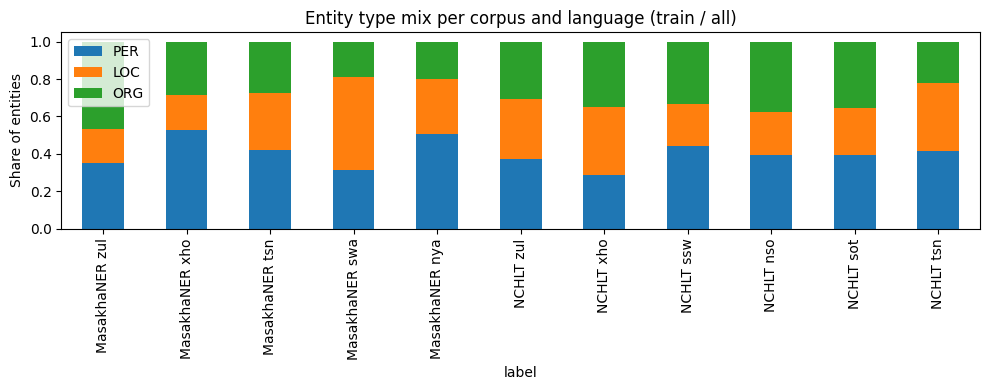

In [ ]:
plot_df = stats_df[(stats_df["split"].isin(["train", "all"]))].copy()
plot_df["label"] = plot_df["corpus"] + " " + plot_df["lang"]
ax = plot_df.set_index("label")[["PER", "LOC", "ORG"]].div(plot_df.set_index("label")[["PER", "LOC", "ORG"]].sum(axis=1), axis=0).plot(
    kind="bar", stacked=True, figsize=(10, 4))
ax.set_ylabel("Share of entities")
ax.set_title("Entity type mix per corpus and language (train / all)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_entity_mix.png", dpi=150)
plt.show()

### 5.3 Sentence length

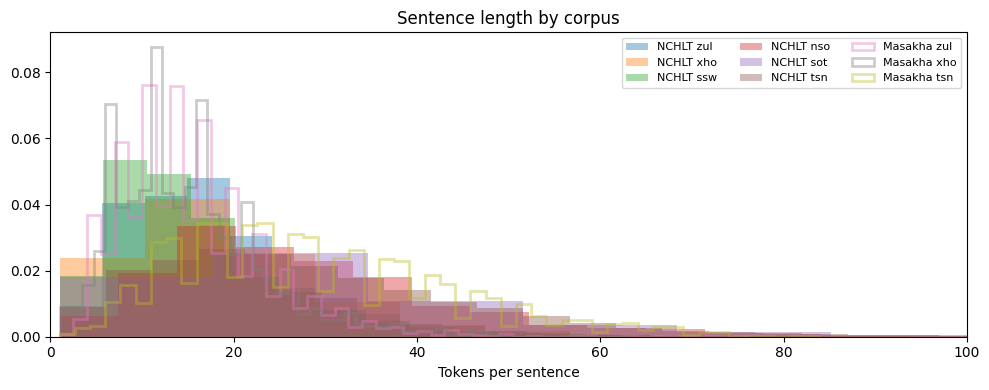

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for lang, s in nchlt_h.items():
    if s:
        ax.hist([len(x["tokens"]) for x in s], bins=50, alpha=0.4, label=f"NCHLT {lang}", density=True)
for lang in NEWS_TARGETS:
    ax.hist([len(x["tokens"]) for x in masakhane_h[lang]["train"]], bins=50, alpha=0.4, label=f"Masakha {lang}", density=True, histtype="step", linewidth=2)
ax.set_xlabel("Tokens per sentence")
ax.set_xlim(0, 100)
ax.legend(ncol=3, fontsize=8)
ax.set_title("Sentence length by corpus")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_sentence_length.png", dpi=150)
plt.show()

### 5.4 Data quality checks (including the Sesotho question)

Things to look for:

- **Invalid BIO sequences:** an `I-` tag without a preceding `B-` of the same type.
- **Very long or empty sentences:** may mean broken sentence boundaries.
- **Unusually low entity density:** compare Sesotho with the other NCHLT languages.
- **Duplicates:** identical sentences inside a corpus.

In [ ]:
def quality_report(sents):
    invalid_bio = 0
    for s in sents:
        prev = "O"
        for t in s["tags"]:
            if t.startswith("I-") and not (prev.endswith(t[2:]) and prev != "O"):
                invalid_bio += 1
            prev = t
    lengths = [len(s["tokens"]) for s in sents]
    dup = len(sents) - len({" ".join(s["tokens"]) for s in sents})
    return {"sentences": len(sents), "invalid_I_tags": invalid_bio,
            "empty_or_1_token": sum(l <= 1 for l in lengths),
            "over_100_tokens": sum(l > 100 for l in lengths),
            "duplicates": dup}

qrows = [{"corpus": "NCHLT", "lang": l, **quality_report(s)} for l, s in nchlt_h.items()]
qrows += [{"corpus": "MasakhaNER", "lang": l, **quality_report(masakhane_h[l]["train"])} for l in MASAKHANE_LANGS]
quality_df = pd.DataFrame(qrows)
quality_df

,corpus,lang,sentences,invalid_I_tags,empty_or_1_token,over_100_tokens,duplicates
0,NCHLT,zul,10955,0,4,10,97
1,NCHLT,xho,6283,0,4,10,103
2,NCHLT,ssw,10797,0,51,13,273
3,NCHLT,nso,7116,0,9,47,134
4,NCHLT,sot,9471,0,4,60,108
5,NCHLT,tsn,7943,0,5,61,169
6,MasakhaNER,zul,5848,6,1,0,5
7,MasakhaNER,xho,5718,2,3,0,213
8,MasakhaNER,tsn,3489,0,2,0,6
9,MasakhaNER,swa,6593,0,5,1,27


### 5.5 Tokenizer fertility

Fertility is the average number of subword tokens per word; the split-word ratio is the share of words split into more than one piece. They differ by language (Nguni conjunctive writing tends to give longer words) and are a likely confound for the exposure effect (Rust et al., 2021). Both are stored as per-language covariates.

XLM-R-base and AfroXLMR-base share the same tokenizer, so these numbers vary by language, not by model.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def fertility(sents, max_sents=2000):
    pieces, splits, words = 0, 0, 0
    for s in sents[:max_sents]:
        for w in s["tokens"]:
            n = len(tokenizer.tokenize(w))
            pieces += n
            splits += n > 1
            words += 1
    return {"fertility": round(pieces / max(words, 1), 3), "split_word_ratio": round(splits / max(words, 1), 3)}

frows = [{"corpus": "NCHLT", "lang": l, **fertility(s)} for l, s in nchlt_h.items() if s]
frows += [{"corpus": "MasakhaNER", "lang": l, **fertility(masakhane_h[l]["train"])} for l in MASAKHANE_LANGS]
fert_df = pd.DataFrame(frows)
fert_df.to_csv(RESULTS_DIR / "covariate_fertility.csv", index=False)
fert_df

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,corpus,lang,fertility,split_word_ratio
0,NCHLT,zul,2.706,0.846
1,NCHLT,xho,2.755,0.831
2,NCHLT,ssw,2.797,0.861
3,NCHLT,nso,1.884,0.522
4,NCHLT,sot,1.834,0.508
5,NCHLT,tsn,1.855,0.501
6,MasakhaNER,zul,2.428,0.773
7,MasakhaNER,xho,2.509,0.806
8,MasakhaNER,tsn,1.773,0.479
9,MasakhaNER,swa,1.514,0.363


### 5.6 Entity overlap between corpora

Entity overlap predicted African NER transfer better than genetic distance in Beukman & Fokam (2023). It is therefore measured for every source–target pair as a control.

**Definition.** The share of the target test set's unique entity strings (lower-cased) that also appear in the source training data.

The matrix itself is computed in section 6, after the splits exist. The function is defined here.

In [ ]:
def entity_strings(sents):
    out = set()
    for s in sents:
        for etype, a, b in entity_spans(s["tags"]):
            out.add(" ".join(s["tokens"][a:b]).lower())
    return out

def entity_overlap(source_sents, target_sents):
    src, tgt = entity_strings(source_sents), entity_strings(target_sents)
    return len(src & tgt) / max(len(tgt), 1)

### 5.7 Published baselines (for later comparison)

From MasakhaNER 2.0 (Adelani et al., 2022), Table 6. These runs used **mDeBERTaV3, not AfroXLMR**, so treat them as reference points rather than direct competitors.

| Target | Best single source (F1) | English source | In-language (Table 6) |
|---|---|---|---|
| zul | 82.1 (xho) | 44.7 | 88.6 |
| xho | 83.7 (zul) | 24.5 | 90.8 |
| tsn | 73.3 (German); Swahili 73.1 | 65.8 | 88.7 |

**Before citing any of these numbers, check them against the PDF.** Some of these table values came from text extraction.

In [ ]:
PUBLISHED_BASELINE = pd.DataFrame([
    ("zul", "xho", 82.1, 44.7, 88.6),
    ("xho", "zul", 83.7, 24.5, 90.8),
    ("tsn", "deu", 73.3, 65.8, 88.7),
], columns=["target", "best_source", "best_source_f1", "english_f1", "in_language_f1"])
PUBLISHED_BASELINE["transfer_ratio"] = (PUBLISHED_BASELINE["best_source_f1"] / PUBLISHED_BASELINE["in_language_f1"]).round(3)
PUBLISHED_BASELINE

,target,best_source,best_source_f1,english_f1,in_language_f1,transfer_ratio
0,zul,xho,82.1,44.7,88.6,0.927
1,xho,zul,83.7,24.5,90.8,0.922
2,tsn,deu,73.3,65.8,88.7,0.826


### 5.8 EDA summary

Sections 5.1 to 5.7 describe the **raw** data as loaded. Duplicate sentences found here were removed in section 6.0 before any split or sample was drawn; the sizes marked "after dedup" below are the ones used in all experiments.

- **Corpus sizes as loaded:**
  - *MasakhaNER 2.0* (train / dev / test sentences): zul 5,848 / 836 / 1,670; xho 5,718 / 817 / 1,633; tsn 3,489 / 499 / 996; swa 6,593 / 942 / 1,883; nya 6,250 / 893 / 1,785. The Hugging Face loading script is no longer supported, so all five languages were loaded from the GitHub files instead.
  - *NCHLT* (all sentences, no official split): zul 10,955; ssw 10,797; sot 9,471; tsn 7,943; nso 7,116; xho 6,283.
  - **After dedup (section 6.0):** NCHLT zul 10,851; ssw 10,512; sot 9,358; tsn 7,768; nso 6,980; xho 6,174. Our fixed 80/10/10 split (seed 802) then gives train sizes of 8,680 (zul), 8,409 (ssw), 7,486 (sot), 6,214 (tsn), 5,584 (nso) and 4,939 (xho). MasakhaNER training sets lose 5 (zul), 469 (xho), 8 (tsn), 41 (swa) and 89 (nya) sentences; the official test sets are unchanged.
  - The smallest training set after dedup is MasakhaNER Setswana (3,481), so a source cap of 3,000 sentences is feasible for every source and equalises training size across them.

- **Setswana train size (3,489 or 3,289?):** 3,489 as loaded. This matches the paper (Tables 1 and 7); the 3,289 on the Hugging Face card's split table disagrees with both the paper and the data we loaded, so the report uses the paper's figure. After removing duplicates the Setswana training set used in experiments has 3,481 sentences. Dev is 499 (498 after dedup) and test is 996.

- **NCHLT format issues found:**
  - No parsing changes were needed. Files are tab-separated token/tag with blank lines between sentences, and the parser reads them directly from the ZIPs.
  - Tags are `OUT`, `B-/I-PERS`, `B-/I-LOC`, `B-/I-ORG` and `B-/I-MISC`. There are **no invalid `I-` sequences** in any NCHLT language.
  - `MISC` is the largest entity class in every NCHLT language (for example, 10,805 `B-MISC` in zul, more than any single PER/LOC/ORG count). It has no counterpart in MasakhaNER, so it is masked as `IGN` (excluded from training loss and scoring). This removes 4.2% to 11.2% of tokens per language (sot 4.2%, nso 4.9%, tsn 6.5%, ssw 7.0%, zul 9.1%, xho 11.2%).
  - MasakhaNER has a few invalid `I-` tags (zul 6, xho 2), which is negligible.

- **Sesotho quality findings:**
  - Sesotho does not look anomalous on the checks run. Invalid BIO sequences: 0. Empty or one-token sentences: 4 (zul 4, xho 4, tsn 5). Duplicate sentences: 108 (1.1%).
  - Entity density is mid-range: 50.5% of sentences contain an entity (xho 35.0%, tsn 37.3%, zul 55.6%, ssw 59.6%, nso 62.3%). Entity spans per 1,000 tokens are about 29, close to xho (28) and above tsn (21).
  - Sesotho shares a trait with Sepedi and Setswana: sentences are long (mean about 28 tokens, against 16 to 19 for the Nguni languages), and 47 to 61 sentences per language exceed 100 tokens (zul and xho have 10). These may be sentence-boundary errors and will be truncated at `MAX_LENGTH = 128` subwords.
  - Siswati has the worst duplication (273 duplicate sentences, 2.5%) and 51 empty or one-token sentences.
  - **Not checked:** annotation correctness. These are structural checks only, with no manual review of the labels.

- **Fertility pattern (Nguni vs Sotho-Tswana):**
  - Nguni (conjunctive writing) words split into far more subwords: NCHLT zul/xho/ssw have a fertility of 2.71 / 2.76 / 2.80 and 83% to 86% of words are split. MasakhaNER zul/xho are 2.43 / 2.51 (77% and 81% split).
  - Sotho-Tswana (disjunctive) sits much lower: NCHLT nso/sot/tsn are 1.88 / 1.83 / 1.86 (50% to 52% split), and MasakhaNER tsn is 1.77 (48%).
  - Swahili is lowest (1.51, 36% split). Chichewa is high (2.26, 76%).
  - Sentences are shorter in words for Nguni but each word is longer, so sentence length in subwords comes out similar across the two clusters (about 50 to 52 for NCHLT zul and sot). The 128-subword limit should therefore bite mainly on the over-100-word sentences above, but truncation has not yet been measured.

- **Anything that changes the design:**
  - **Duplicate leakage (fixed, section 6.0).** Before the fix, 1.2% to 3.8% of NCHLT test sentences also occurred in the same language's training split, and **15.6% of the official MasakhaNER Xhosa test set (254 of 1,633 sentences) occurred in its training set**; other MasakhaNER languages were 0.0% to 0.7%. The fix removes exact duplicates (lower-cased, whitespace-normalised) from NCHLT before the split, and removes from MasakhaNER dev and train any sentence that also occurs in test or dev, keeping the official test sets unchanged so results stay comparable with published numbers. Experiments were re-run after the fix; the earlier results are kept separately as `v1_with_duplicates`.
  - The `IGN` masking means NCHLT and MasakhaNER are scored on PER, LOC and ORG only, and NCHLT test sentences with heavy `MISC` content contribute little.
  - Entity overlap (section 6, computed on the deduplicated data) is strongly tied to domain: same-language, cross-domain pairs overlap only about 0.03 to 0.12 (for example, NCHLT zul to MasakhaNER zul 0.05, NCHLT xho to MasakhaNER xho 0.03), while related Sotho-Tswana government corpora reach 0.10 to 0.22. Relatedness and domain are therefore partly confounded, so entity overlap stays in the models as a covariate. Removing the duplicates also lowered the MasakhaNER Xhosa train-to-test overlap from 0.30 to 0.21, which shows the leakage had been inflating this covariate too.
  - Any claim about Setswana as a target depends on MasakhaNER (3,481 training sentences after dedup) and NCHLT (7,768 sentences after dedup), which differ in domain and in density (about 21 entity spans per 1,000 tokens in NCHLT).

## 6. Splits and sampling

**NCHLT** has no official split. It is shuffled once with a fixed seed (`NCHLT_SPLIT_SEED`) and split 80/10/10. The split is saved to disk so every run uses the same one; never regenerate it after experiments start.

**MasakhaNER 2.0** keeps its published splits.

**Source cap.** Each source's training data is capped at `SOURCE_CAP` sentences, resampled with each experiment seed, so data size does not confound the comparison.

**Few-shot samples.** The k target sentences come from the target's MasakhaNER train split, and are also resampled per seed (Zhao et al., 2021 show that which shots are sampled matters a lot).

### 6.0 Removing duplicate sentences (train/test leakage fix)

**Problem.** Section 5.4 found identical sentences inside the corpora (NCHLT: 97 to 273 per language; MasakhaNER Xhosa: 213). Measured before this fix, these sat on both sides of a split: 1.2% to 3.8% of NCHLT test sentences also appeared in that language's training split, and **15.6% of the official MasakhaNER Xhosa test set (254 of 1,633 sentences) appeared in its training set**; other MasakhaNER languages were 0.0% to 0.7%. A model can score those test sentences by memorisation, which inflates in-language F1 and, through the transfer ratio, every ratio that uses it as denominator.

**Fix.** Sentences are compared by a normalised key (tokens joined by single spaces, lower-cased). Dedup runs once, before any split or sample is drawn.

- **NCHLT** (no official split): exact duplicates are removed inside each language, keeping the first occurrence, and only then is the 80/10/10 split made (seed 802, section 6). A sentence can therefore sit in only one split. Splits are saved under new file names (`nchlt_<lang>_dedup.json`) so the old, duplicate-containing split files are never reloaded.
- **MasakhaNER** (official splits): the **official test sets are left unchanged**, so our scores stay comparable with the published baselines. Instead, any dev sentence that also occurs in test is removed, and any train sentence that also occurs in test or dev is removed. Duplicates inside dev and inside train are also removed (first occurrence kept). Duplicates inside a test set are kept, because they cause no train/test leakage.
- **Not changed.** Overlap between different corpora (for example NCHLT vs MasakhaNER of the same language) is not removed. The two come from different domains, and entity overlap between them is already measured as a covariate (section 6).
- **Checks.** The cell asserts that no sentence key is shared between train, dev and test of any corpus, and prints how many sentences were removed per corpus.

Section 5 (EDA) is deliberately left on the raw, un-deduplicated data, so it keeps documenting the problem; every number in sections 6 to 10 uses the deduplicated data. All experiments were re-run after this fix, and the earlier results (with leakage) are kept in the Drive backup under `v1_with_duplicates/`.

In [ ]:
def sent_key(s):
    # normalised identity of a sentence: tokens joined by single spaces, lower-cased
    return " ".join(" ".join(s["tokens"]).lower().split())

def dedupe(sents, drop_keys=()):
    # drop sentences whose key is in drop_keys or already seen; keep the first occurrence
    seen, kept = set(drop_keys), []
    for s in sents:
        k = sent_key(s)
        if k in seen:
            continue
        seen.add(k)
        kept.append(s)
    return kept

# NCHLT: dedupe the whole corpus first; the 80/10/10 split is made afterwards (next cells)
nchlt_dd = {lang: dedupe(s) for lang, s in nchlt_h.items()}

# MasakhaNER: keep the official test sets as they are; clean dev and train against them
masakhane_dd = {}
for lang, d in masakhane_h.items():
    test_keys = {sent_key(s) for s in d["test"]}
    dev_dd = dedupe(d["dev"], test_keys)
    train_dd = dedupe(d["train"], test_keys | {sent_key(s) for s in dev_dd})
    masakhane_dd[lang] = {"train": train_dd, "dev": dev_dd, "test": d["test"]}

for lang, d in masakhane_dd.items():  # leakage check (NCHLT is checked after its split)
    keys = {k: {sent_key(s) for s in d[k]} for k in ("train", "dev", "test")}
    assert not (keys["train"] & keys["test"]) and not (keys["train"] & keys["dev"]) and not (keys["dev"] & keys["test"]), lang

rows = [{"corpus": "nchlt", "lang": lang, "before": len(nchlt_h[lang]), "after": len(nchlt_dd[lang]),
         "removed": len(nchlt_h[lang]) - len(nchlt_dd[lang])} for lang in nchlt_h]
for lang in masakhane_h:
    for split in ("train", "dev"):
        b, a = len(masakhane_h[lang][split]), len(masakhane_dd[lang][split])
        rows.append({"corpus": f"masakhaner {split}", "lang": lang, "before": b, "after": a, "removed": b - a})
dedup_report = pd.DataFrame(rows)
dedup_report["pct_removed"] = (100 * dedup_report.removed / dedup_report.before).round(1)
dedup_report.to_csv(RESULTS_DIR / "dedup_report.csv", index=False)
dedup_report

,corpus,lang,before,after,removed,pct_removed
0,nchlt,zul,10955,10851,104,0.9
1,nchlt,xho,6283,6174,109,1.7
2,nchlt,ssw,10797,10512,285,2.6
3,nchlt,nso,7116,6980,136,1.9
4,nchlt,sot,9471,9358,113,1.2
5,nchlt,tsn,7943,7768,175,2.2
6,masakhaner train,zul,5848,5843,5,0.1
7,masakhaner dev,zul,836,836,0,0.0
8,masakhaner train,xho,5718,5249,469,8.2
9,masakhaner dev,xho,817,817,0,0.0


In [ ]:
# BEFORE the fix: how many test/dev sentences also occur in train?
# NCHLT: rebuild the original random 80/10/10 split of the RAW corpus (same seed and procedure as section 6),
# without saving it. MasakhaNER: the official splits as downloaded.
def _key(s):
    return " ".join(" ".join(s["tokens"]).lower().split())

def _raw_nchlt_split(sents):
    idx = list(range(len(sents)))
    random.Random(NCHLT_SPLIT_SEED).shuffle(idx)
    n = len(idx); n_tr, n_dev = int(NCHLT_SPLIT[0] * n), int(NCHLT_SPLIT[1] * n)
    return {"train": [sents[i] for i in idx[:n_tr]], "dev": [sents[i] for i in idx[n_tr:n_tr + n_dev]],
            "test": [sents[i] for i in idx[n_tr + n_dev:]]}

raw_splits = {("nchlt", lang): _raw_nchlt_split(s) for lang, s in nchlt_h.items() if s}
raw_splits.update({("masakhaner", lang): d for lang, d in masakhane_h.items()})

rows = []
for (corpus, lang), d in raw_splits.items():
    tr = {_key(s) for s in d["train"]}
    rows.append({"corpus": corpus, "lang": lang,
                 "test_in_train": sum(_key(s) in tr for s in d["test"]), "n_test": len(d["test"]),
                 "dev_in_train": sum(_key(s) in tr for s in d["dev"]), "n_dev": len(d["dev"])})
leak_before = pd.DataFrame(rows)
leak_before["pct_test_leaked"] = (100 * leak_before.test_in_train / leak_before.n_test).round(1)
leak_before.to_csv(RESULTS_DIR / "leakage_before_fix.csv", index=False)
leak_before

In [ ]:
def make_or_load_nchlt_split(lang, sents):
    path = SPLIT_DIR / f"nchlt_{lang}_dedup.json"   # dedup suffix: old splits (with duplicates) are never reloaded
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    idx = list(range(len(sents)))
    random.Random(NCHLT_SPLIT_SEED).shuffle(idx)
    n = len(idx)
    n_tr, n_dev = int(NCHLT_SPLIT[0] * n), int(NCHLT_SPLIT[1] * n)
    split = {"train": [sents[i] for i in idx[:n_tr]],
             "dev": [sents[i] for i in idx[n_tr:n_tr + n_dev]],
             "test": [sents[i] for i in idx[n_tr + n_dev:]]}
    path.write_text(json.dumps(split, ensure_ascii=False), encoding="utf-8")
    return split

# Split the DEDUPLICATED corpus (section 6.0)
nchlt = {lang: make_or_load_nchlt_split(lang, s) for lang, s in nchlt_dd.items() if s}
for lang, d in nchlt.items():
    keys = {k: {sent_key(s) for s in d[k]} for k in ("train", "dev", "test")}
    assert not (keys["train"] & keys["test"]) and not (keys["train"] & keys["dev"]) and not (keys["dev"] & keys["test"]), lang
    print(lang, {k: len(v) for k, v in d.items()}, "| no sentence shared between splits")

zul {'train': 8680, 'dev': 1085, 'test': 1086} | no sentence shared between splits
xho {'train': 4939, 'dev': 617, 'test': 618} | no sentence shared between splits
ssw {'train': 8409, 'dev': 1051, 'test': 1052} | no sentence shared between splits
nso {'train': 5584, 'dev': 698, 'test': 698} | no sentence shared between splits
sot {'train': 7486, 'dev': 935, 'test': 937} | no sentence shared between splits
tsn {'train': 6214, 'dev': 776, 'test': 778} | no sentence shared between splits


In [ ]:
# One registry of all corpora: key = (corpus, lang) -> {"train", "dev", "test"}
CORPORA = {}
for lang, d in nchlt.items():
    CORPORA[("nchlt", lang)] = d
for lang, d in masakhane_dd.items():   # deduplicated against test/dev (section 6.0); official test sets unchanged
    CORPORA[("masakhaner", lang)] = d

DOMAIN = {"nchlt": "government", "masakhaner": "news"}

def sample(sents, n, seed):
    if n is None or n >= len(sents):
        return list(sents)
    rng = random.Random(seed)
    return rng.sample(list(sents), n)

if DRY_RUN:
    # Shrink dev/test sets so a dry run is fast; train stays full so SOURCE_CAP decides the size
    for key in CORPORA:
        CORPORA[key] = {k: (v if k == "train" else v[:200]) for k, v in CORPORA[key].items()}

print(sorted(CORPORA.keys()))

[('masakhaner', 'nya'), ('masakhaner', 'swa'), ('masakhaner', 'tsn'), ('masakhaner', 'xho'), ('masakhaner', 'zul'), ('nchlt', 'nso'), ('nchlt', 'sot'), ('nchlt', 'ssw'), ('nchlt', 'tsn'), ('nchlt', 'xho'), ('nchlt', 'zul')]


## 7. Model and training utilities

The approach is standard token classification with Hugging Face `Trainer`:

- **Label alignment:** only the first subword of each word carries the label; the rest get `-100`. `IGN` tokens also get `-100`.
- **Predictions:** mapped back to words using the first subword.
- **Scoring:** entity-level micro-F1 on PER/LOC/ORG with exact span match, conlleval-style, implemented below so per-sentence counts can feed the bootstrap tests. `seqeval` gives the same result and can be used as a cross-check.

In [ ]:
import torch
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments, set_seed)
from datasets import Dataset

print("CUDA available:", torch.cuda.is_available())
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)  # loaded here too, so training does not depend on the EDA cells

def encode(sents):
    enc = tokenizer([s["tokens"] for s in sents], is_split_into_words=True,
                    truncation=True, max_length=MAX_LENGTH)
    labels = []
    for i, s in enumerate(sents):
        word_ids = enc.word_ids(batch_index=i)
        prev, lab = None, []
        for w in word_ids:
            if w is None or w == prev:
                lab.append(-100)
            else:
                t = s["tags"][w]
                lab.append(-100 if t == IGNORE else LABEL2ID[t])
            prev = w
        labels.append(lab)
    enc["labels"] = labels
    return Dataset.from_dict(dict(enc))

def new_model():
    return AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID)

def train(model, train_sents, seed, epochs, out_dir):
    set_seed(seed)
    args = TrainingArguments(
        output_dir=str(out_dir), seed=seed, save_strategy="no", report_to=[],
        logging_steps=50, fp16=torch.cuda.is_available(),
        **{**TRAIN_ARGS, "num_train_epochs": epochs})
    trainer = Trainer(model=model, args=args, train_dataset=encode(train_sents),
                      data_collator=DataCollatorForTokenClassification(tokenizer))
    trainer.train()
    return model

CUDA available: True


In [ ]:
@torch.no_grad()
def predict(model, sents, batch_size=32):
    model.eval()
    device = next(model.parameters()).device
    preds = []
    for i in range(0, len(sents), batch_size):
        batch = sents[i:i + batch_size]
        enc = tokenizer([s["tokens"] for s in batch], is_split_into_words=True,
                        truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors="pt")
        logits = model(**{k: v.to(device) for k, v in enc.items()}).logits.argmax(-1).cpu().numpy()
        for j, s in enumerate(batch):
            word_ids = enc.word_ids(batch_index=j)
            out, seen = ["O"] * len(s["tokens"]), set()
            for pos, w in enumerate(word_ids):
                if w is not None and w not in seen:
                    out[w] = ID2LABEL[int(logits[j][pos])]
                    seen.add(w)
            preds.append(out)  # words cut off by truncation stay "O"
    return preds

In [ ]:
def mask_excluded(gold, pred):
    # At excluded (IGN) gold positions, set both gold and pred to "O".
    g2, p2 = [], []
    for g, p in zip(gold, pred):
        if g == IGNORE:
            g2.append("O"); p2.append("O")
        else:
            g2.append(g); p2.append(p)
    return g2, p2

def sentence_counts(gold_sents, pred_tags):
    # Per-sentence TP/FP/FN for each entity type (used by the F1 and the bootstrap).
    rows = []
    for s, p in zip(gold_sents, pred_tags):
        g, p = mask_excluded(s["tags"], p)
        gs, ps = set(entity_spans(g)), set(entity_spans(p))
        row = {}
        for etype in ["PER", "LOC", "ORG"]:
            gt = {e for e in gs if e[0] == etype}
            pt = {e for e in ps if e[0] == etype}
            row[f"tp_{etype}"] = len(gt & pt)
            row[f"fp_{etype}"] = len(pt - gt)
            row[f"fn_{etype}"] = len(gt - pt)
        rows.append(row)
    return pd.DataFrame(rows)

def f1_from_counts(df):
    out = {}
    tp = fp = fn = 0
    for etype in ["PER", "LOC", "ORG"]:
        a, b, c = df[f"tp_{etype}"].sum(), df[f"fp_{etype}"].sum(), df[f"fn_{etype}"].sum()
        p = a / (a + b) if a + b else 0.0
        r = a / (a + c) if a + c else 0.0
        out[f"f1_{etype}"] = 100 * 2 * p * r / (p + r) if p + r else 0.0
        tp, fp, fn = tp + a, fp + b, fn + c
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    out["precision"], out["recall"] = 100 * p, 100 * r
    out["f1"] = 100 * 2 * p * r / (p + r) if p + r else 0.0
    return out

## 8. Experiment plan

**Zero-shot.** 11 source models (6 NCHLT, 3 MasakhaNER targets, plus Swahili and Chichewa) × 3 seeds = 33 training runs. Each model is evaluated on all 9 test sets: 6 government and 3 news.

**Few-shot (RQ3).** Each news target gets two source models, which are then fine-tuned further on 100 or 500 target sentences:

| News target | Sister-language source | Same-language government source |
|---|---|---|
| zul | MasakhaNER xho (news) | NCHLT zul |
| xho | MasakhaNER zul (news) | NCHLT xho |
| tsn | NCHLT nso (government, since there is no Sotho-Tswana news data) | NCHLT tsn |

That is 3 targets × 2 sources × 2 sizes × 3 seeds = 36 runs. To avoid saving large checkpoints, few-shot training happens straight after the matching source model is trained.

In [ ]:
SOURCES = [("nchlt", l) for l in TARGET_LANGS] + [("masakhaner", l) for l in ["zul", "xho", "tsn", "swa", "nya"]]
TEST_SETS = [("nchlt", l) for l in TARGET_LANGS] + [("masakhaner", l) for l in NEWS_TARGETS]

FEWSHOT_PLAN = {
    ("masakhaner", "xho"): [("masakhaner", "zul")],
    ("nchlt", "zul"):      [("masakhaner", "zul")],
    ("masakhaner", "zul"): [("masakhaner", "xho")],
    ("nchlt", "xho"):      [("masakhaner", "xho")],
    ("nchlt", "nso"):      [("masakhaner", "tsn")],
    ("nchlt", "tsn"):      [("masakhaner", "tsn")],
}

if DRY_RUN:
    SOURCES = [("masakhaner", "xho"), ("nchlt", "zul")]

# Keep only corpora that actually loaded, and say loudly if any were dropped
dropped = [c for c in SOURCES + TEST_SETS if c not in CORPORA]
SOURCES = [s for s in SOURCES if s in CORPORA]
TEST_SETS = [t for t in TEST_SETS if t in CORPORA]
if dropped:
    print("WARNING: corpora missing from CORPORA and dropped from the plan:", sorted(set(dropped)))

plan = pd.DataFrame([
    {"source_corpus": sc, "source_lang": sl, "test_corpus": tc, "test_lang": tl,
     "relatedness": relatedness(sl, tl),
     "domain_match": DOMAIN[sc] == DOMAIN[tc],
     "target_exposure": LANGS.loc[tl, "exposure_binary"]}
    for (sc, sl) in SOURCES for (tc, tl) in TEST_SETS])
print(f"{len(SOURCES)} sources x {len(SEEDS)} seeds = {len(SOURCES) * len(SEEDS)} zero-shot training runs")
print(f"{len(plan)} source-test pairs per seed")
plan.groupby(["relatedness", "domain_match"]).size().unstack(fill_value=0)

11 sources x 3 seeds = 33 zero-shot training runs
99 source-test pairs per seed


domain_match,False,True
relatedness,,
other_bantu,12,6
other_southern_bantu,18,22
same_cluster,12,14
same_language,6,9


In [ ]:
# Entity overlap covariate for every source-test pair (uses full source train and test sets)
plan["entity_overlap"] = [
    entity_overlap(CORPORA[(r.source_corpus, r.source_lang)]["train"], CORPORA[(r.test_corpus, r.test_lang)]["test"])
    for r in plan.itertuples()]
plan.to_csv(RESULTS_DIR / "covariate_entity_overlap.csv", index=False)
plan.pivot_table(index=["source_corpus", "source_lang"], columns=["test_corpus", "test_lang"], values="entity_overlap").round(2)

test_corpus               masakhaner             nchlt                              
test_lang                        tsn   xho   zul   nso   sot   ssw   tsn   xho   zul
source_corpus source_lang                                                           
masakhaner    nya               0.02  0.01  0.02  0.02  0.03  0.01  0.04  0.01  0.01
              swa               0.10  0.01  0.02  0.05  0.06  0.02  0.06  0.02  0.01
              tsn               0.31  0.02  0.05  0.06  0.05  0.02  0.12  0.01  0.01
              xho               0.03  0.21  0.05  0.02  0.02  0.01  0.03  0.09  0.02
              zul               0.08  0.10  0.14  0.02  0.02  0.03  0.04  0.03  0.04
nchlt         nso               0.11  0.02  0.03  0.45  0.19  0.05  0.20  0.04  0.03
              sot               0.09  0.01  0.02  0.16  0.52  0.04  0.22  0.04  0.04
              ssw               0.06  0.02  0.04  0.06  0.12  0.49  0.10  0.08  0.09
              tsn               0.11  0.01  0.02  0.10  0.14  0.03  0.52  0.02  0.02
              xho               0.01  0.03  0.01  0.03  0.03  0.03  0.04  0.43  0.03
              zul               0.06  0.02  0.05  0.06  0.10  0.11  0.08  0.07  0.41

## 9. Run experiments

The runner is **resumable**. Every finished evaluation is appended to `results/results.csv`, and finished runs are skipped next time. This matters on Kaggle and Colab, where sessions time out.

Each row records the source, test set, seed, few-shot size k (0 for zero-shot) and the scores. Per-sentence counts are saved to `results/per_sentence/` for the bootstrap tests.

**Surviving a runtime reset.** Colab wipes `/content` when it recycles a runtime. So the main loop copies `results/` to Drive (`COS802_project_backup/v2_deduplicated/results/`, mounted in section 2) **after every source**, and the cell before the loop copies the backup back if this runtime has no results yet. After a reset: run the notebook from the top (sections 1 to 8 rebuild the data and splits identically), then the restore cell, then the loop, which picks up where it stopped. At most one training run is lost.

The loop ends with an accounting check: 333 evaluations expected (297 zero-shot + 36 few-shot), with none missing, unexpected or duplicated.

In [ ]:
RESULTS_FILE = RESULTS_DIR / "results.csv"

def done_keys():
    if not RESULTS_FILE.exists():
        return set()
    df = pd.read_csv(RESULTS_FILE)
    return set(zip(df.source_corpus, df.source_lang, df.test_corpus, df.test_lang, df.seed, df.k))

def evaluate_and_log(model, src, test, seed, k):
    gold = CORPORA[test]["test"]
    counts = sentence_counts(gold, predict(model, gold))
    run_id = f"{src[0]}-{src[1]}__{test[0]}-{test[1]}__s{seed}__k{k}"
    counts.to_csv(PRED_DIR / f"{run_id}.csv", index=False)
    row = {"run_id": run_id, "source_corpus": src[0], "source_lang": src[1],
           "test_corpus": test[0], "test_lang": test[1], "seed": seed, "k": k,
           "n_test": len(gold), **f1_from_counts(counts)}
    pd.DataFrame([row]).to_csv(RESULTS_FILE, mode="a", header=not RESULTS_FILE.exists(), index=False)
    return row

def run_source(src, seed):
    done = done_keys()
    zs_needed = [t for t in TEST_SETS if (*src, *t, seed, 0) not in done]
    fs_needed = [(t, k) for t in FEWSHOT_PLAN.get(src, []) for k in FEWSHOT_SIZES if (*src, *t, seed, k) not in done and t in CORPORA]
    if not zs_needed and not fs_needed:
        print("skip", src, seed)
        return
    train_sents = sample(CORPORA[src]["train"], SOURCE_CAP, seed)
    model = new_model()
    if torch.cuda.is_available():
        model = model.cuda()
    train(model, train_sents, seed, TRAIN_ARGS["num_train_epochs"], RESULTS_DIR / "tmp")
    for t in zs_needed:
        r = evaluate_and_log(model, src, t, seed, 0)
        print(f"zero-shot {src} -> {t} seed {seed}: F1 {r['f1']:.1f}")
    for t, k in fs_needed:
        fs_model = copy.deepcopy(model)
        shots = sample(CORPORA[t]["train"], k, seed + k)
        train(fs_model, shots, seed, FEWSHOT_EPOCHS[k], RESULTS_DIR / "tmp")
        r = evaluate_and_log(fs_model, src, t, seed, k)
        print(f"few-shot k={k} {src} -> {t} seed {seed}: F1 {r['f1']:.1f}")
        del fs_model
    del model
    torch.cuda.empty_cache()

In [ ]:
# ---------- Resume after a runtime reset ----------
# A recycled Colab runtime starts with an empty results/ folder. If Drive holds a backup, copy it back so the
# loop below skips every evaluation that already finished (results.csv and the per-sentence counts).
import shutil
if BACKUP_RESULTS is not None and (BACKUP_RESULTS / "results.csv").exists() and not RESULTS_FILE.exists():
    shutil.copytree(BACKUP_RESULTS, RESULTS_DIR, dirs_exist_ok=True)
    print("restored", len(pd.read_csv(RESULTS_FILE)), "evaluations from", BACKUP_RESULTS)
elif RESULTS_FILE.exists():
    print("local results found:", len(pd.read_csv(RESULTS_FILE)), "evaluations; nothing restored")
else:
    print("no results yet (no local file, no Drive backup): the loop starts from scratch")

restored 333 evaluations from /content/drive/MyDrive/COS802_project_backup/v2_deduplicated/results


In [ ]:
import time, shutil
# Main loop: every seed, every source, in ONE loop. Resumable: finished evaluations are skipped
# (restore results from Drive first after a runtime reset, see the cell above).

def expected_keys():
    # every evaluation the design calls for: zero-shot (k=0) plus few-shot (k in FEWSHOT_SIZES)
    keys = {(*s, *t, seed, 0) for s in SOURCES for t in TEST_SETS for seed in SEEDS}
    keys |= {(*s, *t, seed, k) for s, ts in FEWSHOT_PLAN.items() if s in SOURCES
             for t in ts if t in CORPORA for seed in SEEDS for k in FEWSHOT_SIZES}
    return keys

def backup_results():
    # copy results to Drive after every source, so a runtime reset loses at most one training run
    if BACKUP_RESULTS is None:
        return
    try:
        shutil.copytree(RESULTS_DIR, BACKUP_RESULTS, dirs_exist_ok=True, ignore=shutil.ignore_patterns("tmp"))
    except Exception as e:
        print("Drive backup failed:", e)

expected = expected_keys()
n_zs = sum(k[-1] == 0 for k in expected)
print(f"expected evaluations: {len(expected)} = {n_zs} zero-shot + {len(expected) - n_zs} few-shot "
      f"({len(SOURCES)} sources x {len(SEEDS)} seeds = {len(SOURCES) * len(SEEDS)} training runs) | "
      f"already done: {len(done_keys() & expected)}")
if BACKUP_RESULTS is None:
    print("WARNING: Drive not mounted, results are NOT being backed up")

t0 = time.time()
for seed in SEEDS:
    for src in SOURCES:
        run_source(src, seed)
        backup_results()
    print(f"--- seed {seed} finished | {len(done_keys() & expected)}/{len(expected)} evaluations done | "
          f"{(time.time() - t0) / 60:.1f} min elapsed")

# Final accounting: nothing missing, nothing unexpected, no row logged twice
res_df = pd.read_csv(RESULTS_FILE)
missing, unexpected = expected - done_keys(), done_keys() - expected
dup_rows = res_df.duplicated(subset=["source_corpus", "source_lang", "test_corpus", "test_lang", "seed", "k"]).sum()
print(f"rows: {len(res_df)} | expected: {len(expected)} | missing: {len(missing)} | "
      f"unexpected: {len(unexpected)} | duplicate rows: {dup_rows}")
assert not missing and not unexpected and dup_rows == 0

expected evaluations: 333 = 297 zero-shot + 36 few-shot (11 sources x 3 seeds = 33 training runs) | already done: 222
skip ('nchlt', 'zul') 13
skip ('nchlt', 'xho') 13
skip ('nchlt', 'ssw') 13
skip ('nchlt', 'nso') 13
skip ('nchlt', 'sot') 13
skip ('nchlt', 'tsn') 13
skip ('masakhaner', 'zul') 13
skip ('masakhaner', 'xho') 13
skip ('masakhaner', 'tsn') 13
skip ('masakhaner', 'swa') 13
skip ('masakhaner', 'nya') 13
--- seed 13 finished | 222/333 evaluations done | 0.3 min elapsed
skip ('nchlt', 'zul') 42
skip ('nchlt', 'xho') 42
skip ('nchlt', 'ssw') 42
skip ('nchlt', 'nso') 42
skip ('nchlt', 'sot') 42
skip ('nchlt', 'tsn') 42
skip ('masakhaner', 'zul') 42
skip ('masakhaner', 'xho') 42
skip ('masakhaner', 'tsn') 42
skip ('masakhaner', 'swa') 42
skip ('masakhaner', 'nya') 42
--- seed 42 finished | 222/333 evaluations done | 0.7 min elapsed


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.520910
100,0.145979
150,0.108451
200,0.094367
250,0.074566
300,0.058919
350,0.063048
400,0.051982
450,0.045448
500,0.041794


... (61 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.523528
100,0.113958
150,0.076054
200,0.050527
250,0.040302
300,0.034995
350,0.033395
400,0.027698
450,0.019406
500,0.019690


zero-shot ('masakhaner', 'nya') -> ('nchlt', 'zul') seed 2026: F1 19.6
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'xho') seed 2026: F1 19.0
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'ssw') seed 2026: F1 28.8
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'nso') seed 2026: F1 59.1
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'sot') seed 2026: F1 36.1
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'tsn') seed 2026: F1 51.1
zero-shot ('masakhaner', 'nya') -> ('masakhaner', 'zul') seed 2026: F1 42.1
zero-shot ('masakhaner', 'nya') -> ('masakhaner', 'xho') seed 2026: F1 20.6
zero-shot ('masakhaner', 'nya') -> ('masakhaner', 'tsn') seed 2026: F1 75.4
--- seed 2026 finished | 333/333 evaluations done | 22.7 min elapsed
rows: 333 | expected: 333 | missing: 0 | unexpected: 0 | duplicate rows: 0


## 10. Results and analysis

### 10.1 Load results and compute transfer ratio

**Transfer ratio (TR)** = cross-lingual F1 ÷ the same target's in-language F1. The in-language F1 comes from the source = target run, trained with the same cap and seed, and averaged over seeds.

In [ ]:
KEYS = ["source_corpus", "source_lang", "test_corpus", "test_lang"]
res = pd.read_csv(RESULTS_FILE).merge(plan, on=KEYS, how="left")
res["rel_score"] = res["relatedness"].map(REL_SCORE)

in_lang = (res[(res.k == 0) & (res.source_corpus == res.test_corpus) & (res.source_lang == res.test_lang)]
           .groupby(["test_corpus", "test_lang"])["f1"].mean().rename("in_language_f1"))
res = res.join(in_lang, on=["test_corpus", "test_lang"])
res["transfer_ratio"] = res["f1"] / res["in_language_f1"]
res.to_csv(RESULTS_DIR / "results_enriched.csv", index=False)

zs = res[res.k == 0]
summary = zs.groupby(["source_corpus", "source_lang", "test_corpus", "test_lang"]).agg(
    f1_mean=("f1", "mean"), f1_sd=("f1", "std"), tr_mean=("transfer_ratio", "mean")).round(2)
summary

f1_mean  f1_sd  tr_mean
source_corpus source_lang test_corpus test_lang                         
masakhaner    nya         masakhaner  tsn          76.33   2.21     0.86
                                      xho          20.63   0.30     0.23
                                      zul          42.35   2.29     0.48
                          nchlt       nso          58.46   1.51     0.70
                                      sot          39.56   3.05     0.67
...                                                  ...    ...      ...
nchlt         zul         nchlt       sot          43.30   0.86     0.73
                                      ssw          52.10   1.35     0.67
                                      tsn          40.40   0.87     0.51
                                      xho          45.92   0.67     0.55
                                      zul          74.37   1.80     1.00

[99 rows x 3 columns]

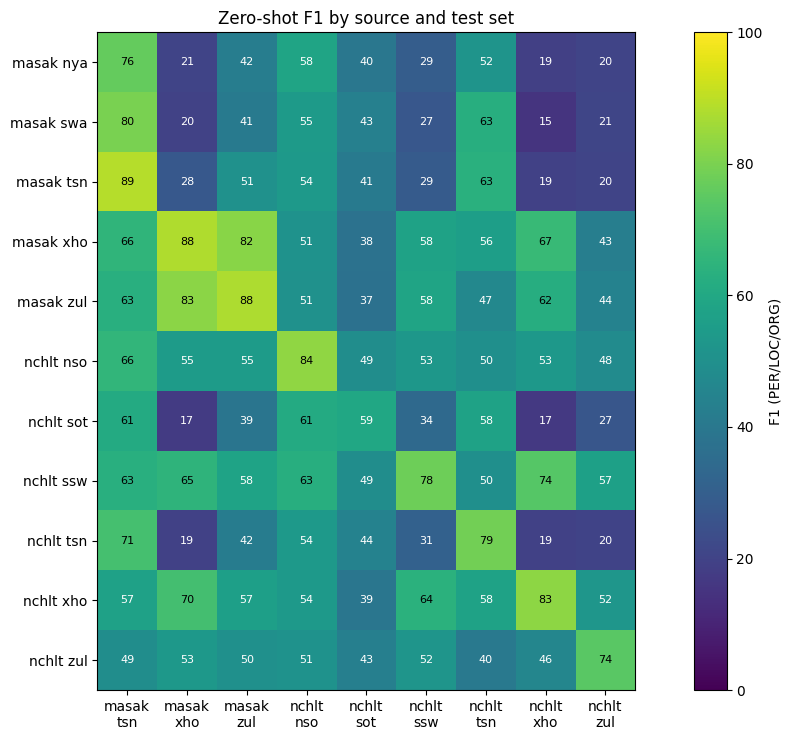

In [ ]:
# Zero-shot F1 heatmap (rows = sources, columns = test sets)
mat = zs.pivot_table(index=["source_corpus", "source_lang"], columns=["test_corpus", "test_lang"], values="f1", aggfunc="mean")
fig, ax = plt.subplots(figsize=(1.0 * mat.shape[1] + 3, 0.5 * mat.shape[0] + 2))
im = ax.imshow(mat.values, cmap="viridis", vmin=0, vmax=100)
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels([f"{c[0][:5]}\n{c[1]}" for c in mat.columns])
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels([f"{r[0][:5]} {r[1]}" for r in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v < 60 else "black", fontsize=8)
plt.colorbar(im, ax=ax, label="F1 (PER/LOC/ORG)")
ax.set_title("Zero-shot F1 by source and test set")
plt.tight_layout()
plt.savefig(FIG_DIR / "zero_shot_heatmap.png", dpi=150)
plt.show()

### 10.2 RQ1: relatedness vs domain match

The key contrast is **related source from the other domain** vs **unrelated source from the same domain**. The table shows mean F1 and transfer ratio for every relatedness × domain cell, excluding same-language same-domain (the upper bound).

In [ ]:
cross = zs[~((zs.relatedness == "same_language") & (zs.domain_match))]
rq1 = cross.groupby(["relatedness", "domain_match"]).agg(
    pairs=("f1", "size"), f1=("f1", "mean"), tr=("transfer_ratio", "mean")).round(2)
rq1 = rq1.reindex([r for r in REL_ORDER if r in rq1.index.get_level_values(0)], level=0)
rq1

pairs     f1    tr
relatedness          domain_match                    
same_language        False            18  60.96  0.73
same_cluster         False            36  56.27  0.68
                     True             42  59.00  0.76
other_southern_bantu False            54  41.36  0.51
                     True             66  43.52  0.56
other_bantu          False            36  36.88  0.49
                     True             18  46.69  0.53

### 10.3 RQ2: seen vs unseen targets

Exposure is reported two ways, absolute F1 and transfer ratio, because the literature expects them to point in different directions (H2a, H2b).

In [ ]:
rq2 = cross.merge(LANGS[["exposure_graded"]], left_on="test_lang", right_index=True)
display_rq2 = rq2.groupby(["target_exposure", "relatedness"]).agg(f1=("f1", "mean"), tr=("transfer_ratio", "mean"), pairs=("f1", "size")).round(2)
display_rq2

f1    tr  pairs
target_exposure relatedness                             
0               other_bantu           55.09  0.66     24
                other_southern_bantu  50.78  0.61     57
                same_cluster          57.80  0.71     33
                same_language         66.95  0.80      6
1               other_bantu           28.19  0.38     30
                other_southern_bantu  35.10  0.47     63
                same_cluster          57.70  0.73     45
                same_language         57.97  0.69     12

### 10.4 RQ3: few-shot learning curves

**Gap closure** = (F1 at k − F1 at k=0) ÷ (in-language F1 − F1 at k=0). A value of 1 means the gap to the in-language model is fully closed.

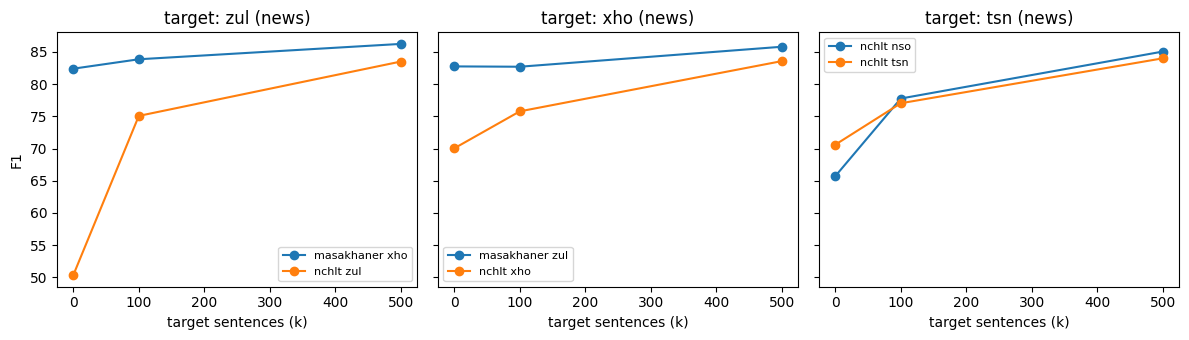

,test_lang,source_corpus,source_lang,k,f1,f1_k0,in_language_f1,gap_closure
0,tsn,nchlt,nso,0,65.706,65.706,89.024,0.000
1,tsn,nchlt,nso,100,77.760,65.706,89.024,0.517
2,tsn,nchlt,nso,500,85.052,65.706,89.024,0.830
3,tsn,nchlt,tsn,0,70.594,70.594,89.024,0.000
4,tsn,nchlt,tsn,100,77.028,70.594,89.024,0.349
5,tsn,nchlt,tsn,500,84.003,70.594,89.024,0.728
6,xho,masakhaner,zul,0,82.744,82.744,88.094,0.000
7,xho,masakhaner,zul,100,82.694,82.744,88.094,-0.009
8,xho,masakhaner,zul,500,85.796,82.744,88.094,0.570
9,xho,nchlt,xho,0,70.031,70.031,88.094,0.000


In [ ]:
fs_pairs = {(*src, *t) for src, ts in FEWSHOT_PLAN.items() for t in ts}
pair_key = list(zip(res.source_corpus, res.source_lang, res.test_corpus, res.test_lang))
curve_rows = res[[k in fs_pairs for k in pair_key]]
curves = curve_rows.groupby(["test_lang", "source_corpus", "source_lang", "k"])["f1"].mean().reset_index()

base = curves[curves.k == 0].set_index(["test_lang", "source_corpus", "source_lang"])["f1"].rename("f1_k0")
curves = curves.join(base, on=["test_lang", "source_corpus", "source_lang"]).join(in_lang.xs("masakhaner"), on="test_lang")
curves["gap_closure"] = (curves.f1 - curves.f1_k0) / (curves.in_language_f1 - curves.f1_k0)

fig, axes = plt.subplots(1, len(NEWS_TARGETS), figsize=(4 * len(NEWS_TARGETS), 3.5), sharey=True)
for ax, tl in zip(np.atleast_1d(axes), NEWS_TARGETS):
    sub = curves[curves.test_lang == tl]
    for (sc, sl), g in sub.groupby(["source_corpus", "source_lang"]):
        ax.plot(g.k, g.f1, marker="o", label=f"{sc} {sl}")
    ax.set_title(f"target: {tl} (news)"); ax.set_xlabel("target sentences (k)"); ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("F1")
plt.tight_layout()
plt.savefig(FIG_DIR / "fewshot_curves.png", dpi=150)
plt.show()
curves.round(3)

### 10.5 RQ4: sources for Setswana

In [ ]:
rq4 = zs[zs.test_lang == "tsn"].groupby(["test_corpus", "source_corpus", "source_lang", "relatedness", "domain_match"]).agg(
    f1=("f1", "mean"), sd=("f1", "std"), tr=("transfer_ratio", "mean")).round(2).sort_values(["test_corpus", "f1"], ascending=[True, False])
rq4

f1    sd    tr
test_corpus source_corpus source_lang relatedness          domain_match                   
masakhaner  masakhaner    tsn         same_language        True          89.02  0.14  1.00
                          swa         other_bantu          True          80.01  2.56  0.90
                          nya         other_bantu          True          76.33  2.21  0.86
            nchlt         tsn         same_language        False         70.59  2.99  0.79
                          nso         same_cluster         False         65.71  1.13  0.74
            masakhaner    xho         other_southern_bantu True          65.59  1.26  0.74
            nchlt         ssw         other_southern_bantu False         63.03  1.94  0.71
            masakhaner    zul         other_southern_bantu True          63.01  1.82  0.71
            nchlt         sot         same_cluster         False         61.05  5.84  0.69
                          xho         other_southern_bantu False         57.22  4.19  0.64
                          zul         other_southern_bantu False         49.03  3.97  0.55
nchlt       nchlt         tsn         same_language        True          78.59  2.05  1.00
            masakhaner    tsn         same_language        False         63.31  0.61  0.81
                          swa         other_bantu          False         62.88  2.62  0.80
            nchlt         sot         same_cluster         True          57.65  2.36  0.73
                          xho         other_southern_bantu True          57.65  3.27  0.73
            masakhaner    xho         other_southern_bantu False         56.06  1.39  0.71
                          nya         other_bantu          False         51.90  0.74  0.66
            nchlt         nso         same_cluster         True          49.86  1.73  0.63
                          ssw         other_southern_bantu True          49.86  1.39  0.63
            masakhaner    zul         other_southern_bantu False         46.77  2.55  0.60
            nchlt         zul         other_southern_bantu True          40.40  0.87  0.51

### 10.6 Statistics

**Paired bootstrap.** Two systems scored on the same test set are compared by resampling test sentences (1,000 resamples) and recording how often system A's F1 beats system B's. In each resample the same sentences are drawn for all three seeds and F1 is averaged over seeds for each system, so there is **one test per contrast**, not one per seed (the per-seed differences are printed as a check). p is the share of resamples where A does not beat B (one-sided), and Holm correction is applied across the pre-specified contrasts. Note that a p of 1.0 means A did **not** beat B; it says nothing about B beating A.

**Mixed-effects regression.** Transfer ratio is modelled on relatedness, domain match, exposure and entity overlap, with random intercepts for target language. This answers RQ1 and RQ2 jointly. The model uses **one row per source–test pair (averaged over the three seeds)**, so seeds are not counted as independent observations. With only six targets, treat the exposure coefficient as exploratory.

In [ ]:
def load_counts(src, test, seed, k=0):
    return pd.read_csv(PRED_DIR / f"{src[0]}-{src[1]}__{test[0]}-{test[1]}__s{seed}__k{k}.csv")

def paired_bootstrap(counts_a, counts_b, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(counts_a)
    base_diff = f1_from_counts(counts_a)["f1"] - f1_from_counts(counts_b)["f1"]
    wins = 0
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if f1_from_counts(counts_a.iloc[idx])["f1"] > f1_from_counts(counts_b.iloc[idx])["f1"]:
            wins += 1
    return {"diff": round(base_diff, 2), "p_one_sided": round(1 - wins / n_boot, 4)}

def holm(pvals):
    order = np.argsort(pvals)
    m, adj, running = len(pvals), np.empty(len(pvals)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pvals[i]))
        adj[i] = running
    return adj

In [ ]:
# Pre-specified contrasts: (description, system A, system B, test set). Edit to match the final design.
# The pre-specified hypothesis is one-sided: A beats B (related / sister source beats the alternative).
CONTRASTS = [
    ("RQ1 zul news: sister news vs same-language gov", ("masakhaner", "xho"), ("nchlt", "zul"), ("masakhaner", "zul")),
    ("RQ1 xho news: sister news vs same-language gov", ("masakhaner", "zul"), ("nchlt", "xho"), ("masakhaner", "xho")),
    ("RQ4 tsn news: Sepedi vs Swahili",                ("nchlt", "nso"),       ("masakhaner", "swa"), ("masakhaner", "tsn")),
    ("RQ4 tsn news: Sesotho vs Swahili",               ("nchlt", "sot"),       ("masakhaner", "swa"), ("masakhaner", "tsn")),
    ("RQ4 tsn gov: Sepedi vs Swahili",                 ("nchlt", "nso"),       ("masakhaner", "swa"), ("nchlt", "tsn")),
]

def paired_bootstrap_seeds(a, b, test, seeds, n_boot=1000, rng_seed=0):
    # One test per contrast. Every resample draws the same test sentences for all seeds, then
    # averages F1 over seeds for each system, so the seeds are pooled rather than tested separately.
    ca = [load_counts(a, test, s) for s in seeds]
    cb = [load_counts(b, test, s) for s in seeds]
    n = len(ca[0])
    mean_f1 = lambda cs, idx: np.mean([f1_from_counts(c.iloc[idx])["f1"] for c in cs])
    all_idx = np.arange(n)
    base_diff = mean_f1(ca, all_idx) - mean_f1(cb, all_idx)
    per_seed = [round(f1_from_counts(x)["f1"] - f1_from_counts(y)["f1"], 1) for x, y in zip(ca, cb)]
    rng = np.random.default_rng(rng_seed)
    wins = sum(mean_f1(ca, idx) > mean_f1(cb, idx) for idx in (rng.integers(0, n, n) for _ in range(n_boot)))
    # Add-one resampling p-values: a bootstrap with n_boot draws cannot show p below 1 / (n_boot + 1)
    p_one = (n_boot - wins + 1) / (n_boot + 1)                    # H1: A beats B
    p_two = min(1.0, 2 * min(wins + 1, n_boot - wins + 1) / (n_boot + 1))  # either direction
    return {"diff_mean_over_seeds": round(base_diff, 2), "diff_per_seed": per_seed,
            "p_one_sided": round(p_one, 4), "p_two_sided": round(p_two, 4)}

rows = []
for desc, a, b, test in CONTRASTS:
    try:
        rows.append({"contrast": desc, **paired_bootstrap_seeds(a, b, test, SEEDS)})
    except FileNotFoundError:
        pass

if rows:
    boot = pd.DataFrame(rows)
    boot["p_holm"] = holm(boot["p_one_sided"].values)           # pre-specified one-sided test, across contrasts
    boot["p_holm_two_sided"] = holm(boot["p_two_sided"].values)  # reported when the observed direction is reversed
    boot.to_csv(RESULTS_DIR / "bootstrap_contrasts.csv", index=False)
    display(boot)
else:
    print("No contrast results yet. Run section 9 first.")

,contrast,diff_mean_over_seeds,diff_per_seed,p_one_sided,p_two_sided,p_holm,p_holm_two_sided
0,RQ1 zul news: sister news vs same-language gov,32.04,"[37.2, 31.4, 27.6]",0.001,0.002,0.005,0.01
1,RQ1 xho news: sister news vs same-language gov,12.71,"[12.7, 12.7, 12.8]",0.001,0.002,0.005,0.01
2,RQ4 tsn news: Sepedi vs Swahili,-14.31,"[-14.6, -12.7, -15.5]",1.000,0.002,1.000,0.01
3,RQ4 tsn news: Sesotho vs Swahili,-18.96,"[-16.5, -22.9, -17.4]",1.000,0.002,1.000,0.01
4,RQ4 tsn gov: Sepedi vs Swahili,-13.02,"[-12.8, -11.3, -14.9]",1.000,0.002,1.000,0.01


In [ ]:
import statsmodels.formula.api as smf

# rel_score: 3 = same language, 2 = same cluster, 1 = other Southern Bantu, 0 = other Bantu.
# An ordinal score keeps the model small; with few cells, a full categorical interaction may not be estimable.
# One row per source-test pair: the three seeds are averaged first. Using the per-seed rows would count every pair
# three times as if independent and make the standard errors too small.
PAIR = ["source_corpus", "source_lang", "test_corpus", "test_lang"]
reg = (cross.dropna(subset=["transfer_ratio"])
       .groupby(PAIR, as_index=False)
       .agg(transfer_ratio=("transfer_ratio", "mean"), rel_score=("rel_score", "first"),
            domain_match=("domain_match", "first"), target_exposure=("target_exposure", "first"),
            entity_overlap=("entity_overlap", "first"), n_seeds=("seed", "nunique")))
reg["domain_match"] = reg["domain_match"].astype(int)

RQ12_FORMULA = "transfer_ratio ~ rel_score * domain_match + target_exposure + entity_overlap"
n_params = 6  # intercept, rel_score, domain_match, interaction, target_exposure, entity_overlap

# transfer_ratio is NaN for any target without an in-language (source = target) run,
# so in a dry run or with missing corpora this table can be empty or too small to fit.
if reg.empty or reg["test_lang"].nunique() < 2 or len(reg) <= n_params:
    print(f"Skipping mixed-effects model: {len(reg)} usable rows across "
          f"{reg['test_lang'].nunique()} target language(s). "
          "Needs in-language runs for each target and more source-target pairs (full run with NCHLT data).")
    fit = None
else:
    print(f"{len(reg)} source-test pairs (seed-averaged, {reg.n_seeds.min()}-{reg.n_seeds.max()} seeds each), "
          f"{reg['test_lang'].nunique()} target-language groups")
    model_rq12 = smf.mixedlm(RQ12_FORMULA, data=reg, groups=reg["test_lang"])
    fit = model_rq12.fit()
    print(fit.summary())

90 source-test pairs (seed-averaged, 3-3 seeds each), 6 target-language groups
              Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  transfer_ratio
No. Observations:    90       Method:              REML          
No. Groups:          6        Scale:               0.0223        
Min. group size:     10       Log-Likelihood:      29.4722       
Max. group size:     20       Converged:           Yes           
Mean group size:     15.0                                        
-----------------------------------------------------------------
                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept               0.490    0.067  7.270 0.000  0.358  0.622
rel_score               0.101    0.025  4.111 0.000  0.053  0.149
domain_match            0.023    0.060  0.378 0.705 -0.095  0.140
rel_score:domain_match  0.012    0.046  0.269 0.788 -0.079  0.104
target_expo

/tmp/ipykernel_2567/145444293.py:29: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = model_rq12.fit()


### 10.7 Comparison with the published baseline

Our zero-shot results on the MasakhaNER test sets, next to MasakhaNER 2.0 Table 6.

**Like for like.** The published "best single source" is always a different language from the target (for example Xhosa for Zulu). The matching number from our runs is therefore the best zero-shot F1 from a source whose language differs from the target, over our 11 sources (same-language sources, in either corpus, are excluded). Our same-language, same-corpus F1 is shown in its own column and should be compared with their in-language column. Our candidate sources do not include English or German, so the two "best source" columns are not drawn from the same pool.

Remember the other differences: their model is mDeBERTaV3 (ours is AfroXLMR-base), and the label sets and source caps differ.

### 10.8 Additional analyses (follow-up to the RQ1 and RQ4 review)

**(a) Source corpus vs domain match.** In this design *domain match* is the interaction of source corpus × test corpus. A main effect of the source corpus (for example, "models trained on MasakhaNER transfer better to every target") can look like a domain-match effect in the news-target contrasts. The first model below replaces `domain_match` with the two corpus terms and their interaction. If the source-corpus term is large and the interaction is small, the domain-match reading is wrong.

**(b) Tokenizer fertility gap.** Swahili and Chichewa are written conjunctively, like the Nguni languages, yet transfer well to Sotho-Tswana, so orthographic type alone cannot explain the transfer pattern. Fertility (subwords per word) can: Swahili and Sotho-Tswana are low (about 1.5–1.9), Nguni and Chichewa high (about 2.3–2.8). The second model adds the absolute fertility difference between source and target as a covariate.

**(c) Truncation.** Words beyond `MAX_LENGTH = 128` subwords are predicted as `O`, so gold entities there count as misses. The truncation cell counts how many gold entities each test set loses this way, which is a ceiling on recall that differs by language.

**(d) RQ4 with sources capped by entity count.** The main run caps every source at 3,000 *sentences*, but sources differ in entity density (Swahili gives about twice as many labelled entities per sentence as Sepedi). Section 10.9 re-trains the RQ4 sources with an equal number of *entity spans* each.

In [ ]:
# (a) and (b): re-fit the RQ1/RQ2 model with source corpus and test corpus as separate terms, then add the fertility gap.
# Uses `reg` from 10.6 (one row per source-test pair, seed-averaged).

def corpus_fertility(sents, max_sents=2000):
    pieces = words = 0
    for s in sents[:max_sents]:
        for w in s["tokens"]:
            pieces += len(tokenizer.tokenize(w)); words += 1
    return pieces / max(words, 1)

FERT = {key: corpus_fertility(d["train"]) for key, d in CORPORA.items()}  # per (corpus, language), deduplicated train
reg2 = reg.copy()
reg2["fert_gap"] = [abs(FERT[(r.source_corpus, r.source_lang)] - FERT[(r.test_corpus, r.test_lang)]) for r in reg2.itertuples()]
reg2["src_news"] = (reg2.source_corpus == "masakhaner").astype(int)
reg2["test_news"] = (reg2.test_corpus == "masakhaner").astype(int)

MODELS_10_8 = {
    "M0 (10.6 model)":           "transfer_ratio ~ rel_score * domain_match + target_exposure + entity_overlap",
    "M1 corpus terms":           "transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap",
    "M2 corpus terms + fert gap": "transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap + fert_gap",
}
fits_10_8 = {}
for name, formula in MODELS_10_8.items():
    f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable
    fits_10_8[name] = f
    print(f"=== {name}: {formula}   (log-likelihood {f.llf:.1f}, AIC {f.aic:.1f})")
    print(pd.DataFrame({"coef": f.params, "se": f.bse, "p": f.pvalues}).drop(index="Group Var", errors="ignore").round(3).to_string())
    print()
print("fertility per corpus:", {f"{c}-{l}": round(v, 2) for (c, l), v in sorted(FERT.items())})

=== M0 (10.6 model): transfer_ratio ~ rel_score * domain_match + target_exposure + entity_overlap   (log-likelihood 41.1, AIC -66.3)
                         coef     se      p
Intercept               0.488  0.056  0.000
rel_score               0.098  0.024  0.000
domain_match            0.022  0.059  0.712
rel_score:domain_match  0.009  0.045  0.847
target_exposure        -0.078  0.063  0.218
entity_overlap          0.480  0.616  0.436

=== M1 corpus terms: transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap   (log-likelihood 44.6, AIC -71.2)
                     coef     se      p
Intercept           0.458  0.063  0.000
rel_score           0.112  0.023  0.000
src_news            0.016  0.042  0.700
test_news           0.014  0.049  0.776
src_news:test_news  0.113  0.073  0.119
target_exposure    -0.085  0.067  0.205
entity_overlap      0.660  0.528  0.211

=== M2 corpus terms + fert gap: transfer_ratio ~ rel_score + src_news * test_news + target_expos

/tmp/ipykernel_2567/2614110397.py:24: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable
/tmp/ipykernel_2567/2614110397.py:24: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable
/tmp/ipykernel_2567/2614110397.py:24: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable


In [ ]:
# (c) How many gold entities does truncation at MAX_LENGTH make unreachable? (predict() labels cut-off words as "O")
rows = []
for test in TEST_SETS:
    sents = CORPORA[test]["test"]
    enc = tokenizer([s["tokens"] for s in sents], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    n_ent = lost = trunc_sents = 0
    for i, s in enumerate(sents):
        kept = {w for w in enc.word_ids(batch_index=i) if w is not None}
        spans = entity_spans(mask_excluded(s["tags"], s["tags"])[0])
        n_ent += len(spans)
        lost_here = sum(1 for _, a, b in spans if any(w not in kept for w in range(a, b)))
        lost += lost_here
        trunc_sents += len(kept) < len(s["tokens"])
    rows.append({"test_corpus": test[0], "test_lang": test[1], "sentences": len(sents), "truncated_sentences": trunc_sents,
                 "gold_entities": n_ent, "entities_lost": lost, "pct_lost": round(100 * lost / max(n_ent, 1), 2)})
trunc_df = pd.DataFrame(rows)
trunc_df.to_csv(RESULTS_DIR / "truncation_check.csv", index=False)
trunc_df

,test_corpus,test_lang,sentences,truncated_sentences,gold_entities,entities_lost,pct_lost
0,nchlt,zul,1086,27,989,9,0.91
1,nchlt,xho,618,21,342,2,0.58
2,nchlt,ssw,1052,29,999,16,1.60
3,nchlt,nso,698,19,708,7,0.99
4,nchlt,sot,937,35,805,10,1.24
5,nchlt,tsn,778,37,502,14,2.79
6,masakhaner,zul,1670,0,1598,0,0.00
7,masakhaner,xho,1633,0,2553,0,0.00
8,masakhaner,tsn,996,2,1327,0,0.00


### 10.9 RQ4 with sources capped by entity count

The main run gives every source 3,000 training sentences. Here each RQ4 source gets the **same number of PER/LOC/ORG entity spans** instead (`ENTITY_CAP`, sentences drawn at random until the cap is reached), so differences in entity density between corpora no longer favour dense sources such as Swahili. NCHLT isiXhosa is included as a within-NCHLT comparison for the Sotho-Tswana sources. Everything else (model, epochs, seeds, scoring) is as in section 9. Results go to `results/results_entity_cap.csv`, separate from the main results.

If Swahili still clearly beats Sepedi and Sesotho on Setswana under equal entity counts, entity density does not explain the RQ4 reversal.

In [ ]:
# RQ4 re-run with an equal number of entity spans per source (resumable; backed up to Drive after every source)
RQ4_CAP_SOURCES = [("nchlt", "nso"), ("nchlt", "sot"), ("masakhaner", "swa"), ("masakhaner", "nya"), ("nchlt", "xho")]
CAP_FILE = RESULTS_DIR / "results_entity_cap.csv"
CAP_PRED_DIR = PRED_DIR / "entity_cap"
CAP_PRED_DIR.mkdir(parents=True, exist_ok=True)

def n_spans(sents):
    return sum(len(entity_spans(s["tags"])) for s in sents)

available = {src: n_spans(CORPORA[src]["train"]) for src in RQ4_CAP_SOURCES}
ENTITY_CAP = min(2500, min(available.values()))  # every source must be able to reach the cap
print("entity spans available in train:", available, "| ENTITY_CAP =", ENTITY_CAP)

def sample_by_entities(sents, cap, seed):
    idx = list(range(len(sents)))
    random.Random(seed).shuffle(idx)
    out, total = [], 0
    for i in idx:
        if total >= cap:
            break
        out.append(sents[i]); total += len(entity_spans(sents[i]["tags"]))
    return out, total

def cap_done():
    if not CAP_FILE.exists():
        return set()
    d = pd.read_csv(CAP_FILE)
    return set(zip(d.source_corpus, d.source_lang, d.test_corpus, d.test_lang, d.seed))

t0 = time.time()
for seed in SEEDS:
    for src in RQ4_CAP_SOURCES:
        todo = [t for t in TEST_SETS if (*src, *t, seed) not in cap_done()]
        if not todo:
            print("skip", src, seed); continue
        train_sents, got = sample_by_entities(CORPORA[src]["train"], ENTITY_CAP, seed)
        model = new_model().cuda() if torch.cuda.is_available() else new_model()
        train(model, train_sents, seed, TRAIN_ARGS["num_train_epochs"], RESULTS_DIR / "tmp")
        for t in todo:
            gold = CORPORA[t]["test"]
            counts = sentence_counts(gold, predict(model, gold))
            run_id = f"{src[0]}-{src[1]}__{t[0]}-{t[1]}__s{seed}__cap{ENTITY_CAP}"
            counts.to_csv(CAP_PRED_DIR / f"{run_id}.csv", index=False)
            row = {"run_id": run_id, "source_corpus": src[0], "source_lang": src[1], "test_corpus": t[0], "test_lang": t[1],
                   "seed": seed, "entity_cap": ENTITY_CAP, "train_sentences": len(train_sents), "train_spans": got,
                   "train_tokens": sum(len(s["tokens"]) for s in train_sents), **f1_from_counts(counts)}
            pd.DataFrame([row]).to_csv(CAP_FILE, mode="a", header=not CAP_FILE.exists(), index=False)
        print(f"{src} seed {seed}: {len(train_sents)} sentences, {got} spans | "
              f"tsn news {pd.read_csv(CAP_FILE).query('source_lang == @src[1] and source_corpus == @src[0] and seed == @seed and test_lang == \"tsn\"').set_index('test_corpus')['f1'].round(1).to_dict()}")
        del model; torch.cuda.empty_cache()
        backup_results()
print(f"done in {(time.time() - t0) / 60:.1f} min | rows: {len(pd.read_csv(CAP_FILE))} (expected {len(RQ4_CAP_SOURCES) * len(TEST_SETS) * len(SEEDS)})")

entity spans available in train: {('nchlt', 'nso'): 5658, ('nchlt', 'sot'): 6175, ('masakhaner', 'swa'): 12230, ('masakhaner', 'nya'): 9908, ('nchlt', 'xho'): 2620} | ENTITY_CAP = 2500


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.491329
100,0.153388
150,0.096487
200,0.066990
250,0.065723
300,0.057625
350,0.038163
400,0.032477
450,0.032076


('nchlt', 'nso') seed 13: 2431 sentences, 2502 spans | tsn news {'nchlt': 48.8, 'masakhaner': 65.3}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (51 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.540298
100,0.137857
150,0.100657
200,0.062701
250,0.054720
300,0.041971
350,0.031980
400,0.030540
450,0.034749
500,0.033086


('nchlt', 'xho') seed 2026: 4683 sentences, 2500 spans | tsn news {'nchlt': 58.0, 'masakhaner': 60.0}
done in 23.0 min | rows: 135 (expected 135)


In [ ]:
# Back up the analysis outputs (results_enriched.csv, bootstrap_contrasts.csv, covariates) and the figures to Drive
import shutil
if BACKUP_RESULTS is not None:
    shutil.copytree(RESULTS_DIR, BACKUP_RESULTS, dirs_exist_ok=True, ignore=shutil.ignore_patterns("tmp"))
    shutil.copytree(FIG_DIR, BACKUP_RESULTS.parent / "figures", dirs_exist_ok=True)
    print("backed up results and figures to", BACKUP_RESULTS.parent)
    print("rows in Drive results.csv:", len(pd.read_csv(BACKUP_RESULTS / "results.csv")))
else:
    print("Drive not mounted: nothing backed up")

backed up results and figures to /content/drive/MyDrive/COS802_project_backup/v2_deduplicated
rows in Drive results.csv: 333


In [ ]:
# The published "best single source" is always a DIFFERENT language (e.g. xho for zul), so the fair counterpart
# of ours excludes same-language sources (both corpora). Our in-language F1 is shown separately.
ours = (zs[(zs.test_corpus == "masakhaner") & (zs.source_lang != zs.test_lang)]
        .groupby(["test_lang", "source_corpus", "source_lang"])["f1"].mean().reset_index())
best_ours = (ours.loc[ours.groupby("test_lang")["f1"].idxmax()]
             .rename(columns={"test_lang": "target", "f1": "our_best_f1", "source_lang": "our_best_source",
                              "source_corpus": "our_best_source_corpus"}))
our_in_language = in_lang.xs("masakhaner").rename("our_in_language_f1")  # same-language, same-corpus, seed mean

comparison = (PUBLISHED_BASELINE
              .merge(best_ours[["target", "our_best_source_corpus", "our_best_source", "our_best_f1"]], on="target", how="left")
              .join(our_in_language, on="target"))
comparison["ours_minus_published_best"] = comparison.our_best_f1 - comparison.best_source_f1
comparison.round(2)

,target,best_source,best_source_f1,english_f1,in_language_f1,transfer_ratio,our_best_source_corpus,our_best_source,our_best_f1,our_in_language_f1,ours_minus_published_best
0,zul,xho,82.1,44.7,88.6,0.93,masakhaner,xho,82.39,87.63,0.29
1,xho,zul,83.7,24.5,90.8,0.92,masakhaner,zul,82.74,88.09,-0.96
2,tsn,deu,73.3,65.8,88.7,0.83,masakhaner,swa,80.01,89.02,6.71


## 12. Representation analysis: where do language and domain live in the model?

The F1 tables cannot separate *text domain* from the other things that change with the corpus (annotation guidelines, `MISC` masking, entity density). Hidden states of raw sentences carry no annotation, so the representational gap between NCHLT and MasakhaNER text **in the same language** measures text domain alone.

Three languages occur in both corpora (isiZulu, isiXhosa, Setswana), which gives a fully crossed **3 language × 2 domain** grid. 500 test sentences are drawn per cell, passed through the **base AfroXLMR model (no fine-tuning)**, and mean-pooled at each of the 13 layers (embeddings plus 12 transformer layers).

- **12.1 Variance decomposition.** Per layer, the share of representation variance explained by language, by domain, and by their interaction. The design is balanced, so the shares add up with the residual.
- **12.1 Probes.** Per layer, a logistic-regression probe predicts language (chance 0.33) and domain (chance 0.50), with 5-fold cross-validation. Two **transfer probes** test whether the signal is shared: a domain probe trained on two languages and tested on the third, and a language probe trained on news and tested on government text. High transfer accuracy means one shared "domain direction" (or "language direction") in the representation space. Probes show that information is present, not that the NER head uses it.
- **12.2 Representation distance vs transfer.** For all 99 source-test pairs, the cosine distance between the mean representation of 500 source-train sentences and 500 test sentences, per layer. Its Spearman correlation with the seed-averaged transfer ratio is reported per layer, and the distance averaged over layers 1–12 (fixed in advance) is added to model M2 from 10.8.

Distances between sets of sentences use centroid cosine distance; linear CKA is not used here because it compares two representations of the *same* inputs.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


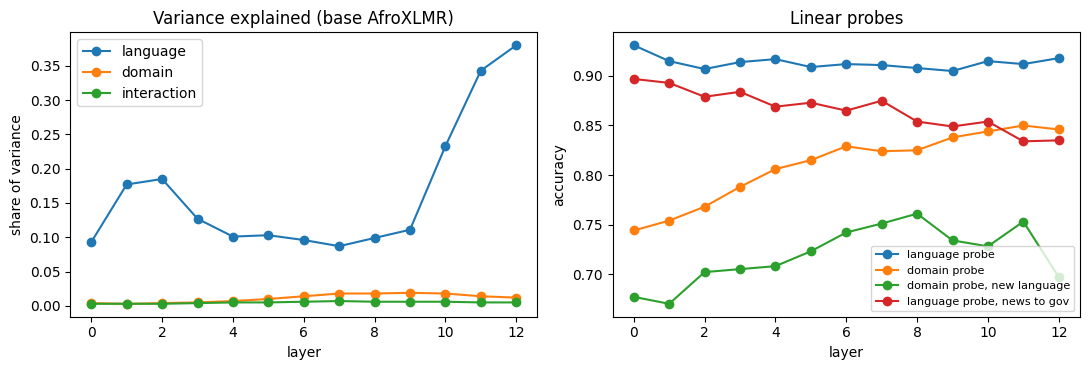

 layer  var_language  var_domain  var_interaction  probe_language  probe_domain  domain_probe_to_new_language  language_probe_news_to_gov
     0         0.093       0.004            0.003           0.931         0.744                         0.677                       0.897
     1         0.177       0.003            0.003           0.915         0.754                         0.670                       0.893
     2         0.185       0.004            0.003           0.907         0.768                         0.702                       0.879
     3         0.127       0.005            0.004           0.914         0.788                         0.705                       0.884
     4         0.101       0.007            0.005           0.917         0.806                         0.708                       0.869
     5         0.103       0.010            0.005           0.909         0.815                         0.723                       0.873
     6         0.096       0.014  

In [ ]:
# 12.1 Base-model representations of the crossed language x domain grid
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

base_model = AutoModel.from_pretrained(MODEL_NAME, output_hidden_states=True).eval()
if torch.cuda.is_available():
    base_model = base_model.cuda()
N_REP = 500

@torch.no_grad()
def layer_means(sents, batch_size=32):
    # mean-pooled hidden states per sentence for every layer (special tokens excluded) -> [layers, n, hidden]
    dev = next(base_model.parameters()).device
    out = []
    for i in range(0, len(sents), batch_size):
        b = sents[i:i + batch_size]
        enc = tokenizer([s["tokens"] for s in b], is_split_into_words=True, truncation=True,
                        max_length=MAX_LENGTH, padding=True, return_tensors="pt").to(dev)
        hs = base_model(**enc).hidden_states
        mask = enc["attention_mask"].clone()
        mask[:, 0] = 0                                                   # <s>
        mask[torch.arange(len(b)), enc["attention_mask"].sum(1) - 1] = 0  # </s>
        m = mask.unsqueeze(-1).float()
        out.append(torch.stack([(h.float() * m).sum(1) / m.sum(1) for h in hs]).cpu().numpy())
    return np.concatenate(out, axis=1)

GRID_LANGS, GRID_CORPORA = ["zul", "xho", "tsn"], ["nchlt", "masakhaner"]
reps, lang_lab, dom_lab = [], [], []
for c in GRID_CORPORA:
    for l in GRID_LANGS:
        sents = random.Random(0).sample(CORPORA[(c, l)]["test"], N_REP)
        reps.append(layer_means(sents)); lang_lab += [l] * N_REP; dom_lab += [DOMAIN[c]] * N_REP
X = np.concatenate(reps, axis=1)            # [13, 3000, 768]
lang_lab, dom_lab = np.array(lang_lab), np.array(dom_lab)
n_layers = X.shape[0]

def decompose(Xl):
    # balanced two-way decomposition of total sum of squares (over all dimensions)
    g = Xl.mean(0)
    ss_tot = ((Xl - g) ** 2).sum()
    ss_lang = sum((lang_lab == a).sum() * ((Xl[lang_lab == a].mean(0) - g) ** 2).sum() for a in GRID_LANGS)
    ss_dom = sum((dom_lab == d).sum() * ((Xl[dom_lab == d].mean(0) - g) ** 2).sum() for d in set(dom_lab))
    ss_cell = sum(((lang_lab == a) & (dom_lab == d)).sum() * ((Xl[(lang_lab == a) & (dom_lab == d)].mean(0) - g) ** 2).sum()
                  for a in GRID_LANGS for d in set(dom_lab))
    return ss_lang / ss_tot, ss_dom / ss_tot, (ss_cell - ss_lang - ss_dom) / ss_tot

probe = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1))
rows = []
for L in range(n_layers):
    Xl = X[L]
    f_lang, f_dom, f_int = decompose(Xl)
    acc_lang = cross_val_score(probe(), Xl, lang_lab, cv=5).mean()
    acc_dom = cross_val_score(probe(), Xl, dom_lab, cv=5).mean()
    # transfer probes: domain probe trained on two languages, tested on the held-out language (averaged over the 3 splits)
    dom_tr = np.mean([probe().fit(Xl[lang_lab != a], dom_lab[lang_lab != a]).score(Xl[lang_lab == a], dom_lab[lang_lab == a])
                      for a in GRID_LANGS])
    # language probe trained on news, tested on government text
    lang_tr = probe().fit(Xl[dom_lab == "news"], lang_lab[dom_lab == "news"]).score(Xl[dom_lab == "government"], lang_lab[dom_lab == "government"])
    rows.append({"layer": L, "var_language": f_lang, "var_domain": f_dom, "var_interaction": f_int,
                 "probe_language": acc_lang, "probe_domain": acc_dom,
                 "domain_probe_to_new_language": dom_tr, "language_probe_news_to_gov": lang_tr})
rep_df = pd.DataFrame(rows).round(3)
rep_df.to_csv(RESULTS_DIR / "representation_language_vs_domain.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(rep_df.layer, rep_df.var_language, marker="o", label="language")
axes[0].plot(rep_df.layer, rep_df.var_domain, marker="o", label="domain")
axes[0].plot(rep_df.layer, rep_df.var_interaction, marker="o", label="interaction")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("share of variance"); axes[0].set_title("Variance explained (base AfroXLMR)"); axes[0].legend()
for col, lab in [("probe_language", "language probe"), ("probe_domain", "domain probe"),
                 ("domain_probe_to_new_language", "domain probe, new language"), ("language_probe_news_to_gov", "language probe, news to gov")]:
    axes[1].plot(rep_df.layer, rep_df[col], marker="o", label=lab)
axes[1].set_xlabel("layer"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Linear probes"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "representation_language_vs_domain.png", dpi=150); plt.show()
print(rep_df.to_string(index=False))

In [ ]:
# 12.2 Source-to-test representation distance for all 99 pairs, and whether it predicts transfer
from scipy.stats import spearmanr

def centroids(sents):
    return layer_means(sents).mean(1)          # [layers, hidden]

CENT = {}
for src in SOURCES:                           # source side: 500 random training sentences
    CENT[("train", *src)] = centroids(random.Random(0).sample(CORPORA[src]["train"], N_REP))
for t in TEST_SETS:                           # test side: 500 random test sentences
    CENT[("test", *t)] = centroids(random.Random(0).sample(CORPORA[t]["test"], N_REP))
grand = np.mean(list(CENT.values()), axis=0)  # remove the direction shared by all sets (anisotropy) before cosine

def rep_dist(src, test):
    a, b = CENT[("train", *src)] - grand, CENT[("test", *test)] - grand
    return 1 - (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))   # per layer

reg3 = reg2.copy()
D = np.array([rep_dist((r.source_corpus, r.source_lang), (r.test_corpus, r.test_lang)) for r in reg3.itertuples()])
for L in range(D.shape[1]):
    reg3[f"dist_L{L}"] = D[:, L]
reg3["rep_dist"] = D[:, 1:].mean(1)            # fixed in advance: mean over layers 1-12

corr = pd.DataFrame([{"layer": L, "spearman_with_TR": spearmanr(reg3[f"dist_L{L}"], reg3.transfer_ratio).correlation}
                     for L in range(D.shape[1])]).round(3)
print(corr.to_string(index=False))
print("mean-layer distance vs TR: Spearman", round(spearmanr(reg3.rep_dist, reg3.transfer_ratio).correlation, 3))

f3 = smf.mixedlm("transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap + fert_gap + rep_dist",
                 data=reg3, groups=reg3["test_lang"]).fit(reml=False)
print(f"\n=== M3 = M2 + rep_dist   (log-likelihood {f3.llf:.1f}, AIC {f3.aic:.1f}; M2 AIC {fits_10_8['M2 corpus terms + fert gap'].aic:.1f})")
print(pd.DataFrame({"coef": f3.params, "se": f3.bse, "p": f3.pvalues}).drop(index="Group Var", errors="ignore").round(3).to_string())

# Key comparison: is the same-language DOMAIN gap larger or smaller than the sister-language gap within a domain?
def d_mean(a, b):  # mean-layer distance between two sets, train-side a vs test-side b
    return round(float(rep_dist(a, b)[1:].mean()), 3)
key = [
    ("same language, other domain", "nchlt zul -> masakhaner zul", d_mean(("nchlt", "zul"), ("masakhaner", "zul"))),
    ("same language, other domain", "masakhaner zul -> nchlt zul", d_mean(("masakhaner", "zul"), ("nchlt", "zul"))),
    ("same language, other domain", "nchlt xho -> masakhaner xho", d_mean(("nchlt", "xho"), ("masakhaner", "xho"))),
    ("same language, other domain", "nchlt tsn -> masakhaner tsn", d_mean(("nchlt", "tsn"), ("masakhaner", "tsn"))),
    ("sister language, same domain", "masakhaner xho -> masakhaner zul", d_mean(("masakhaner", "xho"), ("masakhaner", "zul"))),
    ("sister language, same domain", "nchlt xho -> nchlt zul", d_mean(("nchlt", "xho"), ("nchlt", "zul"))),
    ("sister language, same domain", "nchlt nso -> nchlt tsn", d_mean(("nchlt", "nso"), ("nchlt", "tsn"))),
    ("other Bantu, same domain", "masakhaner swa -> masakhaner tsn", d_mean(("masakhaner", "swa"), ("masakhaner", "tsn"))),
    ("same language, same domain", "nchlt zul -> nchlt zul", d_mean(("nchlt", "zul"), ("nchlt", "zul"))),
]
key_df = pd.DataFrame(key, columns=["comparison", "pair", "mean_layer_distance"])
reg3.drop(columns=[c for c in reg3 if c.startswith("dist_L")]).to_csv(RESULTS_DIR / "representation_distance_pairs.csv", index=False)
key_df

 layer  spearman_with_TR
     0            -0.400
     1            -0.410
     2            -0.407
     3            -0.412
     4            -0.419
     5            -0.411
     6            -0.411
     7            -0.400
     8            -0.394
     9            -0.364
    10            -0.402
    11            -0.383
    12            -0.383
mean-layer distance vs TR: Spearman -0.407

=== M3 = M2 + rep_dist   (log-likelihood 49.8, AIC -77.6; M2 AIC -78.8)
                     coef     se      p
Intercept           0.611  0.103  0.000
rel_score           0.084  0.025  0.001
src_news           -0.022  0.044  0.613
test_news          -0.015  0.048  0.749
src_news:test_news  0.127  0.069  0.068
target_exposure    -0.088  0.065  0.178
entity_overlap      0.138  0.576  0.811
fert_gap           -0.208  0.065  0.001
rep_dist            0.038  0.042  0.367


/tmp/ipykernel_2567/164769292.py:30: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  data=reg3, groups=reg3["test_lang"]).fit(reml=False)


,comparison,pair,mean_layer_distance
0,"same language, other domain",nchlt zul -> masakhaner zul,0.230
1,"same language, other domain",masakhaner zul -> nchlt zul,0.237
2,"same language, other domain",nchlt xho -> masakhaner xho,0.332
3,"same language, other domain",nchlt tsn -> masakhaner tsn,0.060
4,"sister language, same domain",masakhaner xho -> masakhaner zul,0.202
5,"sister language, same domain",nchlt xho -> nchlt zul,0.196
6,"sister language, same domain",nchlt nso -> nchlt tsn,0.190
7,"other Bantu, same domain",masakhaner swa -> masakhaner tsn,1.289
8,"same language, same domain",nchlt zul -> nchlt zul,0.008


### 12.3 Findings (base model)

- **Language dominates the representation.** Language explains 9–38% of the variance per layer and domain only 0.3–1.9%, about 5 to 60 times less. The language share is lowest in the middle layers and highest at the top. A language probe trained on news identifies the language of government text at 83–90%, so language identity is largely domain-invariant. Domain is still linearly decodable (74–85%) and partly shared across languages (67–76% on a held-out language).
- **Distance correlates with transfer but adds nothing to the model.** Source-to-test distance correlates with transfer ratio (Spearman about −0.4 at every layer), but it is not significant once relatedness and the fertility gap are in the model (p = .37, slightly worse AIC).
- **The cross-corpus drop is probably annotation, not text.** NCHLT and news text in the same language are about as close in the base model as two sister languages in the same corpus (isiZulu 0.23 vs 0.20; Setswana only 0.06), yet transfer between corpora drops by 18–32 F1. The representation of the text barely changes, so the likely cause is the labelling (guidelines, `MISC` masking), which raw hidden states cannot show.
- **Swahili is the most distant source from Setswana** (1.29, against about 0.2 for related pairs) yet the best Setswana source, so its advantage is not representational closeness.

Limits: base model only, mean-pooled sentences, one sample of 500 per set. Fine-tuned representations and concept erasure (LEACE) are the next step; see the notes file.

## 13. Annotation vs text: direct tests of the "domain" effect

Section 12 found that, in the base model, NCHLT and MasakhaNER text in the **same language** look about as similar as two sister languages in the same corpus. Yet transfer between the corpora drops by 18–32 F1. That points to the **labels** (annotation guidelines, entity definitions, boundary conventions, the `MISC` class) rather than the **text** as the main source of the cross-corpus gap. Section 12 argues this by elimination. The tests below look for **direct evidence in the errors and the labels**.

| Test | Question | Annotation hypothesis predicts | Text hypothesis predicts |
|---|---|---|---|
| 1. Error breakdown | Does the model *find* the entities but disagree on boundaries or type, or does it *miss* them? | More boundary and type errors cross-corpus than for sister languages; relaxed matching closes much of the gap | Mostly missed and spurious entities; relaxed matching closes little |
| 2. Per-type F1 | Is the gap spread evenly, or concentrated in one entity type? | Concentrated in the type whose definition differs (often ORG); systematic over- or under-labelling of that type | Spread across all types |
| 3. `MISC` audit | What does NCHLT put in `MISC`, and how does MasakhaNER treat the same names? | Many NCHLT `MISC` names are labelled ORG/LOC/PER in MasakhaNER, and news-trained models tag them as entities | `MISC` names are rare or unlabelled in MasakhaNER |
| 4. Relabelling (planned) | If both corpora are labelled under one guideline, does the gap shrink? | Yes | No |

### 13.0 Predictions for the tests

The main loop saved only per-sentence counts, not predicted tags. This cell re-trains eight sources for **one seed (13)** with exactly the main-run settings, and saves their predictions on the six same-language test sets (isiZulu, isiXhosa and Setswana, each in both corpora):

- the six same-language sources (NCHLT and MasakhaNER for isiZulu, isiXhosa and Setswana), which give in-corpus, cross-corpus and sister-language pairs;
- MasakhaNER Swahili and NCHLT Sepedi, the two key RQ4 sources.

A sanity check compares each F1 with the main run's seed-13 result. Small differences are expected, because GPU training is not bit-for-bit deterministic.

In [ ]:
# 13.0 Re-train 8 sources (seed 13) and save predicted tags on the 6 same-language test sets (resumable)
ANN_DIR = RESULTS_DIR / "annotation_tests"
ANN_DIR.mkdir(parents=True, exist_ok=True)
ANN_SEED = 13
ANN_SOURCES = [("nchlt", "zul"), ("masakhaner", "zul"), ("nchlt", "xho"), ("masakhaner", "xho"),
               ("nchlt", "tsn"), ("masakhaner", "tsn"), ("masakhaner", "swa"), ("nchlt", "nso")]
ANN_TESTS = [(c, l) for l in ["zul", "xho", "tsn"] for c in ["nchlt", "masakhaner"]]
PRED_FILE = ANN_DIR / f"predictions_seed{ANN_SEED}.json"
pkey = lambda src, test: f"{src[0]}-{src[1]}__{test[0]}-{test[1]}"

preds = json.loads(PRED_FILE.read_text()) if PRED_FILE.exists() else {}
for src in ANN_SOURCES:
    if all(pkey(src, t) in preds for t in ANN_TESTS):
        print("skip", src); continue
    model = new_model().cuda() if torch.cuda.is_available() else new_model()
    train(model, sample(CORPORA[src]["train"], SOURCE_CAP, ANN_SEED), ANN_SEED, TRAIN_ARGS["num_train_epochs"], RESULTS_DIR / "tmp")
    for t in ANN_TESTS:
        preds[pkey(src, t)] = predict(model, CORPORA[t]["test"])
    PRED_FILE.write_text(json.dumps(preds))
    del model; torch.cuda.empty_cache()
    backup_results()
    print("saved predictions for", src)

# Sanity check against the main run (seed 13, zero-shot)
check = []
for src in ANN_SOURCES:
    for t in ANN_TESTS:
        f1_here = f1_from_counts(sentence_counts(CORPORA[t]["test"], preds[pkey(src, t)]))["f1"]
        m = res[(res.source_corpus == src[0]) & (res.source_lang == src[1]) & (res.test_corpus == t[0]) &
                (res.test_lang == t[1]) & (res.seed == ANN_SEED) & (res.k == 0)]["f1"]
        check.append({"pair": pkey(src, t), "f1_retrained": round(f1_here, 1), "f1_main_run": round(float(m.iloc[0]), 1)})
check_df = pd.DataFrame(check)
check_df["diff"] = (check_df.f1_retrained - check_df.f1_main_run).round(1)
print(f"{len(check_df)} pairs | mean |diff| vs main run: {check_df['diff'].abs().mean():.2f} F1 | max |diff|: {check_df['diff'].abs().max():.1f}")
check_df.to_csv(ANN_DIR / "sanity_check_vs_main_run.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.577921
100,0.227862
150,0.170024
200,0.132994
250,0.116047
300,0.089298
350,0.077693
400,0.065388
450,0.054315
500,0.055540


saved predictions for ('nchlt', 'zul')


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (22 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.436608
100,0.114397
150,0.078955
200,0.073865
250,0.041913
300,0.057000
350,0.040588
400,0.039295
450,0.025937
500,0.029655


saved predictions for ('nchlt', 'nso')
48 pairs | mean |diff| vs main run: 1.19 F1 | max |diff|: 7.5


### 13.1 Test 1: error breakdown

**What it looks for.** Every gold entity is put in one of five classes by comparing it with the model's predicted spans (after the usual `MISC`/`DATE` masking):

| Class | Meaning |
|---|---|
| correct | same span and same type |
| wrong type | exactly the same span, different type (for example ORG predicted for a gold LOC) |
| wrong boundary | overlapping span, same type, different start or end (for example a title or a prefix included or left out) |
| wrong boundary and type | overlapping span, different type and boundaries |
| missed | no predicted span overlaps the gold entity |

Predicted spans that overlap no gold entity are **spurious**. The cell also reports **relaxed F1**, where any overlapping prediction of the right type counts as a hit.

**Comparison groups.** Each source-test pair is put in one group. *In-corpus* means same language and same corpus, the upper bound. *Cross-corpus* means same language, other corpus, which is the "domain" condition. *Sister language* means same corpus, sister language, which is the reference for a pure language shift with matching annotation.

**How to read it.**
- The key number is the **found-but-mismatched share**: of the gold entities the model got wrong, the share it did locate (wrong type or boundary) rather than missed.
  - Higher for *cross-corpus* than for *sister language* → the model recognises the entities but the two corpora disagree on **how they are marked**. This supports the annotation hypothesis.
  - Errors dominated by **missed** entities → the model fails to recognise the names at all, which fits a **text or vocabulary** explanation.
- **Strict → relaxed F1 gain.** Boundary conventions (titles, prefixes, punctuation) cost strict F1 but not relaxed F1. A much larger gain cross-corpus than for sister languages means boundary conventions differ between the corpora.
- **High spurious rate** cross-corpus → the source corpus labels things the target corpus leaves unlabelled (a difference in annotation **scope**).
- The most frequent missed and spurious strings are listed for the cross-corpus pairs so the pattern can be checked by eye.

In [ ]:
# 13.1 Test 1: classify every gold entity as correct / wrong type / wrong boundary / both / missed; count spurious predictions
def overlaps(a, b):  # spans are (type, start, end), end exclusive
    return a[1] < b[2] and b[1] < a[2]

def error_breakdown(gold_sents, pred_tags, collect=False):
    c, missed_str, spurious_str = Counter(), Counter(), Counter()
    for s, p in zip(gold_sents, pred_tags):
        g_tags, p_tags = mask_excluded(s["tags"], p)
        gs, ps = entity_spans(g_tags), entity_spans(p_tags)
        c["gold"] += len(gs); c["pred"] += len(ps)
        for g in gs:
            ov = [q for q in ps if overlaps(g, q)]
            if g in ps:
                c["correct"] += 1
            elif not ov:
                c["missed"] += 1
                if collect: missed_str[(g[0], " ".join(s["tokens"][g[1]:g[2]]))] += 1
            elif any((q[1], q[2]) == (g[1], g[2]) for q in ov):
                c["wrong_type"] += 1
            elif any(q[0] == g[0] for q in ov):
                c["wrong_boundary"] += 1
            else:
                c["wrong_boundary_and_type"] += 1
            c["relaxed_hit_gold"] += any(q[0] == g[0] for q in ov)
        for q in ps:
            ov = [g for g in gs if overlaps(g, q)]
            if not ov:
                c["spurious"] += 1
                if collect: spurious_str[(q[0], " ".join(s["tokens"][q[1]:q[2]]))] += 1
            c["relaxed_hit_pred"] += any(g[0] == q[0] for g in ov)
    return c, missed_str, spurious_str

def pair_kind(src, test):
    if src == test:
        return "in-corpus"
    if src[1] == test[1]:
        return "cross-corpus (same language)"
    if src[0] == test[0] and relatedness(src[1], test[1]) == "same_cluster":
        return "sister language (same corpus)"
    return "other"

def summarise(c):
    f = lambda p, r: 100 * 2 * p * r / (p + r) if p + r else 0.0
    strict = f(c["correct"] / max(c["pred"], 1), c["correct"] / max(c["gold"], 1))
    relaxed = f(c["relaxed_hit_pred"] / max(c["pred"], 1), c["relaxed_hit_gold"] / max(c["gold"], 1))
    errs = c["gold"] - c["correct"]
    found = c["wrong_type"] + c["wrong_boundary"] + c["wrong_boundary_and_type"]
    return {"gold": c["gold"], "pred": c["pred"], "strict_f1": round(strict, 1), "relaxed_f1": round(relaxed, 1),
            "relaxed_gain": round(relaxed - strict, 1),
            "pct_missed": round(100 * c["missed"] / max(c["gold"], 1), 1),
            "pct_wrong_type": round(100 * c["wrong_type"] / max(c["gold"], 1), 1),
            "pct_wrong_boundary": round(100 * c["wrong_boundary"] / max(c["gold"], 1), 1),
            "pct_wrong_both": round(100 * c["wrong_boundary_and_type"] / max(c["gold"], 1), 1),
            "pct_spurious_of_pred": round(100 * c["spurious"] / max(c["pred"], 1), 1),
            "found_but_mismatched_share": round(100 * found / max(errs, 1), 1)}

pair_rows, kind_counts, examples = [], defaultdict(Counter), {}
for src in ANN_SOURCES:
    for t in ANN_TESTS:
        kind = pair_kind(src, t)
        if kind == "other" and src[1] not in ("swa", "nso"):
            continue
        c, ms, ss = error_breakdown(CORPORA[t]["test"], preds[pkey(src, t)], collect=(kind == "cross-corpus (same language)"))
        pair_rows.append({"source": f"{src[0]} {src[1]}", "test": f"{t[0]} {t[1]}", "kind": kind, **summarise(c)})
        kind_counts[kind] += c
        if kind == "cross-corpus (same language)":
            examples[pkey(src, t)] = (ms, ss)

err_pairs = pd.DataFrame(pair_rows).sort_values(["kind", "test", "source"])
err_kinds = pd.DataFrame([{"kind": k, **summarise(c)} for k, c in kind_counts.items()]).set_index("kind").loc[
    ["in-corpus", "sister language (same corpus)", "cross-corpus (same language)", "other"]]
err_pairs.to_csv(ANN_DIR / "test1_error_breakdown_pairs.csv", index=False)
err_kinds.to_csv(ANN_DIR / "test1_error_breakdown_by_kind.csv")

print("=== By comparison group (counts pooled over pairs) ===")
print(err_kinds.to_string()); print()
print("=== Per pair ===")
print(err_pairs.to_string(index=False)); print()
for k, (ms, ss) in examples.items():
    print(f"--- {k}: most frequent MISSED gold entities: {[f'{t}:{w}' for (t, w), n in ms.most_common(8)]}")
    print(f"    most frequent SPURIOUS predictions:   {[f'{t}:{w}' for (t, w), n in ss.most_common(8)]}")

=== By comparison group (counts pooled over pairs) ===
                                gold   pred  strict_f1  relaxed_f1  relaxed_gain  pct_missed  pct_wrong_type  pct_wrong_boundary  pct_wrong_both  pct_spurious_of_pred  found_but_mismatched_share
kind                                                                                                                                                                                              
in-corpus                       7311   7757       84.8        90.9           6.1         3.3             2.8                 5.8             0.7                   7.2                        73.7
sister language (same corpus)   5984   6918       71.8        82.6          10.8         4.4             4.8                11.5             1.9                  16.3                        80.6
cross-corpus (same language)    7311   8148       61.1        80.0          18.9        10.4             4.8                18.1             2.1                  14.

### 13.2 Test 2: per-type F1, type confusions and label profiles

**What it looks for.** Whether the cross-corpus gap is spread evenly over PER, LOC and ORG, or concentrated in one type. Three views:

1. **Per-type precision, recall and F1** for in-corpus, cross-corpus and sister-language pairs, plus the **cross-corpus gap per type** (in-corpus F1 minus cross-corpus F1, per target).
2. **Over- or under-labelling ratio per type:** predicted entities of a type divided by gold entities of that type. A ratio far from 1 means the source corpus has taught a broader or narrower idea of that type than the target corpus uses.
3. **Type confusion matrix** for cross-corpus pairs: for gold entities the model located but typed differently, which type was predicted instead (for example gold ORG predicted as LOC).
4. **Label profile of each test set:** PER, LOC and ORG entities per 1,000 tokens, and the share of tokens masked as `MISC`/`DATE`. Two corpora of the same language with very different profiles are being annotated to different definitions, independent of any model.

**How to read it.**
- **Gap concentrated in one type** (for example ORG F1 collapses cross-corpus while PER holds) → the corpora define that type differently. Person names are the easiest type to agree on, so PER is the natural control: if PER transfers well across corpora but ORG and LOC do not, that is hard to explain by text alone.
- **Systematic over- or under-labelling** (ratio well above or below 1) cross-corpus but not in-corpus → a scope difference in the guidelines.
- **Confusions between specific pairs of types** (ORG ↔ LOC is typical for government bodies, places named after institutions, or locatives) → a definitional mismatch.
- **Gap spread evenly** across types, ratios near 1, no dominant confusion → the shift is general, which fits a text or vocabulary explanation better.

In [ ]:
# 13.2 Test 2: per-type scores, over/under-labelling, type confusions and label profiles
TYPES = ["PER", "LOC", "ORG"]

def per_type(gold_sents, pred_tags):
    cnt = sentence_counts(gold_sents, pred_tags).sum()
    out = {}
    for t in TYPES:
        tp, fp, fn = cnt[f"tp_{t}"], cnt[f"fp_{t}"], cnt[f"fn_{t}"]
        p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
        out[t] = {"P": 100 * p, "R": 100 * r, "F1": 100 * 2 * p * r / (p + r) if p + r else 0.0,
                  "pred_to_gold": (tp + fp) / max(tp + fn, 1)}
    return out

rows = []
for src in ANN_SOURCES:
    for t in ANN_TESTS:
        kind = pair_kind(src, t)
        if kind == "other":
            continue
        for typ, v in per_type(CORPORA[t]["test"], preds[pkey(src, t)]).items():
            rows.append({"source": f"{src[0]} {src[1]}", "test": f"{t[0]} {t[1]}", "kind": kind, "type": typ,
                         **{k: round(x, 2) for k, x in v.items()}})
type_df = pd.DataFrame(rows)
type_df.to_csv(ANN_DIR / "test2_per_type_pairs.csv", index=False)

print("=== Mean per-type F1 and pred/gold ratio by comparison group ===")
print(type_df.groupby(["kind", "type"])[["P", "R", "F1", "pred_to_gold"]].mean().round(2).unstack("type").to_string()); print()

# Cross-corpus gap per type and target: in-corpus F1 minus cross-corpus F1 on the same test set
def f1_of(src, test, typ):
    m = (type_df.source == f"{src[0]} {src[1]}") & (type_df.test == f"{test[0]} {test[1]}") & (type_df.type == typ)
    return float(type_df.loc[m, "F1"].iloc[0])

gap = []
for t in ANN_TESTS:
    other = ("masakhaner" if t[0] == "nchlt" else "nchlt", t[1])
    for typ in TYPES:
        f_in, f_x = f1_of(t, t, typ), f1_of(other, t, typ)
        gap.append({"test": f"{t[0]} {t[1]}", "type": typ, "in_corpus_F1": round(f_in, 1),
                    "cross_corpus_F1": round(f_x, 1), "gap": round(f_in - f_x, 1)})
gap_long = pd.DataFrame(gap)
gap_long.to_csv(ANN_DIR / "test2_cross_corpus_gap_by_type.csv", index=False)
print("=== Cross-corpus gap (in-corpus F1 - cross-corpus F1) per type ===")
print(gap_long.pivot(index="test", columns="type", values="gap").to_string()); print()
print(gap_long.to_string(index=False)); print()

# Type confusions for cross-corpus pairs: for each gold entity, the type of the first overlapping prediction (or "missed")
conf = {d: Counter() for d in ["gov -> news", "news -> gov"]}
for src in ANN_SOURCES:
    for t in ANN_TESTS:
        if pair_kind(src, t) != "cross-corpus (same language)":
            continue
        d = "gov -> news" if src[0] == "nchlt" else "news -> gov"
        for s, p in zip(CORPORA[t]["test"], preds[pkey(src, t)]):
            g_tags, p_tags = mask_excluded(s["tags"], p)
            ps = entity_spans(p_tags)
            for g in entity_spans(g_tags):
                ov = [q for q in ps if overlaps(g, q)]
                conf[d][(g[0], ov[0][0] if ov else "missed")] += 1
for d, c in conf.items():
    m = pd.DataFrame([{"gold": g, "predicted": pr, "n": n} for (g, pr), n in c.items()]).pivot(
        index="gold", columns="predicted", values="n").fillna(0).astype(int)
    m = m[[x for x in TYPES + ["missed"] if x in m.columns]]
    m.to_csv(ANN_DIR / f"test2_confusion_{d.replace(' -> ', '_to_')}.csv")
    print(f"=== Confusions, cross-corpus {d} (rows = gold type, columns = predicted type) ===")
    print(m.to_string()); print()

# Label profile of each test set (no model involved)
prof = []
for t in ANN_TESTS:
    sents = CORPORA[t]["test"]
    n_tok = sum(len(s["tokens"]) for s in sents)
    ents = Counter(e[0] for s in sents for e in entity_spans(s["tags"]))
    prof.append({"test": f"{t[0]} {t[1]}", **{f"{k}_per_1k_tokens": round(1000 * ents[k] / n_tok, 1) for k in TYPES},
                 "pct_tokens_masked": round(100 * sum(x == IGNORE for s in sents for x in s["tags"]) / n_tok, 1)})
prof_df = pd.DataFrame(prof)
prof_df.to_csv(ANN_DIR / "test2_label_profiles.csv", index=False)
print("=== Label profile of each test set ===")
print(prof_df.to_string(index=False))

=== Mean per-type F1 and pred/gold ratio by comparison group ===
                                   P                    R                   F1               pred_to_gold            
type                             LOC    ORG    PER    LOC    ORG    PER    LOC    ORG    PER          LOC   ORG   PER
kind                                                                                                                 
cross-corpus (same language)   62.92  52.00  66.33  69.51  49.46  64.23  65.20  49.49  64.56         1.13  0.97  0.98
in-corpus                      81.58  69.91  88.58  85.42  78.69  87.48  83.38  73.98  87.99         1.05  1.12  0.99
sister language (same corpus)  61.18  47.21  65.72  62.33  68.84  74.75  61.38  54.40  69.11         1.05  1.75  1.19

=== Cross-corpus gap (in-corpus F1 - cross-corpus F1) per type ===
type             LOC   ORG   PER
test                            
masakhaner tsn   5.3  15.0  19.3
masakhaner xho  28.7  19.8  18.8
masakhaner zul  33.2  33.5 

### 13.3 Test 3: what is in NCHLT's `MISC` class, and how does MasakhaNER treat it?

`MISC` is the largest entity class in every NCHLT language, and our harmonisation masks it (ignored in training and scoring) because MasakhaNER has no `MISC`. If NCHLT annotators put names in `MISC` that MasakhaNER annotators would call ORG, LOC or PER, the two corpora disagree about exactly the names a transferred model has to handle. The audit has three parts:

- **(a) Inventory.** The most frequent NCHLT `MISC` strings for isiZulu, isiXhosa and Setswana, from the raw tags, so the category can be inspected directly. Typical candidates are nationalities, languages, events, programmes, laws, titles and dates.
- **(b) Look-up in MasakhaNER.** Every distinct NCHLT `MISC` string is searched for in the MasakhaNER corpus of the same language (all splits, raw tags). Each occurrence is recorded as labelled PER, LOC, ORG or DATE, as unlabelled text (O), or as a partial or overlapping label.
- **(c) What a news-trained model does with them.** On the NCHLT test sets, the `MISC` (masked) spans are fed through the model trained on MasakhaNER in the same language, and through the NCHLT in-language model for comparison. The cell counts how often each predicts PER, LOC, ORG or O there. These positions are masked in scoring, so this is a diagnostic only.

**How to read it.**
- A large share of NCHLT `MISC` strings **labelled ORG/LOC/PER in MasakhaNER**, or **predicted as entities by the news-trained model** → the corpora draw the entity boundary differently. Names NCHLT sets aside as `MISC` are core entities under MasakhaNER's guidelines, so models trained on one corpus learn the "wrong" scope for the other.
- `MISC` strings mostly **absent or unlabelled (O)** in MasakhaNER, and predicted as O → `MISC` covers things MasakhaNER also leaves out. Then `MISC` is not a source of mismatch, and the masking is harmless.
- Part (c) also shows whether the NCHLT model, which never trained on `MISC` tokens, tends to tag them as entities anyway.

In [ ]:
# 13.3 Test 3: NCHLT MISC audit
def raw_spans(tags):
    # (TYPE, start, end) from raw BIO tags with any type names ("OUT"/"O" = outside)
    spans, cur, start = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        t = t.strip().upper()
        typ = t.split("-", 1)[1] if "-" in t else None
        if t.startswith("B-") or typ is None or (t.startswith("I-") and typ != cur):
            if cur is not None:
                spans.append((cur, start, i)); cur = None
            if typ is not None:
                cur, start = typ, i
    return spans

AUDIT_LANGS = ["zul", "xho", "tsn"]
audit_rows, lookup_rows, pred_rows = [], [], []
for lang in AUDIT_LANGS:
    # (a) inventory of NCHLT MISC strings (raw, all sentences)
    misc = Counter()
    for s in nchlt_all[lang]:
        for typ, a, b in raw_spans(s["tags"]):
            if typ == "MISC":
                misc[tuple(w.lower() for w in s["tokens"][a:b])] += 1
    audit_rows.append({"lang": lang, "misc_occurrences": sum(misc.values()), "distinct_strings": len(misc),
                       "top_15": "; ".join(f"{' '.join(k)} ({n})" for k, n in misc.most_common(15))})

    # (b) look up each MISC string in MasakhaNER of the same language (all splits, raw tags incl. DATE)
    mk = [(tuple(w.lower() for w in s["tokens"]), [t.upper() for t in s["tags"]]) for split in masakhane[lang].values() for s in split]
    first = defaultdict(list)
    for si, (toks, _) in enumerate(mk):
        for pos, w in enumerate(toks):
            first[w].append((si, pos))
    labels_per_string = {}
    for key in misc:
        n, labs = len(key), Counter()
        for si, pos in first.get(key[0], []):
            toks, tags = mk[si]
            if toks[pos:pos + n] != key:
                continue
            sp = tags[pos:pos + n]
            nxt = tags[pos + n] if pos + n < len(tags) else "O"
            if all(x == "O" for x in sp):
                labs["O (unlabelled)"] += 1
            elif sp[0].startswith("B-") and all(x == "I-" + sp[0][2:] for x in sp[1:]) and nxt != "I-" + sp[0][2:]:
                labs[sp[0][2:]] += 1
            else:
                labs["partial / other"] += 1
        if labs:
            labels_per_string[key] = labs
    occ = sum(labels_per_string.values(), Counter())
    maj = Counter(c.most_common(1)[0][0] for c in labels_per_string.values())
    lookup_rows.append({"lang": lang, "distinct_misc_strings": len(misc), "found_in_masakhaner": len(labels_per_string),
                        "pct_found": round(100 * len(labels_per_string) / max(len(misc), 1), 1),
                        **{f"occ_{k}": v for k, v in sorted(occ.items())},
                        **{f"majority_{k}": v for k, v in sorted(maj.items())},
                        "examples_labelled_as_entity": "; ".join(
                            f"{' '.join(k)}→{c.most_common(1)[0][0]}" for k, c in
                            sorted(labels_per_string.items(), key=lambda kv: -misc[kv[0]])
                            if c.most_common(1)[0][0] in ("PER", "LOC", "ORG", "DATE"))[:400]})

    # (c) predictions at NCHLT test MISC (masked) positions
    test = CORPORA[("nchlt", lang)]["test"]
    for model_src in [("masakhaner", lang), ("nchlt", lang)]:
        pt = preds[pkey(model_src, ("nchlt", lang))]
        out = Counter()
        for s, p in zip(test, pt):
            i, tags = 0, s["tags"]
            while i < len(tags):
                if tags[i] != IGNORE:
                    i += 1; continue
                j = i
                while j < len(tags) and tags[j] == IGNORE:
                    j += 1
                ents = [x[2:] for x in p[i:j] if x != "O"]
                out[Counter(ents).most_common(1)[0][0] if ents else "O"] += 1
                i = j
        tot = sum(out.values())
        pred_rows.append({"lang": lang, "model": f"{model_src[0]} {model_src[1]}", "misc_spans_in_test": tot,
                          **{f"pct_pred_{k}": round(100 * out[k] / max(tot, 1), 1) for k in ["O", "PER", "LOC", "ORG"]}})

misc_inv = pd.DataFrame(audit_rows); misc_look = pd.DataFrame(lookup_rows).fillna(0); misc_pred = pd.DataFrame(pred_rows)
for name, df in [("test3_misc_inventory", misc_inv), ("test3_misc_lookup_in_masakhaner", misc_look), ("test3_misc_predictions", misc_pred)]:
    df.to_csv(ANN_DIR / f"{name}.csv", index=False)
pd.set_option("display.max_colwidth", 400)
print("=== (a) NCHLT MISC inventory ==="); print(misc_inv.to_string(index=False)); print()
print("=== (b) NCHLT MISC strings found in MasakhaNER (same language) ==="); print(misc_look.drop(columns="examples_labelled_as_entity").to_string(index=False)); print()
for _, r in misc_look.iterrows():
    print(f"{r.lang}: examples labelled as entities in MasakhaNER: {r.examples_labelled_as_entity}")
print(); print("=== (c) Predictions at NCHLT test MISC positions ==="); print(misc_pred.to_string(index=False))

=== (a) NCHLT MISC inventory ===
lang  misc_occurrences  distinct_strings                                                                                                                                                                                                                                     top_15
 zul             10805              6350                                                              1 (247); mthetho (180); 2 (128); le (106); uma (95); 3 (90); umthetho (63); 4 (56); 5 (52); 6 (40); imininingwane (40); umthethosisekelo (39); 1998 (38); 12 (35); lokhu (35)
 xho             10211              5150 mthetho (118); umthetho (84); umntu (69); inkqubo (57); injongo (53); umphathiswa (52); umsebenzi (38); karhulumente (36); amanzi (36); umgaqo-siseko (35); abantu (34); ngumphathiswa (34); ibhunga (33); icandelo (32); urhulumente (32)
 tsn              7782              3784                                                                               1 (119); molaotheo (

### 13.4 Test 4: relabel a Setswana sample under one guideline (small study or next step)

**Question.** If sentences from both corpora are labelled again by the same annotators under **one shared guideline**, does the cross-corpus gap shrink? Tests 1–3 can only show that the corpora *disagree*. Relabelling shows how much of the transfer gap that disagreement *causes*. It is the most direct test of the annotation hypothesis.

**Design**

| Element | Choice | Why |
|---|---|---|
| Language | Setswana | The only RQ4 target, and the language with the smallest representational domain gap (0.06, section 12) but an 18 F1 cross-corpus drop. If annotation explains the drop anywhere, it should show here |
| Sample | 100 test sentences from NCHLT Setswana and 100 from MasakhaNER Setswana (seed 2027) | Roughly 150–250 entities per corpus. Enough to see a large change in the gap, not a small one; for confidence intervals, resample sentences as in the 10.6 bootstrap |
| Stratification | 70% of sentences with at least one original entity (including `MISC`), 30% random others | Entity-free sentences give no signal. The others are kept so annotators also see sentences where nothing should be labelled |
| Blinding | The two corpora are mixed, sentence IDs are random, and original labels are hidden | Annotators must not know which corpus a sentence comes from, or what it was labelled before |
| Label set | PER, LOC, ORG in BIO format; everything else O | Matches the study's harmonised label set, so models can be re-scored directly |
| Guideline | MasakhaNER's published annotation guideline for PER/LOC/ORG (check the dataset repository for the current version), plus a one-page decision list agreed in a pilot | One guideline applied to both corpora. MasakhaNER's is the natural choice because the main target test sets use it |
| Annotators | Two Setswana-literate annotators, labelling independently | Inter-annotator agreement measures how well defined the guideline is |
| Pilot | 20 extra sentences labelled together first; disagreements discussed and written into the decision list | Reduces guideline drift during the main pass |
| Adjudication | Disagreements resolved by a third person or by discussion → one adjudicated label set | The adjudicated labels become the new gold |

**Decision-list topics to settle in the pilot** (where corpora usually differ): titles and honorifics inside PER (*Rre*, *Mme*, *Dr*); government departments and programmes (ORG or not); places named after institutions; nationalities and languages (not PER/LOC/ORG under MasakhaNER-style guidelines); dates (not labelled); prefixes and locatives attached to names; multi-word names and nested names (label the longest span).

**What is measured** (the scoring cell below does this once the files exist)

1. **Inter-annotator agreement**: entity-level F1 between annotators A and B, and token-level Cohen's κ. Rough guide: entity F1 above 0.85 means the guideline is usable.
2. **Distance of each corpus from the shared guideline**: entity F1 of the *original* labels against the adjudicated labels, per corpus, and how many adjudicated entities sit on tokens originally labelled `MISC`. If NCHLT's original labels deviate much more than MasakhaNER's, NCHLT's guideline is the outlier.
3. **The key result: re-scoring existing models.** The saved seed-13 predictions (13.0) are scored on the 200 sentences against the original labels and against the adjudicated labels. The **cross-corpus gap** (in-corpus model vs other-corpus model on the same test sentences) is compared under both label sets.
   - Gap **shrinks substantially** with the shared labels → annotation differences cause a large part of the "domain" effect.
   - Gap **stays the same** → the cause is the text, or something else the shared labels do not touch.

**Effort.** Setswana sentences average about 27 tokens. At about 1 minute per sentence, each annotator needs about 3.5 hours for 200 sentences, plus about 1 hour for the pilot and guideline training. Adjudication takes about 1–2 hours. Total: roughly 10–12 person-hours. Tools: the exported TSV can be filled in a spreadsheet, or imported into a labelling tool (for example Label Studio or doccano) and exported back to the same format.

**Licences.** NCHLT is CC BY 2.5 ZA. MasakhaNER 2.0's card lists a non-commercial CC 4.0 licence (see the literature notes). Relabelling for research and reporting aggregate results fits both; do not redistribute the relabelled sentences without checking the terms.

**If there is no time.** Report this as the main next step, with the design above. Tests 1–3 already show *where* the corpora disagree; relabelling would show *how much* of the gap that explains.

**How to use the cells below.**
1. Run the export cell. It writes `results/relabel/relabel_sheet.tsv` (one token per row: `sent_id`, `tok_id`, `token`, empty `label`; blank line between sentences) and a hidden key file, and copies both to Drive.
2. Give each annotator a copy of the sheet. They fill in the `label` column and save the files as `annotated_A.tsv` and `annotated_B.tsv` in the same folder.
3. After adjudication, save `adjudicated.tsv`, then run the scoring cell.

In [ ]:
# 13.4a Export a blind relabelling sheet: 100 NCHLT + 100 MasakhaNER Setswana test sentences, mixed and anonymised
RELABEL_DIR = RESULTS_DIR / "relabel"
RELABEL_DIR.mkdir(parents=True, exist_ok=True)
RELABEL_N, RELABEL_SEED, WITH_ENTITY_SHARE = 100, 2027, 0.7
RELABEL_TESTS = [("nchlt", "tsn"), ("masakhaner", "tsn")]

def pick_sentences(sents, n, seed, share):
    rng = random.Random(seed)
    idx = list(range(len(sents))); rng.shuffle(idx)
    has_ent = [i for i in idx if entity_spans(sents[i]["tags"]) or IGNORE in sents[i]["tags"]]
    has_ent_set = set(has_ent)
    others = [i for i in idx if i not in has_ent_set]
    k = int(round(n * share))
    return has_ent[:k] + others[:n - k]

items = []
for t in RELABEL_TESTS:
    for i in pick_sentences(CORPORA[t]["test"], RELABEL_N, RELABEL_SEED, WITH_ENTITY_SHARE):
        items.append({"corpus": t[0], "lang": t[1], "test_index": i})
random.Random(RELABEL_SEED).shuffle(items)
for n, it in enumerate(items):
    it["sent_id"] = f"S{n + 1:03d}"

SHEET = RELABEL_DIR / "relabel_sheet.tsv"
KEY = RELABEL_DIR / "relabel_key.json"   # keep this away from the annotators
if SHEET.exists():
    print("sheet already exists, not overwritten:", SHEET)
else:
    with open(SHEET, "w", encoding="utf-8") as f:
        f.write("sent_id\ttok_id\ttoken\tlabel\n")
        for it in items:
            for j, w in enumerate(CORPORA[(it["corpus"], it["lang"])]["test"][it["test_index"]]["tokens"]):
                f.write(f"{it['sent_id']}\t{j}\t{w}\t\n")
            f.write("\n")
    KEY.write_text(json.dumps(items, indent=1), encoding="utf-8")
    print("wrote", SHEET, "and", KEY)
n_tok = sum(len(CORPORA[(it["corpus"], it["lang"])]["test"][it["test_index"]]["tokens"]) for it in items)
print(f"{len(items)} sentences, {n_tok} tokens (about {n_tok / max(len(items), 1):.0f} per sentence)")
backup_results()

wrote /content/results/relabel/relabel_sheet.tsv and /content/results/relabel/relabel_key.json
200 sentences, 5693 tokens (about 28 per sentence)


In [ ]:
# 13.4b Score the relabelling study (runs only when the annotated files exist)
from sklearn.metrics import cohen_kappa_score

def read_sheet(path):
    sents, cur = {}, []
    with open(path, encoding="utf-8") as f:
        next(f)                                       # header
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                continue
            sid, tid, tok, lab = (line.split("\t") + [""] * 4)[:4]
            sents.setdefault(sid, []).append((int(tid), tok, (lab.strip() or "O").upper()))
    return {sid: [lab for _, _, lab in sorted(v)] for sid, v in sents.items()}

def entity_f1(gold_tags, pred_tags):
    gold = [{"tokens": ["x"] * len(g), "tags": g} for g in gold_tags]
    return f1_from_counts(sentence_counts(gold, pred_tags))["f1"]

files = {k: RELABEL_DIR / f"{k}.tsv" for k in ["annotated_A", "annotated_B", "adjudicated"]}
if not all(p.exists() for p in files.values()):
    print("Waiting for annotated files:", [p.name for p in files.values() if not p.exists()])
else:
    items = json.loads(KEY.read_text(encoding="utf-8"))
    A, B, ADJ = (read_sheet(files[k]) for k in ["annotated_A", "annotated_B", "adjudicated"])
    ids = [it["sent_id"] for it in items]

    # 1. Inter-annotator agreement
    iaa_f1 = entity_f1([A[i] for i in ids], [B[i] for i in ids])
    kappa = cohen_kappa_score([x for i in ids for x in A[i]], [x for i in ids for x in B[i]])
    print(f"Inter-annotator agreement: entity F1 {iaa_f1:.1f} | token Cohen's kappa {kappa:.3f}")

    # 2. Distance of each corpus's ORIGINAL labels from the shared (adjudicated) labels
    rows = []
    for c in ["nchlt", "masakhaner"]:
        sub = [it for it in items if it["corpus"] == c]
        orig = [[("O" if x == IGNORE else x) for x in CORPORA[(c, it["lang"])]["test"][it["test_index"]]["tags"]] for it in sub]
        adj = [ADJ[it["sent_id"]] for it in sub]
        on_misc = sum(1 for it, a in zip(sub, adj) for typ, s0, e0 in entity_spans(a)
                      if any(CORPORA[(c, it["lang"])]["test"][it["test_index"]]["tags"][k] == IGNORE for k in range(s0, e0)))
        rows.append({"corpus": c, "sentences": len(sub), "adjudicated_entities": sum(len(entity_spans(a)) for a in adj),
                     "original_vs_shared_F1": round(entity_f1(adj, orig), 1), "shared_entities_on_original_MISC": on_misc})
    print(pd.DataFrame(rows).to_string(index=False)); print()

    # 3. Re-score saved seed-13 predictions against original vs shared labels
    rows = []
    for src in ANN_SOURCES:
        for c in ["nchlt", "masakhaner"]:
            t = (c, "tsn")
            sub = [it for it in items if it["corpus"] == c]
            p = [preds[pkey(src, t)][it["test_index"]] for it in sub]
            gold_orig = [CORPORA[t]["test"][it["test_index"]] for it in sub]
            f_orig = f1_from_counts(sentence_counts(gold_orig, p))["f1"]
            f_new = entity_f1([ADJ[it["sent_id"]] for it in sub], p)
            rows.append({"source": f"{src[0]} {src[1]}", "test": f"{c} tsn", "F1_original_labels": round(f_orig, 1), "F1_shared_labels": round(f_new, 1)})
    rescored = pd.DataFrame(rows)
    rescored.to_csv(RELABEL_DIR / "rescored_models.csv", index=False)
    print(rescored.to_string(index=False)); print()
    for c in ["nchlt", "masakhaner"]:
        other = "masakhaner" if c == "nchlt" else "nchlt"
        r_in = rescored[(rescored.source == f"{c} tsn") & (rescored.test == f"{c} tsn")].iloc[0]
        r_x = rescored[(rescored.source == f"{other} tsn") & (rescored.test == f"{c} tsn")].iloc[0]
        print(f"Cross-corpus gap on {c} tsn: original labels {r_in.F1_original_labels - r_x.F1_original_labels:.1f} F1 "
              f"-> shared labels {r_in.F1_shared_labels - r_x.F1_shared_labels:.1f} F1")

Waiting for annotated files: ['annotated_A.tsv', 'annotated_B.tsv', 'adjudicated.tsv']


### 13.5 Findings from Tests 1–3

**Sanity check.** The re-trained seed-13 models reproduce the main run closely: mean absolute difference 1.2 F1 over 48 pairs (maximum 7.5).

**Test 1: cross-corpus errors are mostly disagreements about *what counts* and *where it ends*, not failures to recognise names.**

| Group (pooled) | Strict F1 | Relaxed F1 | Relaxed gain | Missed | Wrong boundary | Spurious (of predictions) |
|---|---|---|---|---|---|---|
| In-corpus | 84.8 | 90.9 | 6.1 | 3.3% | 5.8% | 7.2% |
| Sister language, same corpus | 71.8 | 82.6 | 10.8 | 4.4% | 11.5% | 16.3% |
| **Cross-corpus, same language** | **61.1** | **80.0** | **18.9** | 10.4% | **18.1%** | 14.2% |

- Relaxing the boundary requirement closes **more than half of the cross-corpus gap**. Strict in-corpus minus cross-corpus is 23.7 F1; relaxed it is 10.9. For sister languages, relaxing closes only about a third (13.0 → 8.3). The two corpora mark the *extent* of entities differently.
- The two directions fail differently, and **both failures look like annotation**:
  - **Government → news** (NCHLT-trained, tested on MasakhaNER): errors are mostly boundary errors (10.8–28.6% of gold); missed entities are only 3.4–10.3%. The most frequent spurious predictions are **titles and generic institution nouns** that MasakhaNER leaves unlabelled: *uMnuz* (Mr), *uNksz* (Ms), *umnyango* (department), *UMphathiswa* (minister), *Moporesidente* (president), *Palamente* (parliament). The NCHLT model has learned to tag them.
  - **News → government** (MasakhaNER-trained, tested on NCHLT): 21–27% of gold entities are "missed", and the most frequent missed "entities" are **the same kinds of words labelled as entities in NCHLT**: *uNgqongqoshe* / *nguNgqongqoshe* (the minister) and *kuMongameli* (to the president) as PER; *ePhalamende* / *ePalamente* (in parliament), *uMkhandlu* (the council) and *sebe* (department) as ORG. These are not names the model failed to recognise; MasakhaNER's guidelines do not treat them as entities.
- Some misses are genuine vocabulary gaps (news-only names such as *ANC*, *Isolezwe*, *Ramaphosa*, *Digital Vibes* missed by NCHLT models), so text plays a part too, but a smaller one.
- **Inside NCHLT the conventions also differ between languages.** isiZulu → isiXhosa (NCHLT) gains 32 F1 from relaxed matching (MasakhaNER sister pairs: 5–7). Sepedi → Setswana (NCHLT) has 47% spurious predictions: the Sepedi model labels nearly twice as many entities (899) as NCHLT Setswana contains (502).

**RQ4 in this light.** On Setswana news the Sepedi model **misses fewer gold entities than Swahili** (1.0% against 4.8%) and locates 95% of the entities it gets wrong. Its lower strict F1 (66.0 against 80.6) comes from **over-labelling** (27.9% spurious, 1,878 predictions for 1,327 gold entities) and **boundary errors**. Relaxed F1 narrows the gap (78.2 against 87.6). Relatedness helps Sepedi *find* Setswana entities. What it loses is NCHLT Sepedi's annotation conventions, applied to a corpus that does not share them.

**Test 2: outside isiZulu, the gap is concentrated in PER and ORG; LOC transfers well for Setswana and into NCHLT isiXhosa.**

- Cross-corpus gap by type (in-corpus minus cross-corpus F1):
  - **LOC: only 5–6 F1** for Setswana in both directions and for NCHLT isiXhosa. MasakhaNER isiXhosa is the exception (28.7).
  - **ORG and PER: 15–30 F1** for isiXhosa and Setswana.
  - isiZulu is worse across all types (19–45), consistent with its larger boundary problems in Test 1.
- Locations seem to be defined much the same way in both corpora; persons and organisations are not. That fits Test 1: NCHLT counts titles as PER and institution common nouns as ORG.
- Label profiles differ sharply **before any model is involved**. MasakhaNER isiXhosa has 44.6 PER per 1,000 tokens against 8.0 in NCHLT isiXhosa; Setswana ORG is 17.4 against 4.6. Some of this is genuine text difference (news mentions more people), but differences of 4–6× within the same language are large.
- Type confusions are rare. Most errors are boundary, scope or missed, not one type mistaken for another.

**Test 3: `MISC` is not the mechanism.**

- NCHLT `MISC` is dominated by **numbers, years, legal terms and common words**: isiZulu *1*, *mthetho* (law), *le* (this), *uma* (if), *umthethosisekelo* (constitution); Setswana *1*, *molaotheo* (constitution), years, *maaforika borwa* (South Africans).
- Only 12–23% of distinct `MISC` strings occur in MasakhaNER at all. Where they do, they are mostly **unlabelled (O) or DATE**, very rarely ORG, LOC or PER.
- News-trained models predict O at about 80% of NCHLT `MISC` positions.
- So `MISC` mostly covers things MasakhaNER also leaves unlabelled, and **masking it was harmless**. The annotation mismatch lies elsewhere: titles and role nouns as PER, institution common nouns as ORG, and different span boundaries.
- One oddity: NCHLT's own isiZulu and isiXhosa models tag about 42–48% of `MISC` spans as entities (mostly ORG). The `MISC` category may be applied inconsistently even within NCHLT.

**Overall.** Tests 1–3 support the annotation hypothesis with direct evidence. Most of the cross-corpus gap comes from **differences in annotation scope** (whether titles, role nouns and generic institutions count as entities) and **boundary conventions**, with a smaller contribution from news-only vocabulary. `MISC` is not the cause. Test 4 (relabelling) would show how much of the gap disappears under one guideline.

**Caveats.** One seed. The categorisation is automatic, and the example strings are the most frequent cases, not a systematic manual review. Treat the specific mechanisms (titles, institution nouns) as well-supported hypotheses to confirm in Test 4 or by a manual check of a sample.

## 14. Experiment 14: guideline-specific heads (harmonising NCHLT and MasakhaNER without relabelling)

Full review: `COS802_Guideline_Adapters_Review.md` in the project folder.

### 14.0 Background: what the method is, and what was checked

**The method.** One shared encoder (AfroXLMR), plus a small **adapter and output head per annotation guideline** (here: one for NCHLT, one for MasakhaNER), trained jointly. Each training sentence goes through the head of the corpus it came from, so the two conventions never have to be reconciled in one output layer. At test time you choose which guideline the output should follow.

Formally, for guideline *k* and encoder output **H**:

$$\mathbf{A}_k(\mathbf{H}) = \mathbf{H} + W^{(k)}_{\text{up}}\,\sigma\big(W^{(k)}_{\text{down}}\,\mathbf{H}\big), \qquad P(y \mid x, k) = \text{softmax}\big(W_k\,\mathbf{A}_k(\mathbf{H}) + b_k\big)$$

$$\mathcal{L} = \sum_k \mathbb{E}_{(x,y)\sim D_k}\big[\text{CE}\big(y,\; P(\cdot \mid x, k)\big)\big]$$

**Source check.**
- The deep-research document attributes the method to "Bott et al. (ACL 2021), *One Tagger, Many Guidelines*". **That paper could not be found** in the ACL Anthology or elsewhere, so do not cite it.
- The document's benchmark numbers are labelled "simulated" in the document itself and **are not results**.
- The idea itself is well established, so cite these instead:
  - Stymne et al. (2018, ACL), *Parser Training with Heterogeneous Treebanks*: one parser, several treebanks with different annotation, a learned treebank embedding.
  - Crichton et al. (2017, BMC Bioinformatics): multi-task biomedical NER with dataset-specific outputs.
  - Greenberg et al. (2018, EMNLP) and Beryozkin et al. (2019, ACL): one NER tagger across datasets with different label sets.

**Why it helps here.** Section 13 found that the cross-corpus gap is mostly **annotation conventions** (titles, role nouns and generic institutions as entities in NCHLT; different span boundaries). Guideline heads attack that directly, and they turn the comparison into a measurement:
- **14A: annotation vs text, measured.** Train one model on NCHLT and MasakhaNER of the same language. Then score a test set through **its own guideline head** and through **the other corpus's head**. The text and the encoder are identical; only the guideline differs. The difference is the **guideline effect**.
- **14B: a related source for Setswana, with conventions kept apart.** Train on NCHLT Sepedi (or Sesotho) **together with** MasakhaNER Swahili, each with its own head. Score Setswana news through the MasakhaNER head. Sepedi can then contribute Sotho-Tswana knowledge through the shared encoder, while the MasakhaNER head supplies news conventions. No Setswana training data is used. This tests **H-B**: does a related source help once its conventions are kept out of the output?

**Implementation choices.**
- AfroXLMR is fully fine-tuned with the main-run settings: AdamW, learning rate 5e-5, weight decay 0.01, batch 16, 3 epochs, linear decay, fp16, 3,000 sentences per dataset, seeds 13 / 42 / 2026.
- One bottleneck adapter (768 → 64 → 768, GELU, residual, initialised as the identity) sits on the final layer, with one linear head per guideline. This is lighter than adapters in every layer, but enough to give each guideline its own output mapping.
- Each batch comes from one dataset; batches from the two datasets are interleaved at random.
- `MISC` and `DATE` stay masked, as in the main run.
- **One difference from the main run:** this custom training loop does **not** clip gradients, while the Hugging Face `Trainer` used in sections 9–13 clips at norm 1.0. Comparisons *within* Experiment 14 are unaffected. Comparisons with main-run models (14A's text part, 14B's baselines) could shift slightly. 14A's sanity check (joint model through its own head vs the single in-corpus model) shows whether it matters.
- Results go to `results/guideline_heads/`.

**Cost.** 21 training runs (9 in 14A, 12 in 14B) on about 6,000 sentences each: roughly 60 minutes of GPU, backed up to Drive after every run.

This is an **exploratory follow-up** chosen after seeing the results, and should be reported separately from the pre-specified hypotheses.

In [ ]:
# 14.0 Shared encoder + one bottleneck adapter and output head per annotation guideline
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoModel, get_linear_schedule_with_warmup

GH_DIR = RESULTS_DIR / "guideline_heads"
GH_DIR.mkdir(parents=True, exist_ok=True)
GH_FILE = GH_DIR / "results_guideline_heads.csv"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

class GuidelineNER(nn.Module):
    def __init__(self, guidelines, use_adapters=True, bottleneck=64, dropout=0.1):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        hidden = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.adapters = None
        if use_adapters:
            self.adapters = nn.ModuleDict()
            for g in guidelines:
                down, up = nn.Linear(hidden, bottleneck), nn.Linear(bottleneck, hidden)
                nn.init.zeros_(up.weight); nn.init.zeros_(up.bias)   # adapter starts as the identity
                self.adapters[g] = nn.Sequential(down, nn.GELU(), up)
        self.heads = nn.ModuleDict({g: nn.Linear(hidden, len(LABELS)) for g in guidelines})

    def forward(self, input_ids, attention_mask, guideline):
        h = self.dropout(self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state)
        if self.adapters is not None:
            h = h + self.adapters[guideline](h)
        return self.heads[guideline](h)

def train_guideline_model(datasets, seed, use_adapters=True, epochs=TRAIN_ARGS["num_train_epochs"]):
    # datasets: {guideline name: list of training sentences}; every batch is drawn from one dataset
    set_seed(seed)
    model = GuidelineNER(list(datasets), use_adapters).to(DEVICE)
    collator = DataCollatorForTokenClassification(tokenizer)
    encoded = {g: encode(s) for g, s in datasets.items()}
    steps_per_epoch = sum(math.ceil(len(e) / TRAIN_ARGS["per_device_train_batch_size"]) for e in encoded.values())
    no_decay = ["bias", "LayerNorm.weight"]
    params = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": TRAIN_ARGS["weight_decay"]},
              {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    optim = torch.optim.AdamW(params, lr=TRAIN_ARGS["learning_rate"])
    sched = get_linear_schedule_with_warmup(optim, 0, steps_per_epoch * epochs)
    scaler = torch.amp.GradScaler(enabled=(DEVICE == "cuda"))
    loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
    rng = random.Random(seed)
    model.train()
    for ep in range(epochs):
        batches = []
        for g, enc in encoded.items():
            loader = DataLoader(enc, batch_size=TRAIN_ARGS["per_device_train_batch_size"], shuffle=True, collate_fn=collator,
                                generator=torch.Generator().manual_seed(seed * 100 + ep))
            batches += [(g, b) for b in loader]
        rng.shuffle(batches)
        total = 0.0
        for g, b in batches:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                logits = model(b["input_ids"], b["attention_mask"], g)
                loss = loss_fn(logits.float().view(-1, logits.size(-1)), b["labels"].view(-1))
            optim.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optim); scaler.update(); sched.step()
            total += loss.item()
        print(f"  epoch {ep + 1}: mean loss {total / len(batches):.4f} over {len(batches)} batches")
    model.eval()
    return model

@torch.no_grad()
def predict_guideline(model, sents, guideline, batch_size=32):
    preds_out = []
    for i in range(0, len(sents), batch_size):
        batch = sents[i:i + batch_size]
        enc = tokenizer([s["tokens"] for s in batch], is_split_into_words=True, truncation=True,
                        max_length=MAX_LENGTH, padding=True, return_tensors="pt")
        logits = model(enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE), guideline).argmax(-1).cpu().numpy()
        for j, s in enumerate(batch):
            out, seen = ["O"] * len(s["tokens"]), set()
            for pos, w in enumerate(enc.word_ids(batch_index=j)):
                if w is not None and w not in seen:
                    out[w] = ID2LABEL[int(logits[j][pos])]; seen.add(w)
            preds_out.append(out)
    return preds_out

def gh_done():
    if not GH_FILE.exists():
        return set()
    d = pd.read_csv(GH_FILE)
    return set(zip(d.experiment, d.train_set, d.variant, d.seed))

def gh_log(model, experiment, train_set, variant, seed, test, head):
    gold = CORPORA[test]["test"]
    p = predict_guideline(model, gold, head)
    c, _, _ = error_breakdown(gold, p)          # from section 13.1: strict and relaxed scores
    s = summarise(c)
    row = {"experiment": experiment, "train_set": train_set, "variant": variant, "seed": seed,
           "test": f"{test[0]} {test[1]}", "head": head, "strict_f1": s["strict_f1"], "relaxed_f1": s["relaxed_f1"],
           "pct_missed": s["pct_missed"], "pct_spurious_of_pred": s["pct_spurious_of_pred"], "pred": s["pred"], "gold": s["gold"]}
    pd.DataFrame([row]).to_csv(GH_FILE, mode="a", header=not GH_FILE.exists(), index=False)
    return row

print("Guideline-head model ready | results file:", GH_FILE)

Guideline-head model ready | results file: /content/results/guideline_heads/results_guideline_heads.csv


### 14A. Annotation vs text: a measured decomposition

**Training.** For each of isiZulu, isiXhosa and Setswana, one model is trained jointly on NCHLT-L (head `nchlt`) and MasakhaNER-L (head `masakhaner`), 3,000 sentences each, for 3 seeds. Both test sets of L are then scored through **both** heads.

**Decomposition.** For a test set T, let S be the other corpus. The single-corpus models come from the main run (same seeds).

| Quantity | Formula | Meaning |
|---|---|---|
| **total gap** | F1(joint, T, head T) − F1(single S model, T) | How much better a model that has seen T's text and follows T's guideline does than the plain cross-corpus model |
| **guideline part** | F1(joint, T, head T) − F1(joint, T, head S) | Same model and encoder, same text seen; only the output guideline changes. This is the pure annotation-convention effect |
| **text part** | F1(joint, T, head S) − F1(single S model, T) | Same (source) guideline; the joint model has also seen T's text. This is the effect of the text and vocabulary |

The two parts add up to the total gap. **Guideline share = guideline part / total gap.**

**How to read it.**
- **Guideline share well above 50%** → annotation conventions are the main cause of the cross-corpus gap. This is direct, quantitative support for the annotation hypothesis (H-A), from a model rather than from error categories.
- **Text part larger** → text and vocabulary matter more than sections 12–13 suggested.
- **The guideline part is a lower bound.** The shared encoder has learned from T's labels through head T, so some of T's conventions can leak into head S. The true guideline effect is, if anything, larger.
- **Strict vs relaxed for the two heads.** If head S loses much more strict than relaxed F1 against head T, the guideline difference is mostly about **boundaries**. If it loses both, it is about **scope** (which spans count as entities).
- **Sanity check.** F1(joint, T, head T) should be close to the single in-corpus model. A much lower value would mean the joint training interferes; a higher value means the extra data helps.

In [ ]:
# 14A: joint NCHLT-L + MasakhaNER-L models with one head per guideline; score both test sets through both heads
GH_LANGS = ["zul", "xho", "tsn"]
t0 = time.time()
for seed in SEEDS:
    for L in GH_LANGS:
        train_set = f"nchlt-{L}+masakhaner-{L}"
        if ("14A", train_set, "guideline_heads", seed) in gh_done():
            print("skip", train_set, seed); continue
        print(f"14A {train_set} seed {seed}")
        data = {"nchlt": sample(CORPORA[("nchlt", L)]["train"], SOURCE_CAP, seed),
                "masakhaner": sample(CORPORA[("masakhaner", L)]["train"], SOURCE_CAP, seed)}
        model = train_guideline_model(data, seed, use_adapters=True)
        for test in [("nchlt", L), ("masakhaner", L)]:
            for head in ["nchlt", "masakhaner"]:
                r = gh_log(model, "14A", train_set, "guideline_heads", seed, test, head)
                print(f"    test {r['test']:<15} head {head:<11} strict {r['strict_f1']:5.1f}  relaxed {r['relaxed_f1']:5.1f}")
        del model; torch.cuda.empty_cache(); backup_results()
print(f"14A done in {(time.time() - t0) / 60:.1f} min")

# Decomposition against the single-corpus models of the main run (seed-matched, then averaged)
gh = pd.read_csv(GH_FILE)
a = gh[gh.experiment == "14A"]
def single_f1(src, test, seed):
    m = res[(res.source_corpus == src[0]) & (res.source_lang == src[1]) & (res.test_corpus == test[0]) &
            (res.test_lang == test[1]) & (res.seed == seed) & (res.k == 0)]["f1"]
    return float(m.iloc[0])

rows = []
for L in GH_LANGS:
    for T in ["nchlt", "masakhaner"]:
        S = "masakhaner" if T == "nchlt" else "nchlt"
        for seed in SEEDS:
            sub = a[(a.train_set == f"nchlt-{L}+masakhaner-{L}") & (a.seed == seed) & (a.test == f"{T} {L}")].set_index("head")
            if len(sub) < 2:
                continue
            jT, jS = sub.loc[T, "strict_f1"], sub.loc[S, "strict_f1"]
            jT_r, jS_r = sub.loc[T, "relaxed_f1"], sub.loc[S, "relaxed_f1"]
            s_in, s_x = single_f1((T, L), (T, L), seed), single_f1((S, L), (T, L), seed)
            rows.append({"lang": L, "test": f"{T} {L}", "seed": seed, "single_in_corpus": s_in, "single_cross_corpus": s_x,
                         "joint_head_T": jT, "joint_head_S": jS, "guideline_part": jT - jS, "text_part": jS - s_x,
                         "total_gap": jT - s_x, "guideline_part_relaxed": jT_r - jS_r})
dec = pd.DataFrame(rows)
dec.to_csv(GH_DIR / "14A_decomposition_per_seed.csv", index=False)
dec_mean = dec.groupby(["lang", "test"]).agg(
    single_in=("single_in_corpus", "mean"), single_cross=("single_cross_corpus", "mean"),
    joint_head_T=("joint_head_T", "mean"), joint_head_S=("joint_head_S", "mean"),
    guideline_part=("guideline_part", "mean"), guideline_sd=("guideline_part", "std"),
    text_part=("text_part", "mean"), total_gap=("total_gap", "mean"),
    guideline_part_relaxed=("guideline_part_relaxed", "mean")).round(1)
dec_mean["guideline_share_pct"] = (100 * dec_mean.guideline_part / dec_mean.total_gap).round(0)
dec_mean.to_csv(GH_DIR / "14A_decomposition_mean.csv")
print(dec_mean.to_string())
tot = dec.groupby("seed")[["guideline_part", "text_part", "total_gap"]].mean().mean()
print(f"\nOverall (mean over 6 test sets, 3 seeds): guideline part {tot.guideline_part:.1f} F1, text part {tot.text_part:.1f} F1, "
      f"total gap {tot.total_gap:.1f} F1 -> guideline share {100 * tot.guideline_part / tot.total_gap:.0f}%")

14A nchlt-zul+masakhaner-zul seed 13


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2567/2534231343.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first val

  epoch 1: mean loss 0.1853 over 376 batches
  epoch 2: mean loss 0.0513 over 376 batches
  epoch 3: mean loss 0.0313 over 376 batches
    test nchlt zul       head nchlt       strict  73.8  relaxed  90.0
    test nchlt zul       head masakhaner  strict  57.1  relaxed  82.1
    test masakhaner zul  head nchlt       strict  64.8  relaxed  79.3
    test masakhaner zul  head masakhaner  strict  86.7  relaxed  89.8
14A nchlt-xho+masakhaner-xho seed 13


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2567/2534231343.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first val

... (18 outputs left out)

  epoch 1: mean loss 0.2125 over 376 batches
  epoch 2: mean loss 0.0484 over 376 batches
  epoch 3: mean loss 0.0256 over 376 batches
    test nchlt xho       head nchlt       strict  79.1  relaxed  91.5
    test nchlt xho       head masakhaner  strict  72.7  relaxed  88.6
    test masakhaner xho  head nchlt       strict  82.9  relaxed  89.2
    test masakhaner xho  head masakhaner  strict  86.7  relaxed  91.1
14A nchlt-tsn+masakhaner-tsn seed 2026


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2567/2534231343.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first val

  epoch 1: mean loss 0.1450 over 376 batches
  epoch 2: mean loss 0.0358 over 376 batches
  epoch 3: mean loss 0.0206 over 376 batches
    test nchlt tsn       head nchlt       strict  78.8  relaxed  86.9
    test nchlt tsn       head masakhaner  strict  74.5  relaxed  83.7
    test masakhaner tsn  head nchlt       strict  84.1  relaxed  91.0
    test masakhaner tsn  head masakhaner  strict  88.6  relaxed  93.6
14A done in 35.6 min
                     single_in  single_cross  joint_head_T  joint_head_S  guideline_part  guideline_sd  text_part  total_gap  guideline_part_relaxed  guideline_share_pct
lang test                                                                                                                                                                
tsn  masakhaner tsn       89.0          70.6          88.1          83.8             4.3           0.7       13.2       17.5                     2.6                 25.0
     nchlt tsn            78.6          63.3          

### 14B. Setswana with a related source, conventions kept apart (tests H-B)

**Training (no Setswana data).** NCHLT Sepedi + MasakhaNER Swahili, and NCHLT Sesotho + MasakhaNER Swahili, 3,000 sentences each, 3 seeds, in two variants:

| Variant | What it is | Why |
|---|---|---|
| `shared_head` | Both datasets mixed into one ordinary head | Control: does simply adding Sepedi data to Swahili help or hurt? |
| `guideline_heads` | One adapter and head per dataset (`nchlt`, `masakhaner`) | Sepedi's language knowledge reaches the shared encoder, while each head keeps its own guideline |

Both Setswana test sets are scored: the news test through every head, and the government test through every head.

**Baselines (main run):** Sepedi alone, Sesotho alone and Swahili alone, on both Setswana test sets.

**How to read it.**
- **Key comparison:** `guideline_heads` via the **MasakhaNER head** on Setswana news, against **Swahili alone** (80.0 F1).
  - **Clearly higher** → the related Sotho-Tswana source adds value once its conventions are kept out of the output. **Support for H-B:** the RQ4 reversal was largely an annotation effect, and relatedness does help.
  - **About the same** → Sepedi adds nothing beyond Swahili even with conventions separated. Relatedness is not the missing ingredient.
  - **Lower** → mixing in NCHLT data hurts even with separate heads (interference through the shared encoder).
- **`guideline_heads` vs `shared_head`** (both via the news-facing output) → whether keeping guidelines apart matters, or whether adding data alone explains any change.
- **The government test via the NCHLT head**, against Sepedi alone (49.9) → whether Swahili news data helps NCHLT-style Setswana output too.
- **Head choice on the same test set** (news head vs NCHLT head on Setswana news) → the guideline effect for a cross-lingual model, the 14A logic applied to RQ4.
- **Over-labelling check.** Section 13 showed Sepedi alone predicts 1,878 entities for 1,327 gold on Setswana news. If the MasakhaNER head brings the prediction count close to gold, the head has removed NCHLT's over-labelling.

**Caveat.** `guideline_heads` uses two source datasets, so "Sepedi adds value" means *relative to Swahili alone*. It is not a single-source comparison like the main run.

In [ ]:
# 14B: NCHLT Sepedi/Sesotho + MasakhaNER Swahili, one shared head vs one head per guideline; scored on both Setswana tests
B_SOURCES = ["nso", "sot"]
B_TESTS = [("masakhaner", "tsn"), ("nchlt", "tsn")]
t0 = time.time()
for seed in SEEDS:
    for sl in B_SOURCES:
        train_set = f"nchlt-{sl}+masakhaner-swa"
        nchlt_part = sample(CORPORA[("nchlt", sl)]["train"], SOURCE_CAP, seed)
        news_part = sample(CORPORA[("masakhaner", "swa")]["train"], SOURCE_CAP, seed)
        for variant in ["shared_head", "guideline_heads"]:
            if ("14B", train_set, variant, seed) in gh_done():
                print("skip", train_set, variant, seed); continue
            print(f"14B {train_set} {variant} seed {seed}")
            if variant == "shared_head":
                model = train_guideline_model({"shared": nchlt_part + news_part}, seed, use_adapters=False)
                heads = ["shared"]
            else:
                model = train_guideline_model({"nchlt": nchlt_part, "masakhaner": news_part}, seed, use_adapters=True)
                heads = ["masakhaner", "nchlt"]
            for test in B_TESTS:
                for head in heads:
                    r = gh_log(model, "14B", train_set, variant, seed, test, head)
                    print(f"    test {r['test']:<15} head {head:<11} strict {r['strict_f1']:5.1f}  relaxed {r['relaxed_f1']:5.1f}  "
                          f"pred/gold {r['pred']}/{r['gold']}")
            del model; torch.cuda.empty_cache(); backup_results()
print(f"14B done in {(time.time() - t0) / 60:.1f} min")

# Summary with single-source baselines from the main run
gh = pd.read_csv(GH_FILE)
b = gh[gh.experiment == "14B"]
summary_b = (b.groupby(["train_set", "variant", "head", "test"])
              .agg(strict_f1=("strict_f1", "mean"), strict_sd=("strict_f1", "std"), relaxed_f1=("relaxed_f1", "mean"),
                   pred=("pred", "mean"), gold=("gold", "first"), seeds=("seed", "nunique")).round(1).reset_index())
base_rows = []
for src in [("nchlt", "nso"), ("nchlt", "sot"), ("masakhaner", "swa")]:
    for test in B_TESTS:
        f = [single_f1(src, test, s) for s in SEEDS]
        base_rows.append({"train_set": f"{src[0]}-{src[1]} alone (main run)", "variant": "single source", "head": "-",
                          "test": f"{test[0]} {test[1]}", "strict_f1": round(np.mean(f), 1), "strict_sd": round(np.std(f, ddof=1), 1)})
summary_b = pd.concat([pd.DataFrame(base_rows), summary_b], ignore_index=True)
summary_b.to_csv(GH_DIR / "14B_summary.csv", index=False)
for test in ["masakhaner tsn", "nchlt tsn"]:
    print(f"\n=== Test: {test} ===")
    print(summary_b[summary_b.test == test].drop(columns="test").to_string(index=False))

# Key contrasts, paired by seed
swa_news = {s: single_f1(("masakhaner", "swa"), ("masakhaner", "tsn"), s) for s in SEEDS}
print("\n=== Key contrast: guideline heads (MasakhaNER head) on Setswana news minus Swahili alone ===")
for sl in B_SOURCES:
    gsub = b[(b.train_set == f"nchlt-{sl}+masakhaner-swa") & (b.variant == "guideline_heads") & (b["head"] == "masakhaner") & (b.test == "masakhaner tsn")]
    ssub = b[(b.train_set == f"nchlt-{sl}+masakhaner-swa") & (b.variant == "shared_head") & (b.test == "masakhaner tsn")]
    d_g = [float(gsub[gsub.seed == s].strict_f1.iloc[0]) - swa_news[s] for s in SEEDS if (gsub.seed == s).any()]
    d_s = [float(ssub[ssub.seed == s].strict_f1.iloc[0]) - swa_news[s] for s in SEEDS if (ssub.seed == s).any()]
    print(f"{sl}: guideline heads - Swahili alone = {np.mean(d_g):+.1f} F1 (per seed {np.round(d_g, 1).tolist()}) | "
          f"shared head - Swahili alone = {np.mean(d_s):+.1f} F1 (per seed {np.round(d_s, 1).tolist()})")

14B nchlt-nso+masakhaner-swa shared_head seed 13


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2567/2534231343.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first val

  epoch 1: mean loss 0.1694 over 375 batches
  epoch 2: mean loss 0.0417 over 375 batches
  epoch 3: mean loss 0.0219 over 375 batches
    test masakhaner tsn  head shared      strict  70.5  relaxed  80.7  pred/gold 1788/1327
    test nchlt tsn       head shared      strict  51.7  relaxed  62.5  pred/gold 843/502
14B nchlt-nso+masakhaner-swa guideline_heads seed 13


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2567/2534231343.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first val

... (27 outputs left out)

  epoch 1: mean loss 0.1393 over 375 batches
  epoch 2: mean loss 0.0480 over 375 batches
  epoch 3: mean loss 0.0320 over 375 batches
    test masakhaner tsn  head shared      strict  73.6  relaxed  80.2  pred/gold 1784/1327
    test nchlt tsn       head shared      strict  59.0  relaxed  70.1  pred/gold 671/502
14B nchlt-sot+masakhaner-swa guideline_heads seed 2026


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2567/2534231343.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first val

  epoch 1: mean loss 0.2296 over 376 batches
  epoch 2: mean loss 0.0629 over 376 batches
  epoch 3: mean loss 0.0397 over 376 batches
    test masakhaner tsn  head masakhaner  strict  73.2  relaxed  80.7  pred/gold 1783/1327
    test masakhaner tsn  head nchlt       strict  72.3  relaxed  79.6  pred/gold 1819/1327
    test nchlt tsn       head masakhaner  strict  54.4  relaxed  67.4  pred/gold 736/502
    test nchlt tsn       head nchlt       strict  57.0  relaxed  68.4  pred/gold 720/502
14B done in 44.9 min

=== Test: masakhaner tsn ===
                      train_set         variant       head  strict_f1  strict_sd  relaxed_f1   pred   gold  seeds
     nchlt-nso alone (main run)   single source          -       65.7        1.1         NaN    NaN    NaN    NaN
     nchlt-sot alone (main run)   single source          -       61.0        5.8         NaN    NaN    NaN    NaN
masakhaner-swa alone (main run)   single source          -       80.0        2.6         NaN    NaN    NaN    Na

### 14C. Findings

#### 14A: how much of the cross-corpus gap is annotation? (3 languages × 3 seeds, strict F1, seed-averaged)

| Language | Test set T | Single, in-corpus | Single, cross-corpus | Joint, head T | Joint, head S | **Guideline part** (± sd) | Text part | Total gap | Guideline share |
|---|---|---|---|---|---|---|---|---|---|
| isiZulu | MasakhaNER | 87.6 | 50.3 | 86.0 | 65.1 | **20.9** (2.1) | 14.8 | 35.6 | **59%** |
| isiZulu | NCHLT | 74.4 | 44.2 | 73.1 | 57.7 | **15.4** (1.3) | 13.5 | 28.9 | **53%** |
| isiXhosa | MasakhaNER | 88.1 | 70.0 | 86.8 | 83.2 | 3.6 (0.5) | 13.2 | 16.8 | 21% |
| isiXhosa | NCHLT | 83.0 | 67.3 | 78.8 | 74.5 | 4.4 (1.8) | 7.2 | 11.6 | 38% |
| Setswana | MasakhaNER | 89.0 | 70.6 | 88.1 | 83.8 | 4.3 (0.7) | 13.2 | 17.5 | 25% |
| Setswana | NCHLT | 78.6 | 63.3 | 78.7 | 72.2 | 6.5 (1.9) | 8.9 | 15.4 | 42% |
| **Overall** | | | | | | **9.2** | **11.8** | **21.0** | **44%** |

The **guideline part** is the head-T score minus the head-S score on the same test sentences, through the same encoder. The **text part** is the head-S score minus the single cross-corpus score. *Single* means the main-run models.

**What 14A shows**
1. **Labelling conventions alone cost 9 F1 on average, and about 15–21 F1 for isiZulu.** The text and the encoder are identical; only the output head differs. This is direct, causal evidence for what sections 12 and 13 only inferred: much of the "cross-corpus domain" effect is annotation.
2. **The guideline part is a lower bound (44% overall).** The shared encoder has been trained on target-guideline labels through the other head, so some of the target convention leaks into head S. The text part is therefore an **upper bound**, and the true annotation share lies somewhere above 44%.
3. **The size depends on the language.** isiZulu shows the largest convention mismatch (53–59%), matching section 13, where isiZulu had the most title, role-noun and boundary errors. For isiXhosa and Setswana, text and vocabulary account for most of the gap.
4. **Most of the guideline part is about boundaries.** Under relaxed matching it roughly halves (isiZulu 20.9 → 10.3, Setswana NCHLT 6.5 → 3.3). This fits section 13: the conventions differ mainly in where a span starts and stops (titles, honorifics), less in which type it gets.
5. **Joint training is almost free in-corpus**, with one exception. Head T matches the single in-corpus model within 0–1.6 F1, except isiXhosa NCHLT (78.8 vs 83.0), where sharing the encoder with MasakhaNER text cost 4 F1.
6. **The seeds agree closely** (guideline-part sd 0.5–2.1 F1).

#### 14B: does a related Sotho-Tswana source help Setswana once conventions are kept apart? (H-B; no Setswana training data)

| Training data | Variant / head | Setswana news (strict) | Pred/gold (news) | Setswana govt (strict) |
|---|---|---|---|---|
| Swahili alone (main run) | single | **80.0** (2.6) | – | **62.9** |
| Sepedi alone (main run) | single | 65.7 | 1,878 / 1,327 (sec. 13) | 49.9 |
| Sesotho alone (main run) | single | 61.0 | – | 57.7 |
| Sepedi + Swahili | shared head | 71.3 | 1,793 / 1,327 | 50.9 |
| Sepedi + Swahili | guideline heads, news head | 71.1 | 1,765 / 1,327 | 52.6 |
| Sepedi + Swahili | guideline heads, NCHLT head | 69.4 | 1,813 / 1,327 | 49.9 |
| Sesotho + Swahili | shared head | 72.6 | 1,774 / 1,327 | 58.2 |
| Sesotho + Swahili | guideline heads, news head | 73.6 | 1,788 / 1,327 | 56.1 |
| Sesotho + Swahili | guideline heads, NCHLT head | 72.5 | 1,782 / 1,327 | 57.7 |

**Key contrast** (guideline heads via the news head, minus Swahili alone, paired by seed): Sepedi **−8.9 F1** (−8.8, −5.2, −12.8); Sesotho **−6.4 F1** (−6.5, −3.8, −9.0). The shared head is no better: −8.7 and −7.4.

**What 14B shows**
1. **H-B is not supported.** Adding NCHLT Sepedi or Sesotho to Swahili *lowers* Setswana news F1 by 6–9 points, and all three seeds point the same way for both sources. Keeping the conventions apart does not turn the related language into an asset.
2. **Separate guideline heads barely help** (+1.0 F1 for Sesotho, −0.2 for Sepedi against the shared head). Within each model the two heads differ by only 1–2 F1 on Setswana news, much less than the 4.3 F1 seen in 14A for in-language Setswana. **When the target language was never seen in training, the guideline heads hardly separate.**
3. **Over-labelling persists through the news head.** Predictions stay at about 1,765–1,790 against 1,327 gold entities whichever head is used. The NCHLT tendency to over-label is carried by the shared encoder, not only the output layer. A final-layer adapter cannot keep it out.
4. **The harm runs both ways.** Swahili alone (62.9) beats every mixed model on the Setswana *government* test (49.9–58.2). Adding Swahili to Sesotho gives nothing on the government test (57.7 → 56.1–58.2). NCHLT Sotho-Tswana training data appears to carry something that hurts Setswana regardless of which guideline the output follows.

#### What this means for the hypotheses
- **H-A (annotation drives the cross-corpus effect): supported, now with a direct measurement.** At least 44% of the cross-corpus gap is guideline-driven (59% for isiZulu news) and comes mostly from boundaries. This qualifies the RQ1 "domain" result: part of the domain-match effect is annotation-convention match.
- **H-B (Sotho-Tswana helps Setswana once conventions are handled): not supported.** The RQ4 reversal (Swahili > Sepedi/Sesotho) is not just an output-convention effect that a separate head can absorb. The NCHLT source data itself, or how its conventions get into the encoder, works against transfer to Setswana. Section 13.4 relabelling (Test 4) is the remaining way to tell noisy labels from systematic conventions.

#### Caveats
- Exploratory, designed after seeing the main results; 3 seeds and no formal significance test (the per-seed signs are reported instead).
- A light design: one adapter on the final layer only. Adapters in every layer (Houlsby / MAD-X style) might separate conventions more strongly, especially in 14B.
- The custom loop has no gradient clipping (the main-run Trainer clips at 1.0), so joint-vs-single comparisons mix the training-loop change with the design change. Head-vs-head comparisons within one model are unaffected.
- The guideline part is a lower bound and the text part an upper bound (see point 2 of 14A).
- In 14B "adds value" means *relative to Swahili alone*: two source datasets against one.

## 15. Experiment 15: rule-based relabelling of the NCHLT Sepedi and Sesotho training labels

### 15.0 Background, design and prerequisites

**Why.** On Setswana news, the NCHLT Sotho-Tswana sources lose clearly to MasakhaNER Swahili (main run, seed means: Swahili 80.0, Sepedi 65.7, Sesotho 61.0 F1). Section 13 found that the Sepedi model does not *miss* Setswana entities. It **over-labels** (1,878 predicted vs 1,327 gold on Setswana news) and gets boundaries wrong. NCHLT tags titles and role nouns as PER (minister, president, chief, Mr/Mrs) and generic institution nouns as ORG (parliament, council, government, department); MasakhaNER does not. Experiment 14B showed that a separate output head cannot keep this out of the encoder.

**What this experiment does.** It rewrites the NCHLT Sepedi and Sesotho **training** labels towards MasakhaNER's conventions with a few word-level rules, retrains with the main-run settings, and scores Setswana again. **Every test set keeps its original labels.** It is a cheap, automatic stand-in for Test 4 (13.4). If NCHLT's conventions are what hold Sepedi and Sesotho back, converting them should push Setswana news F1 up and NCHLT Setswana F1 down. Sepedi and Sesotho are written disjunctively (titles and locatives are separate words), so word-level rules fit them well.

| Step | Cell | Uses test data? |
|---|---|---|
| Pre-registered predictions | 15.1 | – |
| Setup, prerequisite checks | 15.2 | – |
| Rule functions (R1–R4, BIO check) | 15.3 | – |
| Lexicon candidates from train-data contrasts (NCHLT nso + sot vs MasakhaNER, all five languages) | 15.4 | No |
| **Manual vetting of the lexicon (you)**, then frozen | 15.5 | No |
| Change report, BIO check, R5 boundary comparison, 50-span spot check | 15.6 | No |
| Training with the main-run `train()`, scoring both Setswana test sets | 15.7 | Scoring only |
| Comparison with the main run, paired bootstrap | 15.8, 15.9 | Scoring only |
| Findings | 15F | – |

**Rules** (applied in this order, to source training sentences only; examples are illustrative, verify with a speaker):

| Rule | Change | Example |
|---|---|---|
| **R1** strip titles | A PER span that starts with one or more title/role words loses them; the next word becomes `B-PER`. If nothing is left, the span becomes `O` | *[Tona Motsoaledi]PER* → *Tona [Motsoaledi]PER* |
| **R2** drop role-only spans | A PER span made only of title/role words becomes `O` | *[Mopresidente]PER* → O |
| **R3** drop generic institutions | An ORG span headed by a generic institution noun becomes `O`, unless it contains a capitalised word after its first word, or the pattern `<word> ya/wa/la/tša/tsa/ša/sa <Capitalised>` | *[Palamente]ORG* → O; *[Kgoro ya Thuto]ORG* stays ORG |
| **R4** (strict variant only) | A PER/ORG span with no capitalised word becomes `O` | catches leftover common nouns |
| **R5** | Locative words inside LOC spans (*kwa, go, mo, ka*): a train-data comparison is printed; nothing is changed | – |

`MISC`/`DATE` tokens (`IGN`) are never touched, and every edited sentence is checked for valid BIO.

**Variants** (`EXP15_VARIANTS`, set in 15.7): `relabel_all` (R1–R3, the default and the one tested in 15.9), plus the optional ablations `titles_only` (R1–R2), `institutions_only` (R3) and `strict` (R1–R4).

**Prerequisites on a fresh runtime.** Run, in order:
1. Section 2: imports, configuration and the Drive mount (`BACKUP_RESULTS`).
2. Section 3: MasakhaNER loading, the NCHLT download and loading.
3. Section 4: label harmonisation.
4. Section 5.1: defines `entity_spans`.
5. Sections 6.0 and 6: dedup, the fixed NCHLT splits, `CORPORA` and `sample`.
6. Section 7: tokenizer, `encode`, `new_model`, `train`, `predict`, `sentence_counts`, `f1_from_counts`.
7. Section 9: the `RESULTS_FILE` cell and the restore-from-Drive cell. The main loop does not need to run.

15.2 checks all of this. It defines identical copies of `backup_results` (section 9), `holm` (10.6) and `error_breakdown` (13.1) if those cells were not run.

**Files you provide.**
- `results/exp15/lexicon_vetted.tsv`: your vetted copy of the candidates (15.4 → 15.5).
- Optional: `results/exp15/lexicon_seed.tsv`, a hand-made seed list (columns `word`, `category`, `rule`), which 15.4 marks among the candidates.

Either file can also go in the Drive backup folder `COS802_project_backup/v2_deduplicated/results/exp15/`.

**Cost.** About 4 minutes per training run on a Colab T4: 6 runs (about 25 minutes) for `relabel_all`, and 18 more (about 75 minutes) for the three ablations. Results go to `results/exp15/` and `results/per_sentence/exp15/`, and are backed up to Drive after every run.

**Status.** Exploratory. The rule *types* come from the section 13 error analysis, which used Setswana test predictions. The word list itself is derived from training data only and vetted before training. Report it separately from the pre-specified hypotheses.

### 15.1 Pre-registered predictions (written before any Experiment 15 run)

**Hypothesis.** NCHLT's annotation conventions (titles and role nouns as PER, generic institution nouns as ORG) are what hold the Sotho-Tswana sources back on Setswana news. If so, `relabel_all` should show the following against the same source with original labels (main run, same seeds, same 3,000 training sentences):

| # | Prediction | Test set | Measure | Original (main run, seed mean) |
|---|---|---|---|---|
| **P1** | F1 goes **up** | Setswana news | strict F1 | Sepedi 65.7, Sesotho 61.0 |
| **P2** | Predicted entity count goes **down, towards gold** | Setswana news | predicted vs 1,327 gold entities | Sepedi 1,878 (seed 13, section 13) |
| **P3** | F1 goes **down**: the reverse check, since the model now follows the "wrong" guideline for NCHLT text | Setswana NCHLT | strict F1 | Sepedi 49.9, Sesotho 57.7 |

**Secondary, no predicted size.** Does relabelled Sepedi or Sesotho reach Swahili alone (80.0) on Setswana news? If it does, H4 recovers once the conventions match.

**Decision rule.**
- 15.9 tests four contrasts on Setswana news with the pooled-seed paired bootstrap of 10.6, Holm-corrected over the four: relabelled vs original, and relabelled vs Swahili alone, each for Sepedi and Sesotho.
- The one-sided hypothesis is that the relabelled source beats the comparison.
- The reverse check (P3) is reported separately.
- The ablations (`titles_only`, `institutions_only`, `strict`) are descriptive only.

Do not edit this cell after the first training run in 15.7.

### 15.2 Setup and checks

**What it does.**
- Creates `results/exp15/` and `results/per_sentence/exp15/`.
- After a runtime reset, copies back from Drive any Experiment 15 files that are missing locally. Local files are never overwritten.
- Checks the prerequisites listed in 15.0.
- Defines identical copies of `backup_results` (section 9), `holm` (10.6) and `overlaps`/`error_breakdown` (13.1), **only if** those cells have not been run in this runtime.
- Defines the count-file helpers that 15.8 and 15.9 use: `counts_file15`, `load_counts15`, `pred_gold`.

**How to read it.** It should end with one summary line. An assertion error names what is missing:
- sections 2–7 have not been run; or
- the main-run results have not been restored from Drive (section 9's restore cell). The cell expects 18 per-sentence count files: Sepedi, Sesotho and Swahili × 2 Setswana test sets × 3 seeds.

In [ ]:
# 15.2 Experiment 15 setup: folders, restore from Drive, prerequisite checks, helpers
import time, shutil, hashlib

EXP15_DIR = RESULTS_DIR / "exp15"              # lexicon files, change report, spot check, results
EXP15_PRED_DIR = PRED_DIR / "exp15"            # per-sentence counts and predicted tags
EXP15_FILE = EXP15_DIR / "results_exp15.csv"
EXP15_SOURCES = [("nchlt", "nso"), ("nchlt", "sot")]
EXP15_TESTS = [("masakhaner", "tsn"), ("nchlt", "tsn")]
EXP15_SWAHILI = ("masakhaner", "swa")          # the RQ4 reference source (main run only)
NAMES = {"nso": "Sepedi", "sot": "Sesotho", "swa": "Swahili"}
EXP15_DIR.mkdir(parents=True, exist_ok=True)
EXP15_PRED_DIR.mkdir(parents=True, exist_ok=True)

# Sections 2-7 must have run in this runtime (data, dedup, splits, model utilities)
need = ["CORPORA", "MASAKHANE_LANGS", "sample", "entity_spans", "mask_excluded", "sentence_counts", "f1_from_counts",
        "tokenizer", "new_model", "train", "predict", "IGNORE", "SEEDS", "SOURCE_CAP", "TRAIN_ARGS", "DRY_RUN"]
missing = [n for n in need if n not in globals()]
assert not missing, f"run sections 2-7 first (see 15.0); not defined yet: {missing}"
assert all(k in CORPORA for k in EXP15_SOURCES + EXP15_TESTS + [EXP15_SWAHILI]), "a corpus Experiment 15 needs is missing from CORPORA"

# Identical copies of helpers from section 9 (backup_results), 10.6 (holm) and 13.1 (overlaps, error_breakdown),
# defined only if those cells have not been run in this runtime
if "BACKUP_RESULTS" not in globals():
    BACKUP_RESULTS = None                      # the Drive cell of section 2 was not run
if "RESULTS_FILE" not in globals():
    RESULTS_FILE = RESULTS_DIR / "results.csv"
if "backup_results" not in globals():
    def backup_results():
        # copy results to Drive after every source, so a runtime reset loses at most one training run
        if BACKUP_RESULTS is None:
            return
        try:
            shutil.copytree(RESULTS_DIR, BACKUP_RESULTS, dirs_exist_ok=True, ignore=shutil.ignore_patterns("tmp"))
        except Exception as e:
            print("Drive backup failed:", e)
if "holm" not in globals():
    def holm(pvals):
        order = np.argsort(pvals)
        m, adj, running = len(pvals), np.empty(len(pvals)), 0.0
        for rank, i in enumerate(order):
            running = max(running, min(1.0, (m - rank) * pvals[i]))
            adj[i] = running
        return adj
if "error_breakdown" not in globals():
    def overlaps(a, b):  # spans are (type, start, end), end exclusive
        return a[1] < b[2] and b[1] < a[2]

    def error_breakdown(gold_sents, pred_tags, collect=False):
        c, missed_str, spurious_str = Counter(), Counter(), Counter()
        for s, p in zip(gold_sents, pred_tags):
            g_tags, p_tags = mask_excluded(s["tags"], p)
            gs, ps = entity_spans(g_tags), entity_spans(p_tags)
            c["gold"] += len(gs); c["pred"] += len(ps)
            for g in gs:
                ov = [q for q in ps if overlaps(g, q)]
                if g in ps:
                    c["correct"] += 1
                elif not ov:
                    c["missed"] += 1
                    if collect: missed_str[(g[0], " ".join(s["tokens"][g[1]:g[2]]))] += 1
                elif any((q[1], q[2]) == (g[1], g[2]) for q in ov):
                    c["wrong_type"] += 1
                elif any(q[0] == g[0] for q in ov):
                    c["wrong_boundary"] += 1
                else:
                    c["wrong_boundary_and_type"] += 1
                c["relaxed_hit_gold"] += any(q[0] == g[0] for q in ov)
            for q in ps:
                ov = [g for g in gs if overlaps(g, q)]
                if not ov:
                    c["spurious"] += 1
                    if collect: spurious_str[(q[0], " ".join(s["tokens"][q[1]:q[2]]))] += 1
                c["relaxed_hit_pred"] += any(g[0] == q[0] for g in ov)
        return c, missed_str, spurious_str

# Per-sentence count files: "main" = the main run (zero-shot, PRED_DIR), otherwise an Experiment 15 variant
def counts_file15(system, src, test, seed):
    if system == "main":
        return PRED_DIR / f"{src[0]}-{src[1]}__{test[0]}-{test[1]}__s{seed}__k0.csv"
    return EXP15_PRED_DIR / f"{system}__{src[0]}-{src[1]}__{test[0]}-{test[1]}__s{seed}.csv"

def load_counts15(system, src, test, seed):
    return pd.read_csv(counts_file15(system, src, test, seed))

def pred_gold(counts):
    # predicted and gold PER/LOC/ORG entities in a count table (after MISC/DATE masking)
    pred = sum(int(counts[f"tp_{t}"].sum() + counts[f"fp_{t}"].sum()) for t in ("PER", "LOC", "ORG"))
    gold = sum(int(counts[f"tp_{t}"].sum() + counts[f"fn_{t}"].sum()) for t in ("PER", "LOC", "ORG"))
    return pred, gold

# After a runtime reset: copy back Experiment 15 files from Drive that are missing locally (never overwrites)
restored = 0
if BACKUP_RESULTS is not None:
    for local, backup in [(EXP15_DIR, BACKUP_RESULTS / "exp15"), (EXP15_PRED_DIR, BACKUP_RESULTS / "per_sentence" / "exp15")]:
        for f in (backup.rglob("*") if backup.exists() else []):
            dest = local / f.relative_to(backup)
            if f.is_file() and not dest.exists():
                dest.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(f, dest)
                restored += 1
else:
    print("WARNING: Drive not mounted, Experiment 15 results are NOT being backed up")

# The comparison needs the main-run results and per-sentence counts (section 9 restore cell)
main_files = [counts_file15("main", s, t, seed) for s in EXP15_SOURCES + [EXP15_SWAHILI] for t in EXP15_TESTS for seed in SEEDS]
not_found = [p.name for p in main_files if not p.exists()]
assert RESULTS_FILE.exists() and not not_found, (
    "main-run results not found: run the restore-from-Drive cell in section 9 first. "
    f"Missing: {not_found[:3]}{' ...' if len(not_found) > 3 else ''}")
if DRY_RUN:
    print("WARNING: DRY_RUN is on; 15.7 will refuse to train (a dry run shortens the test sets)")
print(f"Experiment 15 ready | restored from Drive: {restored} files | main-run count files: {len(main_files)} found | "
      f"earlier Experiment 15 rows: {len(pd.read_csv(EXP15_FILE)) if EXP15_FILE.exists() else 0}")

Experiment 15 ready | restored from Drive: 0 files | main-run count files: 18 found | earlier Experiment 15 rows: 12


### 15.3 The relabelling rules

**What it does.** Defines the rule functions. The code is identical to `experiment15/exp15_rules.py` in the project folder, which has 28 local tests on toy sentences (`test_exp15_rules.py`). They cover titles before names, title-only spans, several titles, a single generic ORG noun, ORG names with `ya <Name>`, `IGN` tokens, BIO validity, and `I-` tags after removed words.

| Function | Role |
|---|---|
| `relabel_tags(tokens, tags, lex, rules)` | Applies R1–R4, in that order, to one sentence. Returns the new tags and a log of what each rule did |
| `relabel_corpus(sents, lex, rules)` | The same over a list of sentences. The input sentences are never modified |
| `parse_spans`, `bio_valid` | Span parsing (same logic as `entity_spans`) and the BIO validity check |
| `word_stats`, `log_odds_ratio`, `suggest_rule` | The training-data statistics behind the lexicon candidates (15.4) |
| `loc_prefix_stats` | The R5 boundary comparison (report only) |
| `VARIANT_RULES` | `relabel_all` = R1–R3, `titles_only` = R1–R2, `institutions_only` = R3, `strict` = R1–R4 |

**Details worth knowing.**
- **Capitalised** means *any* letter is upper case (`Tona`, `SABC`, `'Mampho`, `eThekwini`), so names written with a lower-case prefix still count as names. Lexicon matching uses the lower-cased token.
- **R1** strips only *leading* title/role words. If the word after them is not capitalised, there is no name to keep, and R1 alone leaves the span unchanged (counted as `R1 skip_lowercase` in 15.6).
- **R2** also drops **role phrases**: a PER span where the title words are followed by a connective (*ya*, *wa*, ...), such as *Tona ya Tšhireletšo* ("Minister of Defence"). NCHLT Sepedi often labels these PER with no personal name in them; MasakhaNER leaves them `O`. Counted as `R2 drop_role_phrase` in 15.6. Check these in the spot check: a phrase followed by a name inside the same span would lose the name.
- **R3** looks at ORG spans whose *first* word is a vetted institution noun (`r3_scope="head"`). It keeps the span in two cases:
  - a later word in the span is capitalised; or
  - `<word> ya|wa|la|tša|tsa|ša|sa <Capitalised>` starts inside the span. This also protects a head noun that NCHLT labelled alone, as in *[Kgoro]ORG ya Thuto*.

  `r3_scope="all_lexicon"` is the narrower reading (only spans made entirely of lexicon words). It is not used by default.
- Every edit keeps the BIO valid. `relabel_tags` stops with an error otherwise.

In [ ]:
# 15.3 Experiment 15 rule functions (identical to experiment15/exp15_rules.py, which has local tests)
# Pure Python, no pandas or torch. Tags are the harmonised ones from section 4: "O", "B-/I-PER|LOC|ORG",
# and "IGN" for masked MISC/DATE tokens. No function modifies its input lists.
import math
from collections import Counter, defaultdict

X15_IGNORE = "IGN"                                            # same value as IGNORE (section 4)
X15_TYPES = ("PER", "LOC", "ORG")
CONNECTIVES = {"ya", "wa", "la", "tša", "tsa", "ša", "sa",    # "<noun> ya <Name>" marks a named institution (R3)
               "a", "ba", "bja"}                              # plural role nouns: "Maloko a ...", "Balaodi ba ..." (cl. 6, 2, 14)
LOC_PREFIXES = ("kwa", "go", "mo", "ka")                      # locative / prepositional words (R5, report only)
RULE_ORDER = ("R1", "R2", "R3", "R4")
VARIANT_RULES = {
    "relabel_all": ("R1", "R2", "R3"),
    "titles_only": ("R1", "R2"),
    "institutions_only": ("R3",),
    "strict": ("R1", "R2", "R3", "R4"),
}


def norm(w):
    # lexicon matching is on the lower-cased token
    return w.lower()


def is_cap(w):
    # capitalised = any letter is upper case ("Tona", "SABC", "'Mampho", "eThekwini", "d'Oliveira"); "1994" and "ya" are not.
    # Checking only the first letter would treat named institutions such as "Mmasepala wa eThekwini" as generic (R3).
    return any(ch.isupper() for ch in w)


def parse_spans(tags, ignore=X15_IGNORE):
    # (type, start, end) spans, end exclusive. Same conlleval logic as entity_spans (section 5.1):
    # IGN ends a span, and an I- tag after O or after another type starts a new span.
    spans, etype, start = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t.startswith("B-") or t in ("O", ignore) or (t.startswith("I-") and t[2:] != etype):
            if etype is not None:
                spans.append((etype, start, i))
                etype, start = None, None
            if t.startswith("B-") or t.startswith("I-"):
                etype, start = t[2:], i
    return spans


def bio_valid(tags, ignore=X15_IGNORE):
    # valid harmonised BIO: only known tags, and every I-X directly follows B-X or I-X
    prev = "O"
    for t in tags:
        if t not in ("O", ignore) and not (t[:2] in ("B-", "I-") and t[2:] in X15_TYPES):
            return False
        if t.startswith("I-") and not (prev[:2] in ("B-", "I-") and prev[2:] == t[2:]):
            return False
        prev = t
    return True


def relabel_tags(tokens, tags, lex, rules, r3_scope="head"):
    # Apply the chosen rules, always in the order R1, R2, R3, R4, to one sentence.
    # lex = {"title": lower-cased title/role words (R1/R2), "institution": generic institution nouns (R3)}.
    # r3_scope: "head" = an ORG span whose FIRST word is an institution noun (default);
    #           "all_lexicon" = only ORG spans made entirely of institution nouns (narrower reading).
    # Returns (new_tags, events). Events with action "trim"/"drop" changed the tags; "keep_named" and
    # "skip_lowercase" record spans a rule looked at but left alone.
    assert len(tokens) == len(tags), "tokens and tags differ in length"
    rules = set(rules)
    assert rules <= set(RULE_ORDER), f"unknown rules: {rules - set(RULE_ORDER)}"
    assert r3_scope in ("head", "all_lexicon")
    titles, insts = lex.get("title", set()), lex.get("institution", set())
    new, events = list(tags), []

    def log(rule, action, typ, s, e, new_start=None):
        events.append({"rule": rule, "action": action, "type": typ, "start": s, "end": e, "new_start": new_start})

    # R1 strip leading title/role words from PER spans; R2 drop PER spans made only of title/role words
    if rules & {"R1", "R2"}:
        for typ, s, e in parse_spans(new):
            if typ != "PER":
                continue
            k = 0
            while s + k < e and norm(tokens[s + k]) in titles:
                k += 1
            if k == 0:
                continue
            if k == e - s:                                    # nothing but title/role words
                new[s:e] = ["O"] * (e - s)
                log("R2" if "R2" in rules else "R1", "drop", typ, s, e)
            elif "R2" in rules and norm(tokens[s + k]) in CONNECTIVES:
                # "Tona ya Tšhireletšo" (Minister of Defence): a role phrase with no personal name; MasakhaNER leaves it O
                new[s:e] = ["O"] * (e - s)
                log("R2", "drop_role_phrase", typ, s, e)
            elif "R1" in rules:
                if is_cap(tokens[s + k]):                     # a name follows: it becomes the span
                    new[s:s + k] = ["O"] * k
                    new[s + k] = "B-PER"
                    log("R1", "trim", typ, s, e, s + k)
                else:                                         # e.g. "Tona ya ...": no name to keep, left unchanged
                    log("R1", "skip_lowercase", typ, s, e)

    # R3 drop generic institution nouns labelled ORG, unless the span names a specific institution
    if "R3" in rules:
        for typ, s, e in parse_spans(new):
            if typ != "ORG":
                continue
            words = [norm(w) for w in tokens[s:e]]
            hit = words[0] in insts if r3_scope == "head" else all(w in insts for w in words)
            if not hit:
                continue
            cap_after_first = any(is_cap(w) for w in tokens[s + 1:e])
            # "<word> ya|wa|... <Capitalised>" starting inside the span; it may run past the span end,
            # so a head noun that NCHLT labelled alone ("[Kgoro]ORG ya Thuto") is also kept
            connective_name = any(i + 2 < len(tokens) and norm(tokens[i + 1]) in CONNECTIVES and is_cap(tokens[i + 2])
                                  for i in range(s, e))
            if cap_after_first or connective_name:
                log("R3", "keep_named", typ, s, e)
            else:
                new[s:e] = ["O"] * (e - s)
                log("R3", "drop", typ, s, e)

    # R4 (strict variant): PER/ORG spans with no capitalised word at all
    if "R4" in rules:
        for typ, s, e in parse_spans(new):
            if typ in ("PER", "ORG") and not any(is_cap(w) for w in tokens[s:e]):
                new[s:e] = ["O"] * (e - s)
                log("R4", "drop", typ, s, e)

    if bio_valid(tags):
        assert bio_valid(new), f"relabelling broke BIO: {list(zip(tokens, tags, new))}"
    return new, events


def relabel_corpus(sents, lex, rules, r3_scope="head"):
    # New sentence dicts (tokens shared, tags copied); the input sentences are never modified.
    out, events = [], []
    for i, s in enumerate(sents):
        new, ev = relabel_tags(s["tokens"], s["tags"], lex, rules, r3_scope)
        out.append({**s, "tags": new})
        events += [{"sent": i, **e} for e in ev]
    return out, events


def build_lexicon(pairs):
    # (word, rule) pairs from the vetted file: R1/R2 words form the title/role set, R3 words the institution set
    lex = {"title": set(), "institution": set()}
    for word, rule in pairs:
        w, r = norm(str(word).strip()), str(rule).strip().upper()
        if not w:
            continue
        if r in ("R1", "R2"):
            lex["title"].add(w)
        elif r == "R3":
            lex["institution"].add(w)
        else:
            raise ValueError(f"unknown rule {rule!r} for word {word!r}: use R1, R2 or R3")
    return lex


def span_context(tokens, s, e, width=2, max_span=8):
    # "left [span] right", for example contexts and the spot check
    span = tokens[s:e] if e - s <= max_span else tokens[s:s + max_span] + ["..."]
    return " ".join(tokens[max(0, s - width):s] + ["[" + " ".join(span) + "]"] + tokens[e:e + width])


def word_stats(sents, types=("PER", "ORG"), n_examples=3):
    # Per lower-cased word: occurrences ("total"), capitalised occurrences ("cap"), how often it is the first word
    # of a span of the given types ("init", per type "init_PER", ...) and how often it is a whole one-word span
    # ("single", "single_PER", ...). Also up to n_examples distinct example spans per span-initial word.
    c = {k: Counter() for k in ["total", "cap", "init", "single"] + [f"{p}_{t}" for p in ("init", "single") for t in types]}
    examples = defaultdict(list)
    for s in sents:
        toks = s["tokens"]
        for w in toks:
            c["total"][norm(w)] += 1
            c["cap"][norm(w)] += is_cap(w)
        for typ, a, b in parse_spans(s["tags"]):
            if typ not in types:
                continue
            w = norm(toks[a])
            c["init"][w] += 1
            c[f"init_{typ}"][w] += 1
            if b - a == 1:
                c["single"][w] += 1
                c[f"single_{typ}"][w] += 1
            if len(examples[w]) < n_examples:
                ex = span_context(toks, a, b)
                if ex not in examples[w]:
                    examples[w].append(ex)
    return c, dict(examples)


def log_odds_ratio(k1, n1, k2, n2, alpha=0.5):
    # Smoothed log-odds ratio of an event (k of n occurrences) in group 1 vs group 2, and its standard error.
    # alpha = 0.5 is the Haldane-Anscombe correction, so a word absent from one group still gets a finite value.
    a, b, c, d = k1 + alpha, n1 - k1 + alpha, k2 + alpha, n2 - k2 + alpha
    return math.log(a / b) - math.log(c / d), math.sqrt(1 / a + 1 / b + 1 / c + 1 / d)


def suggest_rule(n_init_per, n_single_per, n_init_org):
    # R3 if the word mostly starts ORG spans; otherwise R2 if it is mostly a one-word PER span (a role on its own),
    # else R1 (a title in front of a name). Only a suggestion for the manual vetting.
    if n_init_org > n_init_per:
        return "R3"
    return "R2" if n_single_per >= 0.5 * max(n_init_per, 1) else "R1"


def loc_prefix_stats(sents, prefixes=LOC_PREFIXES):
    # R5 (report only): LOC spans whose first word is one of the prefixes, and LOC spans directly preceded by one
    out = Counter()
    for s in sents:
        toks = s["tokens"]
        for typ, a, b in parse_spans(s["tags"]):
            if typ != "LOC":
                continue
            out["loc_spans"] += 1
            if norm(toks[a]) in prefixes:
                out["starts_with_prefix"] += 1
                out[f"starts_{norm(toks[a])}"] += 1
            if a > 0 and norm(toks[a - 1]) in prefixes:
                out["preceded_by_prefix"] += 1
                out[f"preceded_{norm(toks[a - 1])}"] += 1
    return dict(out)

### 15.4 Lexicon candidates from the training data

**What it looks for.** Words that NCHLT uses to *start* a PER or ORG span much more often than MasakhaNER does. Titles, role nouns and generic institution nouns should stand out: NCHLT starts spans with them, while MasakhaNER leaves them unlabelled.

Only **training** splits are used: NCHLT Sepedi and Sesotho train against MasakhaNER train in all five languages (isiZulu, isiXhosa, Setswana, Swahili, Chichewa). No test sentence and no model prediction is involved, so the list is not tuned to the Setswana test sets.

**Statistic.**
- **The event.** For each lower-cased word, the event is "this occurrence is the first word of a PER/ORG span". A one-word span counts too.
- **The ratio.** A smoothed log-odds ratio compares NCHLT with MasakhaNER. It adds 0.5 to every cell (Haldane–Anscombe), so words absent from MasakhaNER still get a value.
- **The ranking.** Candidates are sorted by **z = log-odds / standard error**. A word absent from MasakhaNER has a large standard error. So names that simply never occur in the news corpus do not crowd out titles that MasakhaNER visibly leaves unlabelled. Both numbers are exported.
- **The cut-off.** A word needs at least 5 span starts in NCHLT. The top 250 are written out.

**Columns in `results/exp15/lexicon_candidates.tsv`.**

| Column | Content |
|---|---|
| `word` | the lower-cased word |
| `n_nchlt_span_initial` | PER/ORG spans it starts in NCHLT nso + sot train |
| `n_nchlt_single` | of those, one-word spans |
| `n_masakhaner_span_initial` | PER/ORG spans it starts in MasakhaNER train |
| `log_odds` | the smoothed log-odds ratio |
| `examples` | up to 3 NCHLT spans, in brackets with context |
| `suggested_rule` | R1 title before a name, R2 role word standing alone, R3 generic institution noun |
| **`keep`** | **empty: fill in 1 or 0** |
| further columns | z, totals, per-source counts, the share of capitalised occurrences, `in_seed` |

If `results/exp15/lexicon_seed.tsv` exists (a hand-made list with columns `word`, `category`, `rule`), matching candidates are marked in `in_seed`. Seed words that start at least one NCHLT span but missed the top 250 are appended.

**How to read it.**
- The top should hold titles and role nouns (Sepedi, Sesotho and Setswana forms of *minister*, *president*, *chief*, *Mr/Mrs*) and institution nouns (*parliament*, *government*, *department*, *council*).
- **Proper names will also appear**, mostly lower down, because they are often absent from MasakhaNER. Mark them `keep = 0`. Give `keep = 1` only to words that are never part of a name under MasakhaNER's guideline.
- **Few titles or institution nouns anywhere in the list** → the NCHLT–MasakhaNER difference in these sources is not lexical, and Experiment 15 cannot change much. That is itself a finding.

**What to do next (you).**
1. Download `lexicon_candidates.tsv`, from the Colab file browser or from Drive (`COS802_project_backup/v2_deduplicated/results/exp15/`).
2. Fill `keep` with 1 or 0 for every row, and correct `suggested_rule` where needed. You may add rows by hand (`word`, `suggested_rule`, `keep = 1`), for example from the seed list.
3. Save it as **`lexicon_vetted.tsv`** (tab-separated), either in `results/exp15/` on Colab **or** in the Drive folder above. Then run 15.5.

Vetting must finish before any training run. You may still change the list after reading the 15.6 change report and spot check (training data only), but not after the first run of 15.7.

In [ ]:
# 15.4 Lexicon candidates from TRAINING data only: words NCHLT (nso + sot) starts PER/ORG spans with, and MasakhaNER does not
MIN_SPAN_INITIAL, TOP_N = 5, 250
nchlt_train = [s for src in EXP15_SOURCES for s in CORPORA[src]["train"]]
mk_train = [s for l in MASAKHANE_LANGS for s in CORPORA[("masakhaner", l)]["train"]]
st_n, ex_n = word_stats(nchlt_train)
st_m, _ = word_stats(mk_train)
init_by_src = {src[1]: word_stats(CORPORA[src]["train"])[0]["init"] for src in EXP15_SOURCES}
print(f"NCHLT {' + '.join(s[1] for s in EXP15_SOURCES)} train: {len(nchlt_train)} sentences | "
      f"MasakhaNER train ({', '.join(MASAKHANE_LANGS)}): {len(mk_train)} sentences")

def cand_row(w):
    k1, n1, k2, n2 = st_n["init"][w], st_n["total"][w], st_m["init"][w], st_m["total"][w]
    lor, se = log_odds_ratio(k1, n1, k2, n2)
    return {"word": w, "n_nchlt_span_initial": k1, "n_nchlt_single": st_n["single"][w], "n_masakhaner_span_initial": k2,
            "log_odds": round(lor, 2), "examples": " | ".join(ex_n.get(w, [])),
            "suggested_rule": suggest_rule(st_n["init_PER"][w], st_n["single_PER"][w], st_n["init_ORG"][w]), "keep": "",
            "z": round(lor / se, 2), "n_nchlt_total": n1, "n_masakhaner_total": n2,
            "nchlt_PER_initial": st_n["init_PER"][w], "nchlt_ORG_initial": st_n["init_ORG"][w],
            **{f"n_{l}_span_initial": c[w] for l, c in init_by_src.items()},
            "share_capitalised_nchlt": round(st_n["cap"][w] / max(n1, 1), 2), "in_seed": ""}

cand = pd.DataFrame([cand_row(w) for w, k in st_n["init"].items()
                     if k >= MIN_SPAN_INITIAL and any(ch.isalpha() for ch in w)])
cand = cand[cand.log_odds > 0].sort_values(["z", "log_odds"], ascending=False).head(TOP_N).reset_index(drop=True)

# Optional hand-made seed list (word, category, rule): mark matching candidates, and append seed words that start
# at least one PER/ORG span in NCHLT train but did not make the top of the ranking
SEED_FILE = EXP15_DIR / "lexicon_seed.tsv"
if SEED_FILE.exists():
    seed_df = pd.read_csv(SEED_FILE, sep="\t", dtype=str, keep_default_na=False)
    seed_df.columns = [c.strip().lower() for c in seed_df.columns]
    assert "word" in seed_df.columns, f"lexicon_seed.tsv needs a 'word' column; found {list(seed_df.columns)}"
    seed_tag = {norm(r["word"].strip()): "/".join(x for x in (r.get("category", ""), r.get("rule", "")) if x) or "seed"
                for r in seed_df.to_dict("records") if r["word"].strip()}
    cand["in_seed"] = cand.word.map(seed_tag).fillna("")
    extra = [w for w in seed_tag if w not in set(cand.word) and st_n["init"][w] > 0]
    if extra:
        add = pd.DataFrame([cand_row(w) for w in extra])
        add["in_seed"] = add.word.map(seed_tag)
        cand = pd.concat([cand, add], ignore_index=True)
    never = sorted(w for w in seed_tag if st_n["init"][w] == 0)
    print(f"seed lexicon: {len(seed_tag)} words | {(cand.in_seed != '').sum()} in the candidate file ({len(extra)} appended "
          f"below the ranking) | {len(never)} never start a PER/ORG span in NCHLT train, so no rule could use them: {never[:15]}")
else:
    print("no seed lexicon (optional):", SEED_FILE)

CAND_FILE = EXP15_DIR / "lexicon_candidates.tsv"
cand.to_csv(CAND_FILE, sep="\t", index=False)
backup_results()
print(f"{len(cand)} candidates written to {CAND_FILE} (also on Drive under exp15/) | "
      f"suggested rules: {cand.suggested_rule.value_counts().to_dict()}")
print("Next: fill in 'keep' (1/0), save as lexicon_vetted.tsv in the same folder (or on Drive), then run 15.5")
display(cand.head(40)[["word", "n_nchlt_span_initial", "n_nchlt_single", "n_masakhaner_span_initial", "n_masakhaner_total",
                       "log_odds", "z", "suggested_rule", "in_seed", "examples"]])

NCHLT nso + sot train: 13070 sentences | MasakhaNER train (zul, xho, tsn, swa, nya): 27286 sentences
no seed lexicon (optional): /content/results/exp15/lexicon_seed.tsv
246 candidates written to /content/results/exp15/lexicon_candidates.tsv (also on Drive under exp15/) | suggested rules: {'R2': 121, 'R3': 108, 'R1': 17}
Next: fill in 'keep' (1/0), save as lexicon_vetted.tsv in the same folder (or on Drive), then run 15.5


,word,n_nchlt_span_initial,n_nchlt_single,n_masakhaner_span_initial,n_masakhaner_total,log_odds,z,suggested_rule,in_seed,examples
0,khomišene,43,11,2,60,4.57,6.25,R3,,amegago ( [Khomišene ya Tirelo ya Setšhaba] / ...
1,mna,71,6,0,31,6.27,4.26,R1,,"phenyo ya [Mna Obama] nako ye | Toropokgolo , ..."
2,au,15,15,8,156,6.29,4.25,R3,,Tlhabollo sa [AU] / NEPAD | di-REC le [AU] . |...
3,tonakgolo,32,30,0,42,6.22,4.16,R2,,sa [Tonakgolo] se agelwa | bopša ke [Tonakgolo...
4,khansele,76,29,2,16,3.03,4.16,R3,,maloko ya [Khansele ya Tšhireletšo] go šoma | ...
5,tona,62,34,0,41,5.40,3.74,R2,,go eletša [Tona] ka merero | Party le [Tona Bu...
6,south,21,1,13,81,1.58,3.72,R3,,mokgatlo wa [South African Students ' Organisa...
7,sars,43,41,1,5,4.47,3.55,R3,,"ga ge [SARS] e amogetše | lefa , [SARS] e tlo ..."
8,moporesidente,6,6,0,82,5.47,3.54,R2,,ho tlotla [Moporesidente] Nelson Mandela | ho ...
9,united,5,1,19,167,2.48,3.42,R3,,ke ba [United Nations Human Rights Council] ya...


### 15.5 Vetted-lexicon gate

**What it does.**
- Loads `results/exp15/lexicon_vetted.tsv`, or the Drive copy if there is no local one.
- Keeps the rows with `keep = 1` and builds two sets: title/role words (rules R1 and R2) and institution nouns (R3). The rule is read from the `rule` column if there is one, otherwise from `suggested_rule`.
- Freezes the lexicon. A fingerprint of its contents is printed, the word lists are saved as `lexicon_frozen_<fingerprint>.json`, and the fingerprint is logged with every result row in 15.7.

**If the file is missing, the cell stops with an error** that says what to do, and 15.6 and 15.7 refuse to run. This is deliberate: the word list is your decision, and it is made before any Experiment 15 result exists.

**How to read it.**
- Check the two printed word lists. A handful of words will change little; 15.6 shows how much.
- The cell also stops if the local and Drive copies of the vetted file differ. This stops the Drive backup from silently overwriting an edit.

In [ ]:
# 15.5 Gate: load and freeze the vetted lexicon (rows with keep == 1). 15.6 and 15.7 do not run without it.
EXP15_LEX = None
VETTED_FILE = EXP15_DIR / "lexicon_vetted.tsv"
drive_vetted = BACKUP_RESULTS / "exp15" / "lexicon_vetted.tsv" if BACKUP_RESULTS is not None else None
if not VETTED_FILE.exists() and drive_vetted is not None and drive_vetted.exists():
    shutil.copy2(drive_vetted, VETTED_FILE)
    print("copied the vetted lexicon from Drive:", drive_vetted)
if not VETTED_FILE.exists():
    raise FileNotFoundError(
        f"No vetted lexicon at {VETTED_FILE}.\n"
        "To continue: open lexicon_candidates.tsv (written by 15.4; also on Drive under exp15/), set keep = 1 for the words "
        "to relabel and keep = 0 for the rest (proper names, ordinary words), check suggested_rule (R1 title before a name, "
        "R2 role word standing alone, R3 generic institution noun), and save the file as lexicon_vetted.tsv in "
        f"{EXP15_DIR} or in the Drive backup folder exp15/. Then re-run this cell. No Experiment 15 training runs without it.")
if drive_vetted is not None and drive_vetted.exists() and drive_vetted.read_bytes() != VETTED_FILE.read_bytes():
    raise RuntimeError(f"The local and Drive copies of lexicon_vetted.tsv differ:\n  {VETTED_FILE}\n  {drive_vetted}\n"
                       "Delete the one you do not want, then re-run this cell (the backup would otherwise overwrite the Drive copy).")

vet = pd.read_csv(VETTED_FILE, sep="\t", dtype=str, keep_default_na=False)
vet.columns = [c.strip().lower() for c in vet.columns]
rule_col = "rule" if "rule" in vet.columns else "suggested_rule"
assert {"word", "keep", rule_col} <= set(vet.columns), (
    f"lexicon_vetted.tsv needs the columns word, keep and suggested_rule (or rule); found {list(vet.columns)}")
keep = pd.to_numeric(vet["keep"].str.strip(), errors="coerce")
kept = vet[keep.fillna(0).astype(int) == 1]
EXP15_LEX = build_lexicon(zip(kept["word"], kept[rule_col]))
assert EXP15_LEX["title"] or EXP15_LEX["institution"], "lexicon_vetted.tsv has no rows with keep = 1"

frozen = {k: sorted(v) for k, v in EXP15_LEX.items()}
EXP15_LEX_MD5 = hashlib.md5(json.dumps(frozen, ensure_ascii=False).encode("utf-8")).hexdigest()[:10]
(EXP15_DIR / f"lexicon_frozen_{EXP15_LEX_MD5}.json").write_text(json.dumps(frozen, ensure_ascii=False, indent=1), encoding="utf-8")
backup_results()

n_blank = int(keep.isna().sum())
print(f"{VETTED_FILE.name}: {len(vet)} rows, {len(kept)} kept"
      f"{f', {n_blank} without a 0/1 keep value (treated as 0)' if n_blank else ''} | "
      f"lexicon fingerprint {EXP15_LEX_MD5} (logged with every result)")
print(f"title/role words (R1, R2), {len(frozen['title'])}: {frozen['title']}")
print(f"institution nouns (R3), {len(frozen['institution'])}: {frozen['institution']}")
if EXP15_LEX["title"] & EXP15_LEX["institution"]:
    print("note: in both sets:", sorted(EXP15_LEX["title"] & EXP15_LEX["institution"]))

lexicon_vetted.tsv: 101 rows, 101 kept | lexicon fingerprint 473a7ee55c (logged with every result)
title/role words (R1, R2), 64: ['balaodi', 'kakaretšo', 'kgoši', 'kgošigadi', 'khomišinare', 'komišinara', 'komišinare', 'leloko', 'letona', 'maloko', 'matona', 'mdi', 'mec', 'meyarra', 'mmaseterata', 'mme', 'mna', 'modulasetulo', 'moemedi', 'moeti', 'mof', 'mogolo', 'mohlankedi', 'mohlomphegi', 'mohokahanyi', 'mohumagadi', 'mokomišenare', 'mokomišinare', 'mokontraki', 'molaodi', 'molaodi-kakaretšo', 'molekgotla', 'molekgotlaphethiši', 'mongodisi', 'mongwadiši', 'mongwaledi', 'mookamedi', 'moporesidente', 'mopresidente', 'mopresitente', 'morena', 'moruti', 'mosireletsi', 'mothuša', 'motlatsi', 'motlatša', 'motlatša-mopresitente', 'motlatšamodulasetulo', 'motlatšamopresidente', 'motlatšatona', 'motletlebi', 'motsamaisi', 'motsamaisikakaretso', 'mošireletši', 'ngaka', 'pethiši', 'phare-phare', 'pharephare', 'phethiši', 'rejistra', 'sepikara', 'spikara', 'tona', 'tonakgolo']
institution noun

### 15.6 Applying the rules: change report, checks and spot check (training data only)

**What it looks for.** Whether the rules move NCHLT Sepedi and Sesotho towards MasakhaNER's label profile, before any training. The rules run on the **full** train splits, for all four variants.

1. **Self-test** on five toy sentences, so a copy-paste error in 15.3 shows up here.
2. **Change report** per source and variant:
   - PER spans trimmed (R1) or dropped (R2, including role phrases such as *Tona ya ...*: `R2 drop_role_phrase`);
   - ORG spans dropped (R3), or kept as named institutions;
   - spans dropped by R4;
   - titles left alone because no capitalised name follows them (`R1 skip_lowercase`);
   - entities per sentence (PER, ORG, LOC, all) before and after, next to MasakhaNER (Setswana train, and all five languages).
3. **Checks.** Every relabelled sentence must still be valid BIO, and no `IGN` (MISC/DATE) position may change. The cell stops otherwise.
4. **R5, report only.** The share of LOC spans that start with, or directly follow, *kwa*, *go*, *mo* or *ka*. It is computed for NCHLT Sepedi, Sesotho and Setswana train and for MasakhaNER Setswana train. No labels are changed.
5. **Spot check.** 50 random changed spans from `relabel_all` (trims, drops and role-phrase drops) go to `results/exp15/spot_check.tsv`, with their context. Fill in `agree` (1/0) and report the share. The file is not overwritten while the lexicon stays the same.

**How to read it.**
- **PER and ORG per sentence should fall towards MasakhaNER's values.** If they barely move, the lexicon is too small to test the hypothesis. If they fall far below, the rules are removing real names: check the spot check.
- **Many `R1 skip_lowercase` cases** mean that titles are often followed by lower-case words that are not connectives. These stay PER under the rules.
- **R5.** A large gap in the "starts with" share between NCHLT and MasakhaNER would be a boundary convention that these rules do not handle. Similar shares mean that LOC boundaries agree.
- **Spot-check agreement well below about 80%** → fix the lexicon (edit `lexicon_vetted.tsv`, re-run 15.5 and 15.6) before training.

In [ ]:
# 15.6 Rules on the full NCHLT nso/sot train splits: self-test, change report, BIO/IGN checks, R5 comparison, spot check
assert globals().get("EXP15_LEX") is not None, "No vetted lexicon loaded: run 15.5 first (it needs results/exp15/lexicon_vetted.tsv)"

# Self-test on toy sentences (the full tests are in experiment15/test_exp15_rules.py)
_lex = {"title": {"tona"}, "institution": {"palamente", "kgoro"}}
assert relabel_tags(["Tona", "Motsoaledi", "o", "boletše"], ["B-PER", "I-PER", "O", "O"], _lex, ("R1", "R2"))[0] == ["O", "B-PER", "O", "O"]
assert relabel_tags(["Tona", "o", "tlile"], ["B-PER", "O", "O"], _lex, ("R1", "R2"))[0] == ["O", "O", "O"]
assert relabel_tags(["Palamente", "e", "dutše"], ["B-ORG", "O", "O"], _lex, ("R3",))[0] == ["O", "O", "O"]
assert relabel_tags(["Kgoro", "ya", "Thuto"], ["B-ORG", "I-ORG", "I-ORG"], _lex, ("R3",))[0] == ["B-ORG", "I-ORG", "I-ORG"]
assert relabel_tags(["Tona", IGNORE, "Mandela"], ["B-PER", IGNORE, "B-PER"], _lex, ("R1", "R2"))[0] == ["O", IGNORE, "B-PER"]

def label_profile(sents):
    c = Counter(t for s in sents for t, _, _ in entity_spans(s["tags"]))
    n = max(len(sents), 1)
    return {"sentences": len(sents), **{f"{t}_per_sent": round(c[t] / n, 3) for t in ("PER", "ORG", "LOC")},
            "entities_per_sent": round(sum(c.values()) / n, 3)}

CHANGE_ACTIONS = ("trim", "drop", "drop_role_phrase")   # actions that change tags
EVENT_COLS = ["R1 trim", "R1 drop", "R1 skip_lowercase", "R2 drop", "R2 drop_role_phrase", "R3 drop", "R3 keep_named", "R4 drop"]
report, relabelled = [], {}
for src in EXP15_SOURCES:
    base = CORPORA[src]["train"]
    report.append({"corpus": f"{src[0]} {src[1]} train", "variant": "original", **label_profile(base)})
    for variant, rules in VARIANT_RULES.items():
        new, events = relabel_corpus(base, EXP15_LEX, rules)
        broken = [i for i, (a, b) in enumerate(zip(base, new)) if bio_valid(a["tags"]) and not bio_valid(b["tags"])]
        assert not broken, f"{src} {variant}: invalid BIO after relabelling in train sentences {broken[:5]}"
        ign_moved = sum((x == IGNORE) != (y == IGNORE) for a, b in zip(base, new) for x, y in zip(a["tags"], b["tags"]))
        assert ign_moved == 0, f"{src} {variant}: {ign_moved} IGN (MISC/DATE) positions changed"
        ev = Counter(f"{e['rule']} {e['action']}" for e in events)
        report.append({"corpus": f"{src[0]} {src[1]} train", "variant": variant, **label_profile(new),
                       **{k: ev.get(k, 0) for k in EVENT_COLS},
                       "sentences_changed": len({e["sent"] for e in events if e["action"] in CHANGE_ACTIONS})})
        relabelled[(src, variant)] = (new, events)
    print(f"{src[1]}: {sum(bio_valid(s['tags']) for s in base)}/{len(base)} train sentences valid BIO before relabelling; "
          f"no variant broke BIO or moved an IGN position")
mk_train = [s for l in MASAKHANE_LANGS for s in CORPORA[("masakhaner", l)]["train"]]
report.append({"corpus": "masakhaner tsn train", "variant": "reference", **label_profile(CORPORA[("masakhaner", "tsn")]["train"])})
report.append({"corpus": "masakhaner train, all 5 languages", "variant": "reference", **label_profile(mk_train)})
chg = pd.DataFrame(report)
chg[EVENT_COLS + ["sentences_changed"]] = chg[EVENT_COLS + ["sentences_changed"]].fillna(0).astype(int)
orig_eps = chg[chg.variant == "original"].set_index("corpus")["entities_per_sent"]
chg["entities_change_pct"] = [round(100 * (r.entities_per_sent / orig_eps[r.corpus] - 1), 1) if r.corpus in orig_eps else np.nan
                              for r in chg.itertuples()]
chg.to_csv(EXP15_DIR / "change_report.csv", index=False)
print("\n=== Change report (full train splits; counts are spans) ===")
print(chg.to_string(index=False))

# R5 (report only): are locative words inside LOC spans in one corpus and outside them in the other? Training data only.
r5 = []
for key in [("nchlt", "nso"), ("nchlt", "sot"), ("nchlt", "tsn"), ("masakhaner", "tsn")]:
    st = loc_prefix_stats(CORPORA[key]["train"])
    n = max(st.get("loc_spans", 0), 1)
    r5.append({"corpus": f"{key[0]} {key[1]} train", "loc_spans": st.get("loc_spans", 0),
               "pct_start_with_prefix": round(100 * st.get("starts_with_prefix", 0) / n, 1),
               "pct_preceded_by_prefix": round(100 * st.get("preceded_by_prefix", 0) / n, 1),
               **{f"start_{p}": st.get(f"starts_{p}", 0) for p in LOC_PREFIXES},
               **{f"before_{p}": st.get(f"preceded_{p}", 0) for p in LOC_PREFIXES}})
r5_df = pd.DataFrame(r5)
r5_df.to_csv(EXP15_DIR / "r5_loc_boundaries.csv", index=False)
print(f"\n=== R5: LOC spans starting with / directly after {', '.join(LOC_PREFIXES)} (no labels changed) ===")
print(r5_df.to_string(index=False))

# Spot check: 50 random changed spans (relabel_all) for a manual read. Fill in "agree" (1/0) and report the share.
SPOT_FILE = EXP15_DIR / "spot_check.tsv"
pool = [(src, e) for src in EXP15_SOURCES for e in relabelled[(src, "relabel_all")][1] if e["action"] in CHANGE_ACTIONS]
rows = []
for src, e in random.Random(15).sample(pool, min(50, len(pool))):
    toks, tags_before = CORPORA[src]["train"][e["sent"]]["tokens"], CORPORA[src]["train"][e["sent"]]["tags"]
    tags_after = relabelled[(src, "relabel_all")][0][e["sent"]]["tags"]
    rows.append({"lexicon_md5": EXP15_LEX_MD5, "source": src[1], "train_index": e["sent"], "rule": e["rule"],
                 "action": e["action"], "type": e["type"], "span_before": " ".join(toks[e["start"]:e["end"]]),
                 "span_after": " ".join(toks[e["new_start"]:e["end"]]) if e["action"] == "trim" else "(O: not an entity)",
                 "context": span_context(toks, e["start"], e["end"], width=8, max_span=20),
                 "tags_before": " ".join(tags_before[e["start"]:e["end"]]), "tags_after": " ".join(tags_after[e["start"]:e["end"]]),
                 "agree": ""})
spot = pd.DataFrame(rows)
old = pd.read_csv(SPOT_FILE, sep="\t", dtype=str, keep_default_na=False) if SPOT_FILE.exists() else None
if spot.empty:
    print("\nno span was changed by relabel_all: the vetted lexicon matches nothing in NCHLT nso/sot train")
elif old is not None and "lexicon_md5" in old.columns and set(old["lexicon_md5"]) == {EXP15_LEX_MD5}:
    print(f"\n{SPOT_FILE.name} already exists for this lexicon: not overwritten (your 'agree' column is kept)")
else:
    if old is not None:   # made with another lexicon: keep it under its own name
        tag = old["lexicon_md5"].iloc[0] if "lexicon_md5" in old.columns and len(old) else "old"
        SPOT_FILE.replace(EXP15_DIR / f"spot_check_{tag}.tsv")
    spot.to_csv(SPOT_FILE, sep="\t", index=False)
    print(f"\n{len(spot)} of {len(pool)} changed spans written to {SPOT_FILE} for the spot check")
if not spot.empty:
    print(spot[["source", "rule", "action", "span_before", "span_after", "context"]].head(12).to_string(index=False))
backup_results()

nso: 5584/5584 train sentences valid BIO before relabelling; no variant broke BIO or moved an IGN position
sot: 7486/7486 train sentences valid BIO before relabelling; no variant broke BIO or moved an IGN position

=== Change report (full train splits; counts are spans) ===
                           corpus           variant  sentences  PER_per_sent  ORG_per_sent  LOC_per_sent  entities_per_sent  R1 trim  R1 drop  R1 skip_lowercase  R2 drop  R2 drop_role_phrase  R3 drop  R3 keep_named  R4 drop  sentences_changed  entities_change_pct
                  nchlt nso train          original       5584         0.406         0.379         0.228              1.013        0        0                  0        0                    0        0              0        0                  0                  0.0
                  nchlt nso train       relabel_all       5584         0.336         0.332         0.228              0.896      142        0                 16      255                  139      2

### 15.7 Training on the relabelled sources (resumable)

**What it does.** For each variant in `EXP15_VARIANTS`, each seed (13, 42, 2026) and each source (NCHLT Sepedi, Sesotho):
1. Draws **the main run's training sentences** with `sample(CORPORA[src]["train"], SOURCE_CAP, seed)`, exactly as section 9 does.
2. Relabels that sample with the variant's rules. The BIO check runs again.
3. Trains with the **main-run** `new_model()` and `train()`: the Hugging Face `Trainer`, 3 epochs, the same settings. It does not use the custom loop of section 14, so results compare directly with the main run.
4. Scores the Setswana news and Setswana NCHLT test sets, which keep their original labels.

**Outputs.**
- Per-sentence counts (`sentence_counts`) and predicted tags go to `results/per_sentence/exp15/`.
- One row per evaluation goes to `results/exp15/results_exp15.csv`. Each row holds: variant, source, seed and test set; F1, precision, recall and per-type F1; predicted and gold entities; spurious, missed and wrong-boundary counts; relaxed F1; the lexicon fingerprint; and the training spans before and after relabelling.
- Finished evaluations are skipped, and results are backed up to Drive after every model.

**Variants.** `EXP15_VARIANTS = ["relabel_all"]` by default: 6 runs, about 25 minutes on a T4. For the ablations, add `"titles_only"`, `"institutions_only"` and `"strict"`: 18 more runs, about 75 minutes.

**Guards.** The cell refuses to run in three cases:
- no vetted lexicon is loaded (15.5);
- `DRY_RUN` is on;
- `results_exp15.csv` already holds runs made with a different lexicon.

**How to read it.** Each run prints F1 and predicted/gold entities for both test sets. The comparison comes in 15.8 and 15.9. GPU training is not bit-for-bit reproducible: 13.0 found a mean difference of 1.2 F1 when it re-trained main-run models. Differences of about 1 F1 against the main run are therefore noise.

In [ ]:
# 15.7 Train on the relabelled NCHLT nso/sot samples with the main-run Trainer; score both Setswana test sets (resumable)
EXP15_VARIANTS = ["relabel_all"]   # ablations: add "titles_only", "institutions_only", "strict" (18 more runs)
assert globals().get("EXP15_LEX") is not None, "No vetted lexicon loaded: run 15.5 first (it needs results/exp15/lexicon_vetted.tsv)"
assert not DRY_RUN, "Experiment 15 is compared with the full main run: set DRY_RUN = False and re-run sections 2-7"
assert set(EXP15_VARIANTS) <= set(VARIANT_RULES), f"unknown variant; choose from {list(VARIANT_RULES)}"
if EXP15_FILE.exists():
    used = set(pd.read_csv(EXP15_FILE, dtype={"lexicon_md5": str})["lexicon_md5"])
    assert used <= {EXP15_LEX_MD5}, (
        f"results_exp15.csv holds runs made with another lexicon {sorted(used - {EXP15_LEX_MD5})}; the current one is "
        f"{EXP15_LEX_MD5}. Restore that lexicon, or move results_exp15.csv and per_sentence/exp15/ aside to start again.")

def x15_done():
    if not EXP15_FILE.exists():
        return set()
    d = pd.read_csv(EXP15_FILE)
    return set(zip(d.variant, d.source_corpus, d.source_lang, d.test_corpus, d.test_lang, d.seed))

expected15 = {(v, *src, *t, seed) for v in EXP15_VARIANTS for seed in SEEDS for src in EXP15_SOURCES for t in EXP15_TESTS}
n_models = len({k[:3] + (k[-1],) for k in expected15 - x15_done()})
print(f"{len(EXP15_VARIANTS)} variant(s) x {len(SEEDS)} seeds x {len(EXP15_SOURCES)} sources | "
      f"{len(expected15 & x15_done())}/{len(expected15)} evaluations done | {n_models} models to train (about {4 * n_models} min on a T4)")
if BACKUP_RESULTS is None:
    print("WARNING: Drive not mounted, results are NOT being backed up")

t0 = time.time()
for variant in EXP15_VARIANTS:
    rules = VARIANT_RULES[variant]
    for seed in SEEDS:
        for src in EXP15_SOURCES:
            todo = [t for t in EXP15_TESTS if (variant, *src, *t, seed) not in x15_done()]
            if not todo:
                print("skip", variant, src, seed); continue
            base = sample(CORPORA[src]["train"], SOURCE_CAP, seed)          # the main run's sentences (section 9)
            train_sents, events = relabel_corpus(base, EXP15_LEX, rules)
            assert all(bio_valid(b["tags"]) for a, b in zip(base, train_sents) if bio_valid(a["tags"]))
            spans_before = sum(len(entity_spans(s["tags"])) for s in base)
            spans_after = sum(len(entity_spans(s["tags"])) for s in train_sents)
            model = new_model().cuda() if torch.cuda.is_available() else new_model()
            train(model, train_sents, seed, TRAIN_ARGS["num_train_epochs"], RESULTS_DIR / "tmp")
            for t in todo:
                gold = CORPORA[t]["test"]
                p = predict(model, gold)
                counts = sentence_counts(gold, p)
                run_id = f"{variant}__{src[0]}-{src[1]}__{t[0]}-{t[1]}__s{seed}"
                counts.to_csv(EXP15_PRED_DIR / f"{run_id}.csv", index=False)
                (EXP15_PRED_DIR / f"{run_id}__tags.json").write_text(json.dumps(p), encoding="utf-8")  # for later error analysis
                c, _, _ = error_breakdown(gold, p)
                rp, rr = c["relaxed_hit_pred"] / max(c["pred"], 1), c["relaxed_hit_gold"] / max(c["gold"], 1)
                row = {"run_id": run_id, "variant": variant, "rules": "+".join(rules), "source_corpus": src[0],
                       "source_lang": src[1], "test_corpus": t[0], "test_lang": t[1], "seed": seed,
                       "lexicon_md5": EXP15_LEX_MD5, "train_sentences": len(train_sents), "train_spans_before": spans_before,
                       "train_spans_after": spans_after, "n_test": len(gold), **f1_from_counts(counts),
                       "pred": c["pred"], "gold": c["gold"], "spurious": c["spurious"], "missed": c["missed"],
                       "wrong_boundary": c["wrong_boundary"],
                       "relaxed_f1": round(100 * 2 * rp * rr / (rp + rr), 2) if rp + rr else 0.0}
                pd.DataFrame([row]).to_csv(EXP15_FILE, mode="a", header=not EXP15_FILE.exists(), index=False)
                print(f"{variant} {src[0]} {src[1]} seed {seed} ({spans_before} -> {spans_after} train spans) | "
                      f"{t[0]} {t[1]}: F1 {row['f1']:.1f} | pred/gold {c['pred']}/{c['gold']}")
            del model; torch.cuda.empty_cache()
            backup_results()

d15 = pd.read_csv(EXP15_FILE)
dup = d15.duplicated(subset=["variant", "source_corpus", "source_lang", "test_corpus", "test_lang", "seed"]).sum()
print(f"done in {(time.time() - t0) / 60:.1f} min | rows: {len(d15)} | expected for {EXP15_VARIANTS}: {len(expected15)}, "
      f"missing: {len(expected15 - x15_done())} | duplicate rows: {dup}")
assert not (expected15 - x15_done()) and dup == 0

1 variant(s) x 3 seeds x 2 sources | 0/12 evaluations done | 6 models to train (about 24 min on a T4)


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
classifier.bias           | MISSING    | 
classifier.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.473271
100,0.147605
150,0.095290
200,0.089268
250,0.058267
300,0.073105
350,0.051566
400,0.048471
450,0.035890
500,0.034562


... (17 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
classifier.bias           | MISSING    | 
classifier.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.458163
100,0.138152
150,0.113826
200,0.087784
250,0.077503
300,0.068185
350,0.072608
400,0.067394
450,0.056649
500,0.047852


relabel_all nchlt sot seed 2026 (2497 -> 2275 train spans) | masakhaner tsn: F1 62.8 | pred/gold 1689/1327
relabel_all nchlt sot seed 2026 (2497 -> 2275 train spans) | nchlt tsn: F1 60.1 | pred/gold 607/502
done in 9.1 min | rows: 12 | expected for ['relabel_all']: 12, missing: 0 | duplicate rows: 0


### 15.8 Results: original vs relabelled

**What it compares.** For both Setswana test sets, the cell lists:
- Swahili alone (main run);
- Sepedi and Sesotho with their original labels (main run);
- Sepedi and Sesotho with each relabelled variant that has finished all three seeds.

**Columns.**
- Scores are seed means, computed from the per-sentence count files (the same values as the logged F1).
- `diff_vs_original` is paired by seed.
- `pred` is the mean number of predicted entities; `gold` is the number of gold entities.
- A second table gives relaxed F1 and the spurious and missed counts for the Experiment 15 runs. These are not available for the main run, which saved counts but not predictions.

The cell then prints the direction of each pre-registered prediction (15.1) for `relabel_all`, seed by seed. Significance is in 15.9.

**How to read it.**
- **P1** (news F1 up) and **P3** (NCHLT Setswana F1 down) both hold → the change follows the guideline, as the annotation hypothesis predicts.
- **P2** (fewer predictions, closer to gold) holds but P1 does not → over-labelling was not what cost F1.
- `diff_vs_swahili` near 0 or positive → relabelled Sepedi or Sesotho has caught up with Swahili on Setswana news.
- In the ablations, the variant that carries most of the gain shows which convention (titles or institutions) matters.

In [ ]:
# 15.8 Original (main run) vs relabelled F1 on both Setswana test sets, with Swahili alone; predicted vs gold entities
assert EXP15_FILE.exists(), "no Experiment 15 results yet: run 15.7 first"

def system_scores(system, src, test):
    # per-seed scores from the count files (index = seed), or None if any seed is missing
    if not all(counts_file15(system, src, test, s).exists() for s in SEEDS):
        return None
    out = []
    for s in SEEDS:
        c = load_counts15(system, src, test, s)
        out.append({**f1_from_counts(c), **dict(zip(("pred", "gold"), pred_gold(c)))})
    return pd.DataFrame(out, index=SEEDS)

systems = [("main", EXP15_SWAHILI, "Swahili alone (main run)")]
for src in EXP15_SOURCES:
    systems.append(("main", src, f"{NAMES[src[1]]} original (main run)"))
    systems += [(v, src, f"{NAMES[src[1]]} {v}") for v in VARIANT_RULES]

rows = []
for test in EXP15_TESTS:
    swa = system_scores("main", EXP15_SWAHILI, test)
    for system, src, label in systems:
        sc = system_scores(system, src, test)
        if sc is None:
            continue
        row = {"test": f"{test[0]} {test[1]}", "system": label, "f1": sc.f1.mean(), "f1_sd": sc.f1.std(ddof=1),
               "precision": sc.precision.mean(), "recall": sc.recall.mean(), "f1_PER": sc.f1_PER.mean(),
               "f1_ORG": sc.f1_ORG.mean(), "f1_LOC": sc.f1_LOC.mean(), "pred": sc.pred.mean(), "gold": sc.gold.iloc[0],
               "pred_to_gold": sc.pred.mean() / sc.gold.iloc[0]}
        if system != "main":
            orig = system_scores("main", src, test)
            row.update({"diff_vs_original": (sc.f1 - orig.f1).mean(),
                        "diff_vs_original_per_seed": (sc.f1 - orig.f1).round(1).tolist(),
                        "pred_change_vs_original": sc.pred.mean() - orig.pred.mean(),
                        "diff_vs_swahili": (sc.f1 - swa.f1).mean()})
        rows.append(row)
summary15 = pd.DataFrame(rows).round(2)
summary15.to_csv(EXP15_DIR / "summary_exp15.csv", index=False)
for t in summary15.test.unique():
    print(f"\n=== Test: {t} (seed means, strict F1; pred = predicted entities) ===")
    print(summary15[summary15.test == t].drop(columns="test").to_string(index=False))

# Error profile of the Experiment 15 runs (relaxed F1, spurious and missed need predictions, which the main run did not keep)
d15 = pd.read_csv(EXP15_FILE)
prof15 = (d15.groupby(["variant", "source_lang", "test_corpus", "test_lang"])
          .agg(seeds=("seed", "nunique"), f1=("f1", "mean"), relaxed_f1=("relaxed_f1", "mean"), pred=("pred", "mean"),
               gold=("gold", "first"), spurious=("spurious", "mean"), missed=("missed", "mean"),
               wrong_boundary=("wrong_boundary", "mean"), train_spans_before=("train_spans_before", "mean"),
               train_spans_after=("train_spans_after", "mean")).round(1))
print("\n=== Experiment 15 runs: error profile (seed means) ===")
print(prof15.to_string())

# Direction of the pre-registered predictions (15.1) for relabel_all, seed by seed; significance is in 15.9
news, gov = ("masakhaner", "tsn"), ("nchlt", "tsn")
print("\n=== Pre-registered predictions, relabel_all (seeds in the predicted direction) ===")
for src in EXP15_SOURCES:
    r_news, o_news = system_scores("relabel_all", src, news), system_scores("main", src, news)
    r_gov, o_gov = system_scores("relabel_all", src, gov), system_scores("main", src, gov)
    if r_news is None or r_gov is None:
        print(f"{NAMES[src[1]]}: relabel_all runs not complete yet"); continue
    g = r_news.gold.iloc[0]
    p1 = r_news.f1 > o_news.f1
    p2 = (r_news.pred < o_news.pred) & ((r_news.pred - g).abs() < (o_news.pred - g).abs())
    p3 = r_gov.f1 < o_gov.f1
    print(f"{NAMES[src[1]]}: P1 news F1 up {p1.sum()}/{len(SEEDS)} ({o_news.f1.mean():.1f} -> {r_news.f1.mean():.1f}) | "
          f"P2 fewer predictions, closer to gold {p2.sum()}/{len(SEEDS)} ({o_news.pred.mean():.0f} -> {r_news.pred.mean():.0f}; gold {g}) | "
          f"P3 NCHLT tsn F1 down {p3.sum()}/{len(SEEDS)} ({o_gov.f1.mean():.1f} -> {r_gov.f1.mean():.1f})")
backup_results()


=== Test: masakhaner tsn (seed means, strict F1; pred = predicted entities) ===
                     system    f1  f1_sd  precision  recall  f1_PER  f1_ORG  f1_LOC    pred  gold  pred_to_gold  diff_vs_original diff_vs_original_per_seed  pred_change_vs_original  diff_vs_swahili
   Swahili alone (main run) 80.01   2.56      74.68   86.18   87.26   71.67   78.41 1532.33  1327          1.15               NaN                       NaN                      NaN              NaN
 Sepedi original (main run) 65.71   1.13      56.29   78.90   66.79   60.09   76.19 1860.00  1327          1.40               NaN                       NaN                      NaN              NaN
         Sepedi relabel_all 73.94   2.14      65.62   84.73   84.28   62.25   74.89 1715.00  1327          1.29              8.24          [7.9, 11.7, 5.2]                  -145.00            -6.07
Sesotho original (main run) 61.05   5.84      52.65   72.67   59.18   58.06   72.12 1836.00  1327          1.38               N

### 15.9 Statistics: pooled-seed paired bootstrap

**Method.** The same test as 10.6 (`paired_bootstrap_seeds`):
- 1,000 resamples of test sentences;
- in each resample, the same sentences are drawn for all three seeds and both systems, and F1 is averaged over seeds, so there is one test per contrast;
- p-values use add-one smoothing.

The only change is where the counts come from. They can be read from the main-run files (`results/per_sentence/`) or from the Experiment 15 files (`results/per_sentence/exp15/`).

**Primary contrasts** (`relabel_all`, Setswana news; Holm over these four):

| # | System A | System B | One-sided hypothesis |
|---|---|---|---|
| 1 | Sepedi relabelled | Sepedi original | A beats B (P1) |
| 2 | Sepedi relabelled | Swahili alone | A beats B (H4 recovers) |
| 3 | Sesotho relabelled | Sesotho original | A beats B (P1) |
| 4 | Sesotho relabelled | Swahili alone | A beats B (H4 recovers) |

**Reverse check** (Setswana NCHLT): original beats relabelled (P3). It is reported separately, with its own Holm correction over its two contrasts.

**How to read it.**
- `p_holm` < 0.05 → A beats B beyond test-sentence resampling noise.
- As in 10.6, a one-sided p near 1.0 only means that A did **not** beat B. Whether B clearly beats A is shown by `p_holm_two_sided` together with a negative `diff_mean_over_seeds`.
- The bootstrap resamples test sentences only. It does not cover training variation beyond the three seeds used.

The cell takes about two minutes.

In [ ]:
# 15.9 Pooled-seed paired bootstrap (the logic of paired_bootstrap_seeds, 10.6), with counts from the main run or Experiment 15
def paired_bootstrap_lists(ca, cb, n_boot=1000, rng_seed=0):
    # ca, cb: per-seed count tables of systems A and B on the same test set, in the same seed order.
    # Every resample draws the same test sentences for all seeds, then averages F1 over seeds for each system.
    n = len(ca[0])
    assert all(len(c) == n for c in ca + cb), "count tables differ in length: not the same test set"
    mean_f1 = lambda cs, idx: np.mean([f1_from_counts(c.iloc[idx])["f1"] for c in cs])
    all_idx = np.arange(n)
    base_diff = mean_f1(ca, all_idx) - mean_f1(cb, all_idx)
    per_seed = [round(f1_from_counts(x)["f1"] - f1_from_counts(y)["f1"], 1) for x, y in zip(ca, cb)]
    rng = np.random.default_rng(rng_seed)
    wins = sum(mean_f1(ca, idx) > mean_f1(cb, idx) for idx in (rng.integers(0, n, n) for _ in range(n_boot)))
    # Add-one resampling p-values: a bootstrap with n_boot draws cannot show p below 1 / (n_boot + 1)
    p_one = (n_boot - wins + 1) / (n_boot + 1)                    # H1: A beats B
    p_two = min(1.0, 2 * min(wins + 1, n_boot - wins + 1) / (n_boot + 1))  # either direction
    return {"diff_mean_over_seeds": round(base_diff, 2), "diff_per_seed": per_seed,
            "p_one_sided": round(p_one, 4), "p_two_sided": round(p_two, 4)}

def run_contrasts15(contrasts):
    # contrasts: (description, (system, source) of A, (system, source) of B, test); Holm across the rows that ran
    rows = []
    for desc, a, b, test in contrasts:
        try:
            ca = [load_counts15(a[0], a[1], test, s) for s in SEEDS]
            cb = [load_counts15(b[0], b[1], test, s) for s in SEEDS]
        except FileNotFoundError:
            print("skipped (counts missing, run 15.7 first):", desc); continue
        rows.append({"contrast": desc, "A": f"{a[0]} {a[1][1]}", "B": f"{b[0]} {b[1][1]}", "test": f"{test[0]} {test[1]}",
                     **paired_bootstrap_lists(ca, cb)})
    df = pd.DataFrame(rows)
    if len(df):
        df["p_holm"] = holm(df["p_one_sided"].values)              # pre-specified one-sided test, across these contrasts
        df["p_holm_two_sided"] = holm(df["p_two_sided"].values)    # reported when the observed direction is reversed
    return df

PRIMARY15 = "relabel_all"
news, gov = ("masakhaner", "tsn"), ("nchlt", "tsn")
CONTRASTS_15 = []
for src in EXP15_SOURCES:
    CONTRASTS_15 += [(f"tsn news: {NAMES[src[1]]} relabelled vs original", (PRIMARY15, src), ("main", src), news),
                     (f"tsn news: {NAMES[src[1]]} relabelled vs Swahili alone", (PRIMARY15, src), ("main", EXP15_SWAHILI), news)]
REVERSE_15 = [(f"tsn NCHLT (reverse check): {NAMES[src[1]]} original vs relabelled", ("main", src), (PRIMARY15, src), gov)
              for src in EXP15_SOURCES]

boot15 = run_contrasts15(CONTRASTS_15)
rev15 = run_contrasts15(REVERSE_15)
if len(boot15) < len(CONTRASTS_15):
    print(f"WARNING: only {len(boot15)} of {len(CONTRASTS_15)} primary contrasts ran; Holm is over those only")
if len(boot15):
    boot15.to_csv(EXP15_DIR / "bootstrap_exp15.csv", index=False)
    print("=== Primary contrasts (Holm over these) ===")
    display(boot15)
if len(rev15):
    rev15.to_csv(EXP15_DIR / "bootstrap_exp15_reverse_check.csv", index=False)
    print("=== Reverse check on NCHLT Setswana (separate family; prediction P3: original beats relabelled) ===")
    display(rev15)
backup_results()

=== Primary contrasts (Holm over these) ===


,contrast,A,B,test,diff_mean_over_seeds,diff_per_seed,p_one_sided,p_two_sided,p_holm,p_holm_two_sided
0,tsn news: Sepedi relabelled vs original,relabel_all nso,main nso,masakhaner tsn,8.24,"[7.9, 11.7, 5.2]",0.001,0.002,0.004,0.008
1,tsn news: Sepedi relabelled vs Swahili alone,relabel_all nso,main swa,masakhaner tsn,-6.07,"[-6.7, -1.1, -10.4]",1.000,0.002,1.000,0.008
2,tsn news: Sesotho relabelled vs original,relabel_all sot,main sot,masakhaner tsn,-4.69,"[3.2, -15.3, -2.0]",1.000,0.002,1.000,0.008
3,tsn news: Sesotho relabelled vs Swahili alone,relabel_all sot,main swa,masakhaner tsn,-23.65,"[-13.3, -38.2, -19.4]",1.000,0.002,1.000,0.008


=== Reverse check on NCHLT Setswana (separate family; prediction P3: original beats relabelled) ===


,contrast,A,B,test,diff_mean_over_seeds,diff_per_seed,p_one_sided,p_two_sided,p_holm,p_holm_two_sided
0,tsn NCHLT (reverse check): Sepedi original vs ...,main nso,relabel_all nso,nchlt tsn,-4.50,"[-2.0, -8.1, -3.4]",1.000,0.0020,1.000,0.0040
1,tsn NCHLT (reverse check): Sesotho original vs...,main sot,relabel_all sot,nchlt tsn,2.31,"[-6.1, 12.8, 0.2]",0.044,0.0879,0.088,0.0879
